# JalDrishti-AI Data Validation — Step 1 cleaned working copy

**Purpose:** improve reproducibility by correcting obvious syntax/path issues and marking obsolete failed experiments.

**Important:** this notebook has not been fully re-executed end-to-end in this environment. Earth Engine cells require your authenticated Google Earth Engine session, and data-analysis cells require the source CSV files. Keep the original notebook unchanged as a backup.

**Recommended run order:** restart kernel → run setup/data-loading cells → validate rainfall → validate LULC → run the consolidated watershed section. Do not start any export cell unless you intend to create a new export.


In [1]:
import pandas as pd
from pathlib import Path

# Folder containing this notebook and the two CSV files
DATA_DIR = Path.cwd()

rainfall_path = DATA_DIR / "maharashtra_rainfall_2018_2025.csv"
lulc_path = DATA_DIR / "maharashtra_lulc_area_2023.csv"

print("Rainfall file exists:", rainfall_path.exists())
print("LULC file exists:", lulc_path.exists())
print("Notebook folder:", DATA_DIR)


Rainfall file exists: True
LULC file exists: True
Notebook folder: C:\Users\MITALI SALHOTRA\JalDrishti-AI


In [2]:

import pandas as pd

# Load both datasets
rainfall = pd.read_csv("maharashtra_rainfall_2018_2025.csv")
lulc = pd.read_csv("maharashtra_lulc_area_2023.csv")

# Display dataset dimensions
print("RAINFALL DATASET")
print("Rows and columns:", rainfall.shape)
print("Columns:", rainfall.columns.tolist())

print("\nLAND USE / LAND COVER DATASET")
print("Rows and columns:", lulc.shape)
print("Columns:", lulc.columns.tolist())

# Display district names
print("\nRainfall district column: GAUL2_NAME")
print(sorted(rainfall["GAUL2_NAME"].dropna().unique()))

print("\nLULC district column: ADM2_NAME")
print(sorted(lulc["ADM2_NAME"].dropna().unique()))


RAINFALL DATASET
Rows and columns: (288, 6)
Columns: ['system:index', 'GAUL2_NAME', 'annual_mm', 'monsoon_jun_sep_mm', 'year', '.geo']

LAND USE / LAND COVER DATASET
Rows and columns: (35, 24)
Columns: ['system:index', 'ADM0_CODE', 'ADM0_NAME', 'ADM1_CODE', 'ADM1_NAME', 'ADM2_CODE', 'ADM2_NAME', 'DISP_AREA', 'EXP2_YEAR', 'STATUS', 'STR2_YEAR', 'Shape_Area', 'Shape_Leng', 'bare_ground_km2', 'built-up_km2', 'crops_km2', 'flooded_vegetation_km2', 'grass_km2', 'shrub_and_scrub_km2', 'snow_and_ice_km2', 'trees_km2', 'water_km2', 'year', '.geo']

Rainfall district column: GAUL2_NAME
['Ahamadnagar', 'Akola', 'Amaravati', 'Aurangabad', 'Bhandara', 'Bid', 'Buldhana', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Gondia', 'Hingoli', 'Jalgaon', 'Jalna', 'Kolhapur', 'Latur', 'Mumbai City', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Palghar', 'Parbhani', 'Pune', 'Ratnagiri', 'Raygad', 'Sangli', 'Satara', 'Sindhudurg', 'Solapur', 'Sub Urban Mumbai', 'Thane', 'Usmanabad', 'Wardha', 'Washim', 'Yavatmal']

LU

## Reconcile district names

In [3]:

# Standardize rainfall district names to match the LULC dataset.
# These are spelling/name corrections, not changes to the underlying data.

district_mapping = {
    "Ahamadnagar": "Ahmednagar",
    "Amaravati": "Amravati",
    "Buldhana": "Buldana",
    "Gadchiroli": "Garhchiroli",
    "Gondia": "Gondiya",
    "Raygad": "Raigarh",
    "Usmanabad": "Osmanabad",
    "Mumbai City": "Mumbai city",
    "Sub Urban Mumbai": "Mumbai Suburban"
}

rainfall["district_match"] = (
    rainfall["GAUL2_NAME"].replace(district_mapping)
)

lulc["district_match"] = lulc["ADM2_NAME"].str.strip()

# Compare the standardized district lists
rainfall_districts = set(rainfall["district_match"].dropna().unique())
lulc_districts = set(lulc["district_match"].dropna().unique())

print("Rainfall districts:", len(rainfall_districts))
print("LULC districts:", len(lulc_districts))

print("\nDistricts only in rainfall:")
print(sorted(rainfall_districts - lulc_districts))

print("\nDistricts only in LULC:")
print(sorted(lulc_districts - rainfall_districts))

print("\nDistricts matched by name:",
      len(rainfall_districts & lulc_districts))


Rainfall districts: 36
LULC districts: 35

Districts only in rainfall:
['Palghar']

Districts only in LULC:
[]

Districts matched by name: 35


## Investigate Palghar before merging

In [4]:

# Inspect the LULC metadata for Palghar and its neighbouring districts.
# This helps us understand which districts are represented in the source.

columns_to_check = [
    "ADM2_NAME",
    "ADM2_CODE",
    "ADM1_NAME",
    "year",
    "Shape_Area"
]

print("LULC district metadata:")
print(
    lulc[columns_to_check]
    .sort_values("ADM2_NAME")
    .to_string(index=False)
)

print("\nRainfall records for Palghar:")
print(
    rainfall.loc[
        rainfall["GAUL2_NAME"] == "Palghar",
        ["GAUL2_NAME", "year", "annual_mm", "monsoon_jun_sep_mm"]
    ].sort_values("year").to_string(index=False)
)


LULC district metadata:
      ADM2_NAME  ADM2_CODE   ADM1_NAME  year  Shape_Area
     Ahmednagar      70178 Maharashtra  2023    1.385958
          Akola      17758 Maharashtra  2023    0.478228
       Amravati      17759 Maharashtra  2023    1.059938
     Aurangabad      17786 Maharashtra  2023    0.871360
       Bhandara      17761 Maharashtra  2023    0.408769
            Bid      70179 Maharashtra  2023    0.978864
        Buldana      17762 Maharashtra  2023    0.831676
     Chandrapur      17763 Maharashtra  2023    0.976878
          Dhule      17764 Maharashtra  2023    0.623030
    Garhchiroli      17765 Maharashtra  2023    1.246614
        Gondiya      70180 Maharashtra  2023    0.403128
        Hingoli      70181 Maharashtra  2023    0.403500
        Jalgaon      17767 Maharashtra  2023    1.020174
          Jalna      70182 Maharashtra  2023    0.670746
       Kolhapur      17769 Maharashtra  2023    0.647767
          Latur      17770 Maharashtra  2023    0.618378
Mumbai 

## Check the LULC dataset's coverage

In [5]:

# Check whether land-cover area values are valid and non-negative.

area_columns = [
    "bare_ground_km2",
    "built-up_km2",
    "crops_km2",
    "flooded_vegetation_km2",
    "grass_km2",
    "shrub_and_scrub_km2",
    "snow_and_ice_km2",
    "trees_km2",
    "water_km2"
]

# Validate class-area values
print("Missing land-cover area values:",
      lulc[area_columns].isna().sum().sum())

print("Negative land-cover area values:",
      (lulc[area_columns] < 0).sum().sum())

# Calculate the sum of the nine land-cover classes per district
lulc["total_lulc_km2"] = lulc[area_columns].sum(axis=1)

print("\nDistricts with the smallest total class area:")
print(
    lulc[["ADM2_NAME", "total_lulc_km2"]]
    .sort_values("total_lulc_km2")
    .head(10)
    .to_string(index=False)
)

print("\nDistricts with the largest total class area:")
print(
    lulc[["ADM2_NAME", "total_lulc_km2"]]
    .sort_values("total_lulc_km2", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nTotal area represented by the nine classes:",
      round(lulc["total_lulc_km2"].sum(), 2), "km²")


Missing land-cover area values: 0
Negative land-cover area values: 0

Districts with the smallest total class area:
      ADM2_NAME  total_lulc_km2
    Mumbai city       76.980405
Mumbai Suburban      408.140954
        Gondiya     4636.738665
        Hingoli     4685.463259
       Bhandara     4700.409107
     Sindhudurg     5156.607631
         Washim     5191.495744
          Akola     5513.862132
      Nandurbar     5931.774232
         Wardha     6309.062028

Districts with the largest total class area:
  ADM2_NAME  total_lulc_km2
 Ahmednagar    16130.630995
       Pune    15601.016920
     Nashik    15509.449110
    Solapur    14867.007455
Garhchiroli    14460.555625
   Yavatmal    13526.474546
   Amravati    12185.824239
    Jalgaon    11748.123160
        Bid    11413.491337
 Chandrapur    11308.564141

Total area represented by the nine classes: 307078.17 km²


## Analyze rainfall variability (2018–2025)

In [6]:

# Rainfall variability analysis: 2018–2025

# Ensure numeric columns are correctly typed
rainfall["year"] = pd.to_numeric(rainfall["year"], errors="coerce")
rainfall["annual_mm"] = pd.to_numeric(
    rainfall["annual_mm"], errors="coerce"
)
rainfall["monsoon_jun_sep_mm"] = pd.to_numeric(
    rainfall["monsoon_jun_sep_mm"], errors="coerce"
)

# Summarize each district across the eight years
rainfall_summary = (
    rainfall.groupby("district_match")
    .agg(
        years_observed=("year", "nunique"),
        mean_annual_mm=("annual_mm", "mean"),
        annual_sd_mm=("annual_mm", "std"),
        min_annual_mm=("annual_mm", "min"),
        max_annual_mm=("annual_mm", "max"),
        mean_monsoon_mm=("monsoon_jun_sep_mm", "mean"),
        monsoon_sd_mm=("monsoon_jun_sep_mm", "std")
    )
    .reset_index()
)

# Coefficient of variation (%): relative year-to-year variability
rainfall_summary["annual_cv_pct"] = (
    rainfall_summary["annual_sd_mm"]
    / rainfall_summary["mean_annual_mm"] * 100
)

rainfall_summary["monsoon_cv_pct"] = (
    rainfall_summary["monsoon_sd_mm"]
    / rainfall_summary["mean_monsoon_mm"] * 100
)

# Display the districts with the highest average annual rainfall
print("TOP 10 DISTRICTS BY MEAN ANNUAL RAINFALL")
print(
    rainfall_summary
    .sort_values("mean_annual_mm", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

# Display districts with the greatest relative annual variability
print("\nTOP 10 DISTRICTS BY ANNUAL RAINFALL VARIABILITY")
print(
    rainfall_summary
    .sort_values("annual_cv_pct", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nSummary rows:", len(rainfall_summary))
print(
    "Districts without all 8 years:",
    int((rainfall_summary["years_observed"] != 8).sum())
)


TOP 10 DISTRICTS BY MEAN ANNUAL RAINFALL
 district_match  years_observed  mean_annual_mm  annual_sd_mm  min_annual_mm  max_annual_mm  mean_monsoon_mm  monsoon_sd_mm  annual_cv_pct  monsoon_cv_pct
Mumbai Suburban               8         3379.91        668.73        2461.16        4204.33          3214.87         650.74          19.79           20.24
    Mumbai city               8         3278.86        608.27        2577.33        4049.90          3115.17         603.53          18.55           19.37
     Sindhudurg               8         3112.98        637.00        2091.84        3891.11          2774.61         564.15          20.46           20.33
      Ratnagiri               8         2988.44        448.72        2350.13        3522.38          2747.55         386.88          15.02           14.08
        Raigarh               8         2604.78        427.18        2044.10        3216.15          2380.04         373.87          16.40           15.71
        Palghar              

## Identify unusually wet and dry years

In [7]:

# Calculate district-specific rainfall anomalies

rainfall_anomalies = rainfall.copy()

# Each district's mean across the eight years
district_baseline = rainfall_anomalies.groupby(
    "district_match"
)["annual_mm"].transform("mean")

rainfall_anomalies["annual_anomaly_mm"] = (
    rainfall_anomalies["annual_mm"] - district_baseline
)

rainfall_anomalies["annual_anomaly_pct"] = (
    rainfall_anomalies["annual_anomaly_mm"]
    / district_baseline * 100
)

# Positive = wetter than that district's own 8-year average
# Negative = drier than that district's own 8-year average

# Years with the largest average positive/negative district anomalies
year_summary = (
    rainfall_anomalies.groupby("year")
    .agg(
        mean_district_rainfall_mm=("annual_mm", "mean"),
        mean_anomaly_mm=("annual_anomaly_mm", "mean"),
        mean_anomaly_pct=("annual_anomaly_pct", "mean"),
        districts_wetter_than_baseline=(
            "annual_anomaly_mm", lambda x: (x > 0).sum()
        ),
        districts_drier_than_baseline=(
            "annual_anomaly_mm", lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

print("YEAR-BY-YEAR RAINFALL SUMMARY")
print(year_summary.round(2).to_string(index=False))

# Show the five largest positive and negative district anomalies
print("\nFIVE WETTEST DISTRICT-YEARS RELATIVE TO BASELINE")
print(
    rainfall_anomalies.nlargest(5, "annual_anomaly_pct")[
        ["district_match", "year", "annual_mm",
         "annual_anomaly_mm", "annual_anomaly_pct"]
    ].round(2).to_string(index=False)
)

print("\nFIVE DRIEST DISTRICT-YEARS RELATIVE TO BASELINE")
print(
    rainfall_anomalies.nsmallest(5, "annual_anomaly_pct")[
        ["district_match", "year", "annual_mm",
         "annual_anomaly_mm", "annual_anomaly_pct"]
    ].round(2).to_string(index=False)
)


YEAR-BY-YEAR RAINFALL SUMMARY
 year  mean_district_rainfall_mm  mean_anomaly_mm  mean_anomaly_pct  districts_wetter_than_baseline  districts_drier_than_baseline
 2018                    1136.12          -324.09            -23.64                               0                             36
 2019                    1600.17           139.96              5.25                              21                             15
 2020                    1683.27           223.06             14.61                              34                              2
 2021                    1380.29           -79.93             -2.37                              13                             23
 2022                    1614.89           154.68             13.27                              34                              2
 2023                    1226.80          -233.42            -14.98                               2                             34
 2024                    1513.22            53.01    

## Check monsoon rainfall separately

In [8]:

# Monsoon rainfall anomalies: June–September

monsoon_data = rainfall.copy()

monsoon_data["monsoon_baseline_mm"] = (
    monsoon_data.groupby("district_match")["monsoon_jun_sep_mm"]
    .transform("mean")
)

monsoon_data["monsoon_anomaly_mm"] = (
    monsoon_data["monsoon_jun_sep_mm"]
    - monsoon_data["monsoon_baseline_mm"]
)

monsoon_data["monsoon_anomaly_pct"] = (
    monsoon_data["monsoon_anomaly_mm"]
    / monsoon_data["monsoon_baseline_mm"] * 100
)

monsoon_year_summary = (
    monsoon_data.groupby("year")
    .agg(
        mean_monsoon_mm=("monsoon_jun_sep_mm", "mean"),
        mean_anomaly_mm=("monsoon_anomaly_mm", "mean"),
        mean_anomaly_pct=("monsoon_anomaly_pct", "mean"),
        districts_wetter=("monsoon_anomaly_mm",
                          lambda x: (x > 0).sum()),
        districts_drier=("monsoon_anomaly_mm",
                         lambda x: (x < 0).sum())
    )
    .reset_index()
)

print("MONSOON RAINFALL ANOMALIES BY YEAR")
print(monsoon_year_summary.round(2).to_string(index=False))

print("\nFIVE LARGEST POSITIVE MONSOON ANOMALIES")
print(
    monsoon_data.nlargest(5, "monsoon_anomaly_pct")[
        ["district_match", "year", "monsoon_jun_sep_mm",
         "monsoon_anomaly_mm", "monsoon_anomaly_pct"]
    ].round(2).to_string(index=False)
)

print("\nFIVE LARGEST NEGATIVE MONSOON ANOMALIES")
print(
    monsoon_data.nsmallest(5, "monsoon_anomaly_pct")[
        ["district_match", "year", "monsoon_jun_sep_mm",
         "monsoon_anomaly_mm", "monsoon_anomaly_pct"]
    ].round(2).to_string(index=False)
)


MONSOON RAINFALL ANOMALIES BY YEAR
 year  mean_monsoon_mm  mean_anomaly_mm  mean_anomaly_pct  districts_wetter  districts_drier
 2018          1052.75          -234.79            -19.52                 0               36
 2019          1416.59           129.05              4.43                22               14
 2020          1494.81           207.26             15.51                32                4
 2021          1187.59           -99.95             -3.91                10               26
 2022          1417.28           129.74             12.60                31                5
 2023          1113.89          -173.65            -12.95                 2               34
 2024          1347.86            60.31              2.49                21               15
 2025          1269.57           -17.97              1.34                19               17

FIVE LARGEST POSITIVE MONSOON ANOMALIES
district_match  year  monsoon_jun_sep_mm  monsoon_anomaly_mm  monsoon_anomaly_pct
     

## Combine rainfall variability with land-cover data

In [9]:

# Combine district rainfall summaries with 2023 land-cover data

# Make sure the LULC totals and rainfall summaries exist
if "total_lulc_km2" not in lulc.columns:
    lulc["total_lulc_km2"] = lulc[area_columns].sum(axis=1)

# Calculate each land-cover class as a percentage of its district's
# summed land-cover area
lulc_percent = lulc[["district_match", "total_lulc_km2"]].copy()

for col in area_columns:
    class_name = col.replace("_km2", "")
    lulc_percent[class_name + "_pct"] = (
        lulc[col] / lulc["total_lulc_km2"] * 100
    )

# One row per district: keep all 36 rainfall districts.
# Palghar will have missing LULC values rather than artificial zeros.
district_analysis = rainfall_summary.merge(
    lulc_percent,
    on="district_match",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Districts in combined table:", len(district_analysis))
print("\nMatch status:")
print(district_analysis["_merge"].value_counts().to_string())

print("\nDistricts without matched LULC data:")
print(
    district_analysis.loc[
        district_analysis["_merge"] == "left_only",
        "district_match"
    ].tolist()
)

print("\nPreview of combined dataset:")
print(
    district_analysis[
        [
            "district_match",
            "mean_annual_mm",
            "annual_cv_pct",
            "mean_monsoon_mm",
            "monsoon_cv_pct",
            "crops_pct",
            "trees_pct",
            "built-up_pct",
            "_merge"
        ]
    ].round(2).head(10).to_string(index=False)
)

# Save an intermediate analysis file; original files remain unchanged.
district_analysis.to_csv(
    "jaldrishti_district_rainfall_lulc_analysis.csv",
    index=False
)

print("\nSaved: jaldrishti_district_rainfall_lulc_analysis.csv")


Districts in combined table: 36

Match status:
_merge
both          35
left_only      1
right_only     0

Districts without matched LULC data:
['Palghar']

Preview of combined dataset:
district_match  mean_annual_mm  annual_cv_pct  mean_monsoon_mm  monsoon_cv_pct  crops_pct  trees_pct  built-up_pct _merge
    Ahmednagar          791.94          23.55           623.79           21.40      65.66       4.52         10.59   both
         Akola          941.54          11.24           830.05           11.37      83.77       5.50          3.74   both
      Amravati         1170.74          13.31          1048.16           13.96      56.47      25.66          3.03   both
    Aurangabad          866.16          20.02           735.59           18.31      72.12       5.66          7.27   both
      Bhandara         1444.43          11.32          1295.29           10.98      44.18      37.22          5.35   both
           Bid          902.50          18.55           721.88           16.22     

## Investigate the Thane–Palghar boundary mismatch

In [10]:

# Inspect the Thane land-cover record and its reported class areas

thane = lulc.loc[lulc["ADM2_NAME"].str.strip() == "Thane"]

if thane.empty:
    print("No Thane record found in the LULC dataset.")
else:
    print("Thane LULC record:")
    print(
        thane[
            ["ADM2_NAME", "ADM2_CODE", "year",
             "Shape_Area", "Shape_Leng", "total_lulc_km2"]
        ].to_string(index=False)
    )

    print("\nThane land-cover class areas (km²):")
    print(
        thane[area_columns]
        .T.rename(columns={thane.index[0]: "area_km2"})
        .to_string()
    )

print("\nRainfall districts:")
print(sorted(rainfall["district_match"].unique()))


Thane LULC record:
ADM2_NAME  ADM2_CODE  year  Shape_Area  Shape_Leng  total_lulc_km2
    Thane      17783  2023     0.81175   10.200101     9426.711955

Thane land-cover class areas (km²):
                           area_km2
bare_ground_km2           24.241379
built-up_km2             917.119180
crops_km2                558.980063
flooded_vegetation_km2    53.303877
grass_km2                  3.028331
shrub_and_scrub_km2     2249.753929
snow_and_ice_km2           0.633426
trees_km2               5340.474682
water_km2                279.177088

Rainfall districts:
['Ahmednagar', 'Akola', 'Amravati', 'Aurangabad', 'Bhandara', 'Bid', 'Buldana', 'Chandrapur', 'Dhule', 'Garhchiroli', 'Gondiya', 'Hingoli', 'Jalgaon', 'Jalna', 'Kolhapur', 'Latur', 'Mumbai Suburban', 'Mumbai city', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Palghar', 'Parbhani', 'Pune', 'Raigarh', 'Ratnagiri', 'Sangli', 'Satara', 'Sindhudurg', 'Solapur', 'Thane', 'Wardha', 'Washim', 'Yavatmal']


## Check the boundary vintage in the source metadata

In [11]:

# Inspect the source's administrative validity metadata
metadata_cols = [
    "ADM2_NAME", "ADM2_CODE",
    "STR2_YEAR", "EXP2_YEAR",
    "year", "Shape_Area"
]

print(
    lulc.loc[
        lulc["ADM2_NAME"].str.strip().isin(
            ["Thane", "Raigarh", "Nashik", "Mumbai Suburban"]
        ),
        metadata_cols
    ].to_string(index=False)
)

print("\nAll distinct start years:")
print(sorted(lulc["STR2_YEAR"].dropna().unique()))

print("\nAll distinct expiry years:")
print(sorted(lulc["EXP2_YEAR"].dropna().unique()))


      ADM2_NAME  ADM2_CODE  STR2_YEAR  EXP2_YEAR  year  Shape_Area
         Nashik      17773       1000       3000  2023    1.340968
        Raigarh      17777       1000       3000  2023    0.589606
          Thane      17783       1000       3000  2023    0.811750
Mumbai Suburban      70183       1997       3000  2023    0.035050

All distinct start years:
[np.int64(1000), np.int64(1997), np.int64(1998), np.int64(2000)]

All distinct expiry years:
[np.int64(3000)]


## Calculate rainfall swings for each district

In [12]:

# District-level rainfall swings, 2018–2025

rainfall_swings = (
    rainfall.groupby("district_match")
    .agg(
        years_observed=("year", "nunique"),
        lowest_annual_mm=("annual_mm", "min"),
        highest_annual_mm=("annual_mm", "max"),
        mean_annual_mm=("annual_mm", "mean"),
        annual_sd_mm=("annual_mm", "std")
    )
    .reset_index()
)

rainfall_swings["range_mm"] = (
    rainfall_swings["highest_annual_mm"]
    - rainfall_swings["lowest_annual_mm"]
)

rainfall_swings["range_pct_of_mean"] = (
    rainfall_swings["range_mm"]
    / rainfall_swings["mean_annual_mm"] * 100
)

print("TOP 10 DISTRICTS BY ABSOLUTE RAINFALL SWING")
print(
    rainfall_swings.sort_values("range_mm", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nTOP 10 DISTRICTS BY RELATIVE RAINFALL SWING")
print(
    rainfall_swings.sort_values(
        "range_pct_of_mean", ascending=False
    )
    .head(10)
    .round(2)
    .to_string(index=False)
)

# Save the results for future analysis
rainfall_swings.to_csv(
    "jaldrishti_district_rainfall_swings_2018_2025.csv",
    index=False
)

print("\nSaved: jaldrishti_district_rainfall_swings_2018_2025.csv")


TOP 10 DISTRICTS BY ABSOLUTE RAINFALL SWING
 district_match  years_observed  lowest_annual_mm  highest_annual_mm  mean_annual_mm  annual_sd_mm  range_mm  range_pct_of_mean
     Sindhudurg               8           2091.84            3891.11         3112.98        637.00   1799.27              57.80
Mumbai Suburban               8           2461.16            4204.33         3379.91        668.73   1743.17              51.57
    Mumbai city               8           2577.33            4049.90         3278.86        608.27   1472.57              44.91
          Thane               8           1743.95            3068.66         2413.24        504.10   1324.71              54.89
        Palghar               8           1870.35            3177.47         2507.61        484.85   1307.12              52.13
      Ratnagiri               8           2350.13            3522.38         2988.44        448.72   1172.25              39.23
        Raigarh               8           2044.10           

## Find each district's wettest and driest year

In [13]:

# Identify each district's wettest and driest year, 2018–2025

wettest_idx = rainfall.groupby("district_match")["annual_mm"].idxmax()
driest_idx = rainfall.groupby("district_match")["annual_mm"].idxmin()

wettest_years = rainfall.loc[
    wettest_idx,
    ["district_match", "year", "annual_mm"]
].rename(columns={
    "year": "wettest_year",
    "annual_mm": "wettest_rainfall_mm"
})

driest_years = rainfall.loc[
    driest_idx,
    ["district_match", "year", "annual_mm"]
].rename(columns={
    "year": "driest_year",
    "annual_mm": "driest_rainfall_mm"
})

extremes = wettest_years.merge(
    driest_years,
    on="district_match",
    validate="one_to_one"
)

extremes["range_mm"] = (
    extremes["wettest_rainfall_mm"]
    - extremes["driest_rainfall_mm"]
)

print("WETTEST AND DRIEST YEAR BY DISTRICT")
print(
    extremes.sort_values("range_mm", ascending=False)
    .round(2)
    .to_string(index=False)
)

print("\nCOUNTS OF DISTRICT WETTEST YEARS")
print(
    extremes["wettest_year"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nCOUNTS OF DISTRICT DRIEST YEARS")
print(
    extremes["driest_year"]
    .value_counts()
    .sort_index()
    .to_string()
)

extremes.to_csv(
    "jaldrishti_district_wettest_driest_years.csv",
    index=False
)

print("\nSaved: jaldrishti_district_wettest_driest_years.csv")


WETTEST AND DRIEST YEAR BY DISTRICT
 district_match  wettest_year  wettest_rainfall_mm  driest_year  driest_rainfall_mm  range_mm
     Sindhudurg          2019              3891.11         2023             2091.84   1799.27
Mumbai Suburban          2020              4204.33         2018             2461.16   1743.17
    Mumbai city          2019              4049.90         2018             2577.33   1472.57
          Thane          2019              3068.66         2018             1743.95   1324.71
        Palghar          2019              3177.47         2018             1870.35   1307.12
      Ratnagiri          2019              3522.38         2023             2350.13   1172.25
        Raigarh          2019              3216.15         2018             2044.10   1172.05
       Kolhapur          2020              1793.57         2023              975.44    818.12
         Nashik          2020              1331.50         2018              661.71    669.79
           Pune         

## Visualize the rainfall pattern

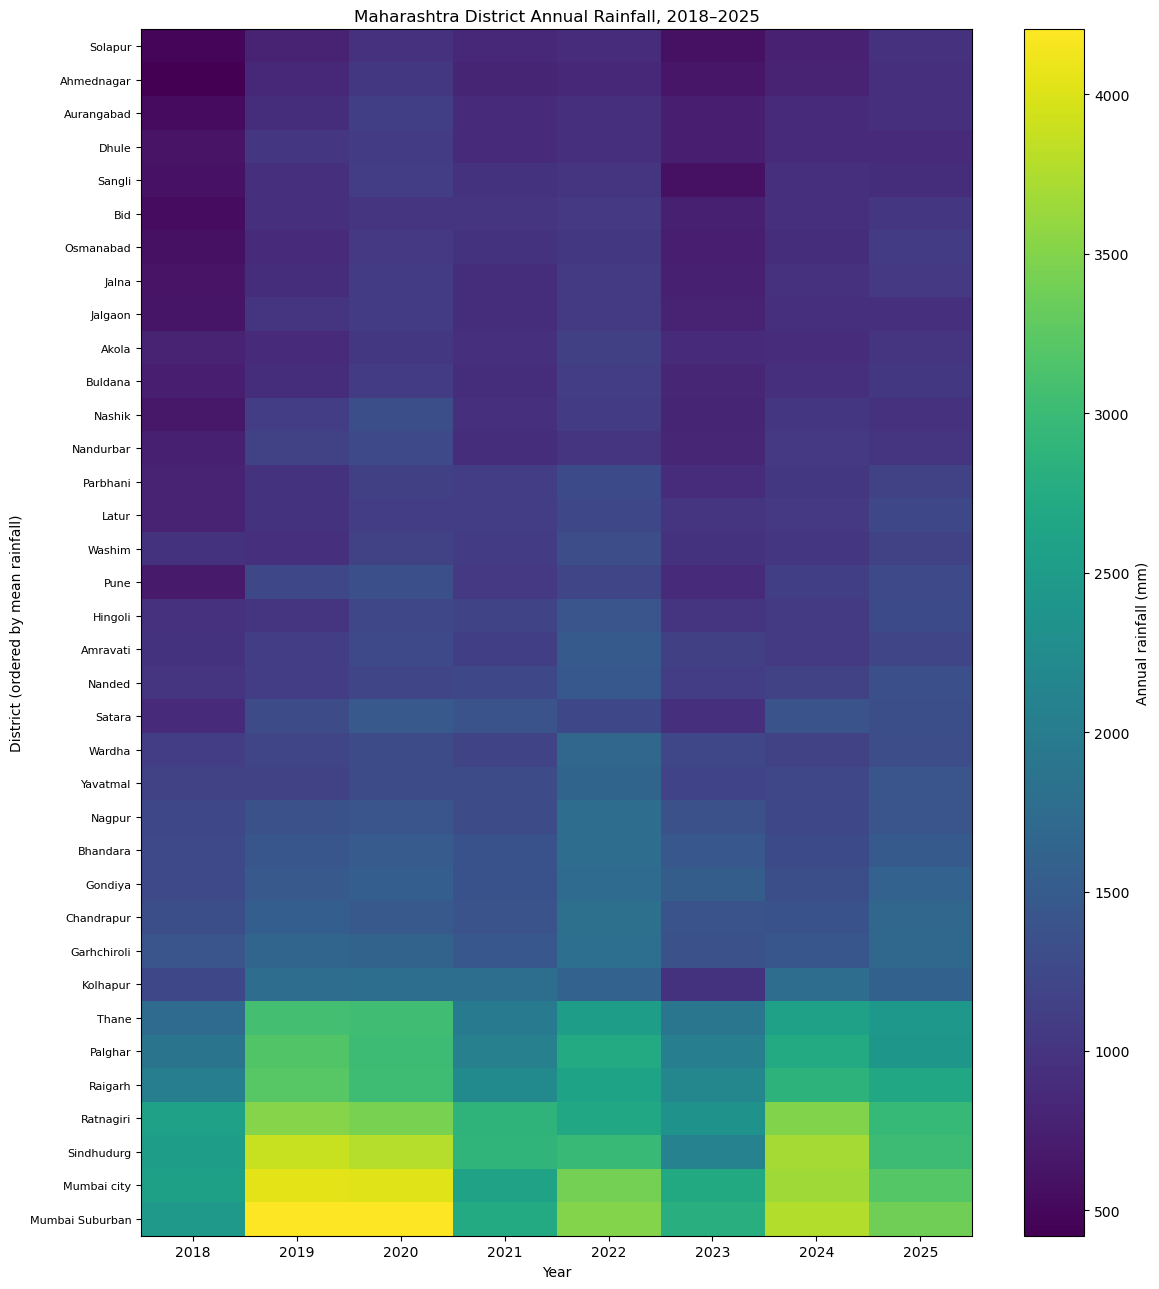

In [14]:

import matplotlib.pyplot as plt

# Districts as rows, years as columns
rainfall_matrix = rainfall.pivot(
    index="district_match",
    columns="year",
    values="annual_mm"
)

# Sort districts by mean rainfall for easier interpretation
rainfall_matrix = rainfall_matrix.loc[
    rainfall_matrix.mean(axis=1).sort_values().index
]

fig, ax = plt.subplots(figsize=(12, 13))

im = ax.imshow(
    rainfall_matrix.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(range(len(rainfall_matrix.columns)))
ax.set_xticklabels(rainfall_matrix.columns.astype(int))
ax.set_yticks(range(len(rainfall_matrix.index)))
ax.set_yticklabels(rainfall_matrix.index, fontsize=8)

ax.set_xlabel("Year")
ax.set_ylabel("District (ordered by mean rainfall)")
ax.set_title("Maharashtra District Annual Rainfall, 2018–2025")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Annual rainfall (mm)")

plt.tight_layout()
plt.show()


## Create a rainfall-indicator dataset

In [15]:

# Create a consolidated rainfall indicator dataset

rainfall_indicators = (
    rainfall_summary
    .merge(
        rainfall_swings[
            ["district_match", "range_mm", "range_pct_of_mean"]
        ],
        on="district_match",
        how="left",
        validate="one_to_one"
    )
    .merge(
        extremes[
            [
                "district_match",
                "wettest_year",
                "wettest_rainfall_mm",
                "driest_year",
                "driest_rainfall_mm"
            ]
        ],
        on="district_match",
        how="left",
        validate="one_to_one"
    )
)

# Add monsoon anomalies and variability indicators
monsoon_indicators = (
    monsoon_data.groupby("district_match")
    .agg(
        mean_monsoon_mm=("monsoon_jun_sep_mm", "mean"),
        monsoon_sd_mm=("monsoon_jun_sep_mm", "std"),
        monsoon_cv_pct=("monsoon_anomaly_pct", "std")
    )
    .reset_index()
)

# Calculate monsoon CV directly from mean and standard deviation
monsoon_indicators["monsoon_cv_pct"] = (
    monsoon_indicators["monsoon_sd_mm"]
    / monsoon_indicators["mean_monsoon_mm"] * 100
)

rainfall_indicators = rainfall_indicators.merge(
    monsoon_indicators[
        ["district_match", "mean_monsoon_mm",
         "monsoon_sd_mm", "monsoon_cv_pct"]
    ],
    on="district_match",
    how="left",
    validate="one_to_one",
    suffixes=("", "_monsoon")
)

# Confirm structure and completeness
print("Dataset shape:", rainfall_indicators.shape)
print("Unique districts:", rainfall_indicators["district_match"].nunique())
print("Duplicate district rows:",
      rainfall_indicators["district_match"].duplicated().sum())
print("Missing values by column:")
print(rainfall_indicators.isna().sum().to_string())

print("\nPreview:")
print(rainfall_indicators.head().round(2).to_string(index=False))

rainfall_indicators.to_csv(
    "jaldrishti_rainfall_indicators_2018_2025.csv",
    index=False
)

print("\nSaved: jaldrishti_rainfall_indicators_2018_2025.csv")


Dataset shape: (36, 19)
Unique districts: 36
Duplicate district rows: 0
Missing values by column:
district_match             0
years_observed             0
mean_annual_mm             0
annual_sd_mm               0
min_annual_mm              0
max_annual_mm              0
mean_monsoon_mm            0
monsoon_sd_mm              0
annual_cv_pct              0
monsoon_cv_pct             0
range_mm                   0
range_pct_of_mean          0
wettest_year               0
wettest_rainfall_mm        0
driest_year                0
driest_rainfall_mm         0
mean_monsoon_mm_monsoon    0
monsoon_sd_mm_monsoon      0
monsoon_cv_pct_monsoon     0

Preview:
district_match  years_observed  mean_annual_mm  annual_sd_mm  min_annual_mm  max_annual_mm  mean_monsoon_mm  monsoon_sd_mm  annual_cv_pct  monsoon_cv_pct  range_mm  range_pct_of_mean  wettest_year  wettest_rainfall_mm  driest_year  driest_rainfall_mm  mean_monsoon_mm_monsoon  monsoon_sd_mm_monsoon  monsoon_cv_pct_monsoon
    Ahmednagar    

## Clean and validate the final rainfall dataset

In [16]:

# Remove redundant columns introduced by the merge
duplicate_columns = [
    "mean_monsoon_mm_monsoon",
    "monsoon_sd_mm_monsoon",
    "monsoon_cv_pct_monsoon"
]

rainfall_indicators_clean = rainfall_indicators.drop(
    columns=duplicate_columns,
    errors="ignore"
).copy()

# Validate key calculations
rainfall_indicators_clean["annual_cv_check"] = (
    rainfall_indicators_clean["annual_sd_mm"]
    / rainfall_indicators_clean["mean_annual_mm"] * 100
)

rainfall_indicators_clean["monsoon_cv_check"] = (
    rainfall_indicators_clean["monsoon_sd_mm"]
    / rainfall_indicators_clean["mean_monsoon_mm"] * 100
)

print("Annual CV calculation matches:",
      (
          rainfall_indicators_clean["annual_cv_pct"]
          - rainfall_indicators_clean["annual_cv_check"]
      ).abs().max() < 0.01)

print("Monsoon CV calculation matches:",
      (
          rainfall_indicators_clean["monsoon_cv_pct"]
          - rainfall_indicators_clean["monsoon_cv_check"]
      ).abs().max() < 0.01)

# Remove temporary verification columns
rainfall_indicators_clean = rainfall_indicators_clean.drop(
    columns=["annual_cv_check", "monsoon_cv_check"]
)

print("\nFinal shape:", rainfall_indicators_clean.shape)
print("Unique districts:",
      rainfall_indicators_clean["district_match"].nunique())
print("Missing values:", rainfall_indicators_clean.isna().sum().sum())
print("Duplicate rows by district:",
      rainfall_indicators_clean["district_match"].duplicated().sum())

rainfall_indicators_clean.to_csv(
    "jaldrishti_rainfall_indicators_2018_2025_clean.csv",
    index=False
)

print("\nSaved: jaldrishti_rainfall_indicators_2018_2025_clean.csv")


Annual CV calculation matches: True
Monsoon CV calculation matches: True

Final shape: (36, 16)
Unique districts: 36
Missing values: 0
Duplicate rows by district: 0

Saved: jaldrishti_rainfall_indicators_2018_2025_clean.csv


## Normalize the rainfall indicators

In [17]:

import pandas as pd

indicators = [
    "annual_cv_pct",
    "monsoon_cv_pct",
    "range_pct_of_mean"
]

# Summary statistics
print("RAINFALL INDICATOR DISTRIBUTIONS")
print(
    rainfall_indicators_clean[indicators]
    .describe()
    .round(2)
    .to_string()
)

# Correlation between indicators
print("\nCORRELATION MATRIX")
print(
    rainfall_indicators_clean[indicators]
    .corr()
    .round(3)
    .to_string()
)

# Check whether annual and monsoon variability rankings differ
ranking_comparison = rainfall_indicators_clean[
    ["district_match"] + indicators
].copy()

ranking_comparison["annual_cv_rank"] = (
    ranking_comparison["annual_cv_pct"]
    .rank(ascending=False, method="min")
)

ranking_comparison["monsoon_cv_rank"] = (
    ranking_comparison["monsoon_cv_pct"]
    .rank(ascending=False, method="min")
)

ranking_comparison["range_rank"] = (
    ranking_comparison["range_pct_of_mean"]
    .rank(ascending=False, method="min")
)

print("\nTOP 10 DISTRICTS BY ANNUAL RAINFALL CV")
print(
    ranking_comparison.sort_values("annual_cv_pct", ascending=False)
    [["district_match", "annual_cv_pct", "annual_cv_rank",
      "monsoon_cv_pct", "monsoon_cv_rank"]]
    .head(10).round(2).to_string(index=False)
)


RAINFALL INDICATOR DISTRIBUTIONS
       annual_cv_pct  monsoon_cv_pct  range_pct_of_mean
count          36.00           36.00              36.00
mean           16.25           15.64              47.91
std             3.75            3.51              11.12
min            10.30           10.22              28.47
25%            13.13           12.43              39.10
50%            16.46           15.65              47.66
75%            19.42           18.58              54.93
max            23.55           21.40              77.40

CORRELATION MATRIX
                   annual_cv_pct  monsoon_cv_pct  range_pct_of_mean
annual_cv_pct              1.000           0.973              0.924
monsoon_cv_pct             0.973           1.000              0.871
range_pct_of_mean          0.924           0.871              1.000

TOP 10 DISTRICTS BY ANNUAL RAINFALL CV
 district_match  annual_cv_pct  annual_cv_rank  monsoon_cv_pct  monsoon_cv_rank
     Ahmednagar          23.55             1.0     

## Select a primary rainfall-variability indicator

In [18]:

# Rank districts by monsoon rainfall variability

rainfall_ranked = rainfall_indicators_clean[
    [
        "district_match",
        "mean_annual_mm",
        "mean_monsoon_mm",
        "annual_cv_pct",
        "monsoon_cv_pct",
        "range_pct_of_mean"
    ]
].copy()

# Higher CV = greater observed relative rainfall variability
rainfall_ranked["monsoon_variability_rank"] = (
    rainfall_ranked["monsoon_cv_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

rainfall_ranked["annual_variability_rank"] = (
    rainfall_ranked["annual_cv_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

rainfall_ranked["rank_difference"] = (
    rainfall_ranked["annual_variability_rank"]
    - rainfall_ranked["monsoon_variability_rank"]
)

print("TOP 10: MONSOON RAINFALL VARIABILITY")
print(
    rainfall_ranked.sort_values("monsoon_cv_pct", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nBOTTOM 10: MONSOON RAINFALL VARIABILITY")
print(
    rainfall_ranked.sort_values("monsoon_cv_pct", ascending=True)
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nLargest absolute difference between annual and monsoon ranks:")
print(
    rainfall_ranked.assign(
        abs_rank_difference=lambda df: df["rank_difference"].abs()
    )
    .sort_values("abs_rank_difference", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

rainfall_ranked.to_csv(
    "jaldrishti_rainfall_variability_rankings.csv",
    index=False
)

print("\nSaved: jaldrishti_rainfall_variability_rankings.csv")


TOP 10: MONSOON RAINFALL VARIABILITY
 district_match  mean_annual_mm  mean_monsoon_mm  annual_cv_pct  monsoon_cv_pct  range_pct_of_mean  monsoon_variability_rank  annual_variability_rank  rank_difference
     Ahmednagar          791.94           623.79          23.55           21.40              77.40                         1                        1                0
          Thane         2413.24          2245.04          20.89           20.76              54.89                         2                        4                2
        Solapur          786.98           560.80          22.22           20.60              61.90                         3                        2               -1
         Sangli          881.12           626.84          21.05           20.48              58.34                         4                        3               -1
     Sindhudurg         3112.98          2774.61          20.46           20.33              57.80                         5    

## Identify districts with lower mean monsoon rainfall and high variability

In [19]:

# Explore the combination of lower mean monsoon rainfall
# and higher relative monsoon variability.

rainfall_profile = rainfall_indicators_clean[
    [
        "district_match",
        "mean_monsoon_mm",
        "monsoon_cv_pct",
        "annual_cv_pct"
    ]
].copy()

# Rank from lower to higher mean monsoon rainfall.
rainfall_profile["monsoon_mean_rank_low_to_high"] = (
    rainfall_profile["mean_monsoon_mm"]
    .rank(ascending=True, method="min")
    .astype(int)
)

# Rank from higher to lower monsoon variability.
rainfall_profile["monsoon_cv_rank_high_to_low"] = (
    rainfall_profile["monsoon_cv_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

print("LOWER MEAN MONSOON RAINFALL")
print(
    rainfall_profile.sort_values("mean_monsoon_mm")
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nLOWER MEAN MONSOON RAINFALL WITH HIGHER VARIABILITY")
print(
    rainfall_profile[
        (rainfall_profile["monsoon_mean_rank_low_to_high"] <= 18)
        & (rainfall_profile["monsoon_cv_rank_high_to_low"] <= 18)
    ]
    .sort_values("monsoon_cv_pct", ascending=False)
    .round(2)
    .to_string(index=False)
)

rainfall_profile.to_csv(
    "jaldrishti_rainfall_mean_vs_variability.csv",
    index=False
)

print("\nSaved: jaldrishti_rainfall_mean_vs_variability.csv")


LOWER MEAN MONSOON RAINFALL
district_match  mean_monsoon_mm  monsoon_cv_pct  annual_cv_pct  monsoon_mean_rank_low_to_high  monsoon_cv_rank_high_to_low
       Solapur           560.80           20.60          22.22                              1                            3
    Ahmednagar           623.79           21.40          23.55                              2                            1
        Sangli           626.84           20.48          21.05                              3                            4
     Osmanabad           693.83           16.37          18.73                              4                           16
           Bid           721.88           16.22          18.55                              5                           17
    Aurangabad           735.59           18.31          20.02                              6                           10
         Jalna           784.81           15.60          17.68                              7                  

In [20]:

# Examine annual rainfall histories for selected districts

focus_districts = [
    "Solapur",
    "Ahmednagar",
    "Sangli",
    "Aurangabad",
    "Nashik",
    "Pune",
    "Dhule"
]

focus_data = rainfall[
    rainfall["district_match"].isin(focus_districts)
].copy()

# Compare each year's rainfall with that district's 2018–2025 mean
focus_data["district_mean_mm"] = (
    focus_data.groupby("district_match")["annual_mm"]
    .transform("mean")
)

focus_data["anomaly_pct"] = (
    (focus_data["annual_mm"] - focus_data["district_mean_mm"])
    / focus_data["district_mean_mm"] * 100
)

focus_data["below_own_mean"] = (
    focus_data["annual_mm"] < focus_data["district_mean_mm"]
)

print("ANNUAL RAINFALL HISTORY")
print(
    focus_data.sort_values(["district_match", "year"])[
        ["district_match", "year", "annual_mm", "anomaly_pct"]
    ].round(2).to_string(index=False)
)

print("\nYEARS BELOW EACH DISTRICT'S OWN 8-YEAR MEAN")
print(
    focus_data.groupby("district_match")
    .agg(
        years_below_mean=("below_own_mean", "sum"),
        years_observed=("year", "nunique"),
        mean_annual_mm=("annual_mm", "mean")
    )
    .reset_index()
    .sort_values("years_below_mean", ascending=False)
    .to_string(index=False)
)


ANNUAL RAINFALL HISTORY
district_match  year  annual_mm  anomaly_pct
    Ahmednagar  2018     420.58       -46.89
    Ahmednagar  2019     839.31         5.98
    Ahmednagar  2020    1033.54        30.51
    Ahmednagar  2021     815.84         3.02
    Ahmednagar  2022     859.60         8.54
    Ahmednagar  2023     643.54       -18.74
    Ahmednagar  2024     797.86         0.75
    Ahmednagar  2025     925.22        16.83
    Aurangabad  2018     527.89       -39.05
    Aurangabad  2019     908.69         4.91
    Aurangabad  2020    1123.08        29.66
    Aurangabad  2021     877.43         1.30
    Aurangabad  2022     932.55         7.67
    Aurangabad  2023     732.50       -15.43
    Aurangabad  2024     888.21         2.55
    Aurangabad  2025     938.90         8.40
         Dhule  2018     626.91       -28.37
         Dhule  2019    1015.05        15.97
         Dhule  2020    1076.28        22.97
         Dhule  2021     872.02        -0.37
         Dhule  2022     938.62

## Measure rainfall deficit magnitude

In [21]:

# Summarize the magnitude and frequency of below-baseline rainfall

deficit_data = rainfall.copy()

deficit_data["district_mean_mm"] = (
    deficit_data.groupby("district_match")["annual_mm"]
    .transform("mean")
)

deficit_data["anomaly_mm"] = (
    deficit_data["annual_mm"] - deficit_data["district_mean_mm"]
)

# Keep only negative anomalies as positive deficit magnitudes.
deficit_data["deficit_mm"] = (
    -deficit_data["anomaly_mm"].clip(upper=0)
)

deficit_summary = (
    deficit_data.groupby("district_match")
    .agg(
        mean_annual_mm=("annual_mm", "mean"),
        years_below_mean=("anomaly_mm", lambda x: (x < 0).sum()),
        total_deficit_mm=("deficit_mm", "sum"),
        largest_single_year_deficit_mm=("deficit_mm", "max")
    )
    .reset_index()
)

# Mean deficit magnitude across all eight years, including zero in
# years that were not below baseline.
deficit_summary["mean_deficit_mm_per_year"] = (
    deficit_summary["total_deficit_mm"] / 8
)

print("TOP 10 BY TOTAL BELOW-MEAN DEFICIT MAGNITUDE")
print(
    deficit_summary.sort_values("total_deficit_mm", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nTOP 10 BY LARGEST SINGLE-YEAR DEFICIT")
print(
    deficit_summary.sort_values(
        "largest_single_year_deficit_mm", ascending=False
    )
    .head(10)
    .round(2)
    .to_string(index=False)
)

deficit_summary.to_csv(
    "jaldrishti_rainfall_deficit_magnitude.csv",
    index=False
)

print("\nSaved: jaldrishti_rainfall_deficit_magnitude.csv")


TOP 10 BY TOTAL BELOW-MEAN DEFICIT MAGNITUDE
 district_match  mean_annual_mm  years_below_mean  total_deficit_mm  largest_single_year_deficit_mm  mean_deficit_mm_per_year
Mumbai Suburban         3379.91                 3           2155.95                          918.74                    269.49
     Sindhudurg         3112.98                 5           2029.41                         1021.14                    253.68
    Mumbai city         3278.86                 4           2027.59                          701.53                    253.45
        Palghar         2507.61                 4           1635.17                          637.27                    204.40
          Thane         2413.24                 3           1616.20                          669.29                    202.03
      Ratnagiri         2988.44                 5           1485.83                          638.30                    185.73
        Raigarh         2604.78                 3           1374.54      

In [22]:
# Find each district's largest negative annual rainfall anomaly

largest_deficit_pct = (
    rainfall_anomalies[rainfall_anomalies["annual_anomaly_pct"] < 0]
    .sort_values("annual_anomaly_pct")
    .groupby("district_match")
    .first()
    .reset_index()
)

largest_deficit_pct = largest_deficit_pct[
    [
        "district_match",
        "year",
        "annual_mm",
        "annual_anomaly_mm",
        "annual_anomaly_pct"
    ]
].rename(columns={
    "year": "worst_below_mean_year",
    "annual_mm": "rainfall_in_worst_year_mm",
    "annual_anomaly_mm": "deficit_vs_mean_mm",
    "annual_anomaly_pct": "deficit_vs_mean_pct"
})

largest_deficit_pct = largest_deficit_pct.sort_values(
    "deficit_vs_mean_pct"
)

print("TOP 10 DISTRICTS BY LARGEST PERCENTAGE RAINFALL DEFICIT")
print(largest_deficit_pct.head(10).round(2).to_string(index=False))

largest_deficit_pct.to_csv(
    "jaldrishti_largest_rainfall_deficit_pct.csv",
    index=False
)

print("\nSaved: jaldrishti_largest_rainfall_deficit_pct.csv")

TOP 10 DISTRICTS BY LARGEST PERCENTAGE RAINFALL DEFICIT
district_match  worst_below_mean_year  rainfall_in_worst_year_mm  deficit_vs_mean_mm  deficit_vs_mean_pct
    Ahmednagar                   2018                     420.58             -371.35               -46.89
       Solapur                   2018                     478.92             -308.06               -39.14
    Aurangabad                   2018                     527.89             -338.26               -39.05
           Bid                   2018                     552.52             -349.98               -38.78
      Kolhapur                   2023                     975.44             -594.61               -37.87
          Pune                   2018                     694.02             -407.49               -36.99
     Osmanabad                   2018                     596.38             -314.36               -34.52
        Nashik                   2018                     661.71             -329.62            

## Inspect the LULC district metadata

In [23]:

# STEP 1: Inspect LULC district boundary metadata

print("Dataset shape:", lulc.shape)

print("\nDistrict count:", lulc["district_match"].nunique())

print("\nDistrict metadata:")
print(
    lulc[
        [
            "ADM2_NAME",
            "ADM2_CODE",
            "STR2_YEAR",
            "EXP2_YEAR",
            "Shape_Area",
            "Shape_Leng",
        ]
    ]
    .sort_values("ADM2_NAME")
    .to_string(index=False)
)

print("\nBoundary metadata summary:")
print(lulc[["STR2_YEAR", "EXP2_YEAR"]].describe(include="all"))

print("\nUnique start years:", sorted(lulc["STR2_YEAR"].dropna().unique()))
print("Unique end years:", sorted(lulc["EXP2_YEAR"].dropna().unique()))


Dataset shape: (35, 26)

District count: 35

District metadata:
      ADM2_NAME  ADM2_CODE  STR2_YEAR  EXP2_YEAR  Shape_Area  Shape_Leng
     Ahmednagar      70178       1000       3000    1.385958   10.551905
          Akola      17758       1997       3000    0.478228    5.068876
       Amravati      17759       1000       3000    1.059938    8.120823
     Aurangabad      17786       1000       3000    0.871360    6.775391
       Bhandara      17761       2000       3000    0.408769    5.978678
            Bid      70179       1000       3000    0.978864    7.759621
        Buldana      17762       1000       3000    0.831676    6.137635
     Chandrapur      17763       1000       3000    0.976878    5.972739
          Dhule      17764       1998       3000    0.623030    5.438669
    Garhchiroli      17765       1000       3000    1.246614    8.323868
        Gondiya      70180       2000       3000    0.403128    4.470254
        Hingoli      70181       2000       3000    0.403500

## check whether the LULC export contains Palghar under another name

In [24]:

# STEP 2: Check district names and codes in the LULC export

print("PALGHAR NAME CHECK")
print(
    lulc[
        lulc["ADM2_NAME"].str.contains("palghar", case=False, na=False)
    ][["ADM2_NAME", "ADM2_CODE"]].to_string(index=False)
)

print("\nTHANE RECORD")
print(
    lulc.loc[
        lulc["ADM2_NAME"].str.contains("thane", case=False, na=False),
        ["ADM2_NAME", "ADM2_CODE", "STR2_YEAR", "EXP2_YEAR",
         "Shape_Area", "Shape_Leng"]
    ].to_string(index=False)
)

print("\nALL DISTRICT NAMES AND CODES")
print(
    lulc[["ADM2_NAME", "ADM2_CODE"]]
    .sort_values("ADM2_NAME")
    .to_string(index=False)
)

print("\nCHECK FOR DUPLICATE DISTRICT CODES")
print("Duplicate codes:", lulc["ADM2_CODE"].duplicated().sum())

print("\nCHECK FOR DUPLICATE DISTRICT NAMES")
print("Duplicate names:", lulc["ADM2_NAME"].duplicated().sum())


PALGHAR NAME CHECK
Empty DataFrame
Columns: [ADM2_NAME, ADM2_CODE]
Index: []

THANE RECORD
ADM2_NAME  ADM2_CODE  STR2_YEAR  EXP2_YEAR  Shape_Area  Shape_Leng
    Thane      17783       1000       3000     0.81175   10.200101

ALL DISTRICT NAMES AND CODES
      ADM2_NAME  ADM2_CODE
     Ahmednagar      70178
          Akola      17758
       Amravati      17759
     Aurangabad      17786
       Bhandara      17761
            Bid      70179
        Buldana      17762
     Chandrapur      17763
          Dhule      17764
    Garhchiroli      17765
        Gondiya      70180
        Hingoli      70181
        Jalgaon      17767
          Jalna      70182
       Kolhapur      17769
          Latur      17770
Mumbai Suburban      70183
    Mumbai city      70184
         Nagpur      17771
         Nanded      17772
      Nandurbar      70185
         Nashik      17773
      Osmanabad      17774
       Parbhani      70186
           Pune      17776
        Raigarh      17777
      Ratnagiri 

## check the original Google Earth Engine export

In [25]:

import ee

districts = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
)

print("Total features:", districts.size().getInfo())

print("First feature properties:")
print(districts.first().toDictionary().getInfo())


EEException: Earth Engine client library not initialized. See http://goo.gle/ee-auth.

## Check whether Palghar exists in the original asset

In [ ]:

# STEP 3: Check district coverage in the original village asset

villages = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
)

maharashtra = villages.filter(
    ee.Filter.eq("state_name", "Maharashtra")
)

district_names = (
    maharashtra
    .aggregate_array("district")
    .distinct()
    .sort()
    .getInfo()
)

print("Unique districts:", len(district_names))
print("\nDistrict names:")
for name in district_names:
    print(name)

print("\nPalghar present:", any(
    "palghar" in str(name).lower()
    for name in district_names
))


## Count villages per district

In [ ]:

# STEP 4: Count source features by district

district_counts = (
    maharashtra
    .aggregate_histogram("district")
    .getInfo()
)

import pandas as pd

district_count_df = pd.DataFrame(
    district_counts.items(),
    columns=["district", "feature_count"]
).sort_values("district")

print("Total districts:", len(district_count_df))
print("Total features:", district_count_df["feature_count"].sum())

print("\nPalghar and Thane:")
print(
    district_count_df[
        district_count_df["district"].str.contains(
            "Palghar|Thane", case=False, na=False
        )
    ].to_string(index=False)
)

print("\nAll district feature counts:")
print(district_count_df.to_string(index=False))


## Inspect the geometry and properties

In [ ]:

# STEP 5: Inspect representative boundary features

check_districts = [
    "Palghar",
    "Thane",
    "Mumbai",
    "Mumbai Suburban"
]

for district_name in check_districts:
    subset = maharashtra.filter(
        ee.Filter.eq("district", district_name)
    )

    feature = ee.Feature(subset.first())

    print(f"\n--- {district_name} ---")
    print("Feature count:", subset.size().getInfo())
    print("Geometry type:", feature.geometry().type().getInfo())

    properties = feature.toDictionary([
        "district",
        "subdistric",
        "sub_distri",
        "village",
        "dtcode",
        "area_id",
        "shape_area",
        "shape_leng"
    ]).getInfo()

    print("Properties:", properties)


## Verify the actual district areas

In [ ]:

# STEP 6: Calculate geographic area from source geometries

check_districts = [
    "Palghar",
    "Thane",
    "Mumbai",
    "Mumbai Suburban"
]

for district_name in check_districts:
    subset = maharashtra.filter(
        ee.Filter.eq("district", district_name)
    )

    # Union all polygons belonging to the district
    district_geometry = subset.geometry()

    area_km2 = district_geometry.area(
        maxError=10
    ).divide(1_000_000).getInfo()

    print(f"{district_name}: {area_km2:,.2f} km²")


## Compare LULC area against source boundary area

In [ ]:

# STEP 7: Compare LULC class area with source boundary area

lulc_area_cols = [
    "bare_ground_km2",
    "built-up_km2",
    "crops_km2",
    "flooded_vegetation_km2",
    "grass_km2",
    "shrub_and_scrub_km2",
    "snow_and_ice_km2",
    "trees_km2",
    "water_km2"
]

lulc_check = lulc.copy()
lulc_check["lulc_total_km2"] = lulc_check[lulc_area_cols].sum(axis=1)

district_pairs = {
    "Palghar": None,
    "Thane": "Thane",
    "Mumbai": "Mumbai city",
    "Mumbai Suburban": "Mumbai Suburban"
}

source_areas = {
    "Palghar": 5273.75,
    "Thane": 4271.32,
    "Mumbai": 75.02,
    "Mumbai Suburban": 420.68
}

results = []

for source_name, lulc_name in district_pairs.items():
    if lulc_name is None:
        lulc_area = None
    else:
        match = lulc_check[
            lulc_check["district_match"].str.casefold()
            == lulc_name.casefold()
        ]
        lulc_area = (
            float(match["lulc_total_km2"].iloc[0])
            if not match.empty else None
        )

    source_area = source_areas[source_name]

    results.append({
        "district": source_name,
        "source_area_km2": source_area,
        "lulc_area_km2": lulc_area,
        "lulc_minus_source_km2": (
            lulc_area - source_area if lulc_area is not None else None
        ),
        "lulc_to_source_ratio": (
            lulc_area / source_area if lulc_area is not None else None
        )
    })

comparison = pd.DataFrame(results)

print(comparison.round(3).to_string(index=False))


## Inspect the original LULC calculation

In [ ]:
# Dataset reference: Google Dynamic World V1
# This is a catalogue ID, not a Python expression.
# Collection use appears in the Earth Engine cells below.

## Check whether your LULC CSV can be traced to its export source

In [26]:

from pathlib import Path

project_folder = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

print("Python scripts:")
for file in project_folder.rglob("*.py"):
    print(file)

print("\nNotebook files:")
for file in project_folder.rglob("*.ipynb"):
    print(file)


Python scripts:

Notebook files:
C:\Users\MITALI SALHOTRA\JalDrishti-AI\01_Sentinel2_Optical_Processing.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Google_Engine_Satelite_images.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\JalDrishti_Data_Validation.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\JalDrishti_Data_Validation_Step1_Cleaned.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Sentinel-1 processing.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Sentinel-2_Maharstra.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Sentinel2_Data_Extraction.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Sentinel2_India_Processing.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Setinal_haryana_processing.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\Watershed_boundaries.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\.ipynb_checkpoints\01_Sentinel2_Optical_Processing-checkpoint.ipynb
C:\Users\MITALI SALHOTRA\JalDrishti-AI\.ipynb_checkpoints\Google_Engine_Satelite_images-checkpoint.ipynb
C:\Users\MITALI SALHOTRA\JalDri

## Find the exact LULC export cell

In [27]:

from pathlib import Path
import json

project_folder = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

keywords = [
    "dynamicworld",
    "dynamic world",
    "pixelarea",
    "reduceregions",
    "maharashtra_lulc_area_2023",
    "export.table"
]

for notebook_path in project_folder.glob("*.ipynb"):
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for cell_number, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        if any(keyword in source.lower() for keyword in keywords):
            print(f"\n{'=' * 65}")
            print(f"Notebook: {notebook_path.name}")
            print(f"Cell: {cell_number}")
            print("-" * 65)
            print(source[:4000])



Notebook: 01_Sentinel2_Optical_Processing.ipynb
Cell: 71
-----------------------------------------------------------------
haryana_watershed_ndvi = ndvi.reduceRegions(
    collection=haryana_watersheds,
    reducer=ee.Reducer.mean(),
    scale=1000,
    tileScale=4
)

print("Haryana watershed NDVI calculation created!")

Notebook: 01_Sentinel2_Optical_Processing.ipynb
Cell: 77
-----------------------------------------------------------------
haryana_ndvi = ndvi.reduceRegions(
    collection=haryana_watersheds_small,
    reducer=ee.Reducer.mean().setOutputs(["NDVI"]),
    scale=1000,
    tileScale=4
)

print("Haryana NDVI table created!")

Notebook: 01_Sentinel2_Optical_Processing.ipynb
Cell: 81
-----------------------------------------------------------------
haryana_ndwi = ndwi.reduceRegions(
    collection=haryana_watersheds_small,
    reducer=ee.Reducer.mean().setOutputs(["NDWI"]),
    scale=1000,
    tileScale=4
)

print("Haryana NDWI table created!")

Notebook: 01_Sentinel2_Optic

## Verify the Dynamic World 2023 data

In [28]:

# STEP 9: Verify Dynamic World data availability for 2023

import ee

ee.Initialize(project="jaldrishti-508107")

dynamic_world = ee.ImageCollection(
    "GOOGLE/DYNAMICWORLD/V1"
).filterDate("2023-01-01", "2024-01-01")

print("Dynamic World images in 2023:", dynamic_world.size().getInfo())

first_image = ee.Image(dynamic_world.first())

print("\nAvailable image bands:")
print(first_image.bandNames().getInfo())

print("\nFirst image date:")
print(
    ee.Date(first_image.get("system:time_start"))
    .format("YYYY-MM-dd")
    .getInfo()
)


Dynamic World images in 2023: 1890663

Available image bands:
['water', 'trees', 'grass', 'flooded_vegetation', 'crops', 'shrub_and_scrub', 'built', 'bare', 'snow_and_ice', 'label']

First image date:
2023-01-01


## Prepare the Maharashtra district boundaries

In [29]:

# STEP 10: Build district geometries from the source village asset

import ee

ee.Initialize(project="jaldrishti-508107")

villages = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
).filter(
    ee.Filter.eq("state_name", "Maharashtra")
)

district_names = (
    villages.aggregate_array("district")
    .distinct()
    .sort()
)

district_names_list = district_names.getInfo()

print("Districts found:", len(district_names_list))
print(district_names_list)

def make_district_feature(name):
    subset = villages.filter(ee.Filter.eq("district", name))
    geometry = subset.geometry(maxError=10)

    return ee.Feature(
        geometry,
        {
            "district": name,
            "source_feature_count": subset.size()
        }
    )

district_boundaries = ee.FeatureCollection(
    district_names.map(make_district_feature)
)

print(
    "\nDissolved district count:",
    district_boundaries.size().getInfo()
)

print(
    "Palghar boundary found:",
    district_boundaries
    .filter(ee.Filter.eq("district", "Palghar"))
    .size()
    .getInfo() == 1
)


Districts found: 36
['Ahmednagar', 'Akola', 'Amravati', 'Aurangabad', 'Beed', 'Bhandara', 'Buldhana', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Gondia', 'Hingoli', 'Jalgaon', 'Jalna', 'Kolhapur', 'Latur', 'Mumbai', 'Mumbai Suburban', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Palghar', 'Parbhani', 'Pune', 'Raigad', 'Ratnagiri', 'Sangli', 'Satara', 'Sindhudurg', 'Solapur', 'Thane', 'Wardha', 'Washim', 'Yavatmal']

Dissolved district count: 36
Palghar boundary found: True


## Check a small sample of the 2023 collection

In [30]:

# STEP 11A: Lightweight Dynamic World availability check

import ee

ee.Initialize(project="jaldrishti-508107")

dynamic_world_2023 = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2023-01-01", "2024-01-01")
    .filterBounds(
        ee.Feature(
            district_boundaries
            .filter(ee.Filter.eq("district", "Palghar"))
            .first()
        ).geometry()
    )
)

sample_images = dynamic_world_2023.limit(10)

print("Sample image count:", sample_images.size().getInfo())

print(
    "Sample dates:",
    sample_images.aggregate_array("system:time_start")
    .map(lambda t: ee.Date(t).format("YYYY-MM-dd"))
    .getInfo()
)


Sample image count: 10
Sample dates: ['2023-01-02', '2023-01-02', '2023-01-02', '2023-01-02', '2023-01-02', '2023-01-02', '2023-01-04', '2023-01-04', '2023-01-07', '2023-01-07']


## Build a Palghar-only land-cover composite

## Calculate Palghar's nine land-cover class areas

In [31]:

# FAST VERSION: Calculate all 9 land-cover class areas in one request

class_names = [
    "water_km2",
    "trees_km2",
    "grass_km2",
    "flooded_vegetation_km2",
    "crops_km2",
    "shrub_and_scrub_km2",
    "built-up_km2",
    "bare_ground_km2",
    "snow_and_ice_km2"
]

area_images = ee.Image.cat([
    ee.Image.pixelArea()
    .divide(1_000_000)
    .updateMask(palghar_lulc.eq(class_id))
    .rename(class_names[class_id])
    for class_id in range(9)
])

result = area_images.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=palghar_boundary.geometry(),
    scale=10,
    maxPixels=1e10,
    tileScale=8
).getInfo()

for name in class_names:
    print(f"{name}: {result.get(name, 0):,.2f} km²")

print(
    "\nTotal mapped area:",
    round(sum(result.get(name, 0) or 0 for name in class_names), 2),
    "km²"
)


NameError: name 'palghar_lulc' is not defined

In [ ]:

# STEP 12: Lightweight diagnostic at 100 m

palghar_label_100m = palghar_lulc.reproject(
    crs="EPSG:6933",
    scale=100
)

area_image_100m = ee.Image.pixelArea().divide(1_000_000)

palghar_total_area = area_image_100m.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=palghar_boundary.geometry(),
    scale=100,
    crs="EPSG:6933",
    maxPixels=1e9,
    tileScale=4
)

print(
    "Source boundary area (km²):",
    palghar_boundary.geometry()
    .area(maxError=100)
    .divide(1_000_000)
    .getInfo()
)

print(
    "Area calculation object prepared successfully."
)


## Prepare the export without running it yet

In [ ]:

# STEP 13: Check batch export support

import ee

ee.Initialize(project="jaldrishti-508107")

print("Earth Engine initialized.")

print(
    "Districts available:",
    district_boundaries.size().getInfo()
)

print(
    "Batch export API available:",
    hasattr(ee.batch, "Export")
)


## Prepare the export task

In [ ]:

# STEP 14: PREPARE the 2023 Dynamic World LULC export
# This cell does NOT start the export.
# Do not replace your existing CSV with the new output yet.

import ee

ee.Initialize(project="jaldrishti-508107")

# Use the verified 36-district source asset
villages = (
    ee.FeatureCollection(
        "projects/jaldrishti-508107/assets/maharashtra_villages"
    )
    .filter(ee.Filter.eq("state_name", "Maharashtra"))
)

district_names = (
    villages.aggregate_array("district")
    .distinct()
    .sort()
)

district_boundaries = ee.FeatureCollection(
    district_names.map(
        lambda name: ee.Feature(
            villages
            .filter(ee.Filter.eq("district", name))
            .geometry(maxError=10),
            {"district": name}
        )
    )
)

# Build a 2023 mode composite of Dynamic World labels
dw_2023 = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2023-01-01", "2024-01-01")
    .filterBounds(district_boundaries.geometry())
    .select("label")
)

lulc_label_2023 = (
    dw_2023
    .reduce(ee.Reducer.mode())
    .rename("label")
    .toInt()
)

# Dynamic World class IDs: 0 through 8
class_names = [
    "water_km2",
    "trees_km2",
    "grass_km2",
    "flooded_vegetation_km2",
    "crops_km2",
    "shrub_and_scrub_km2",
    "built-up_km2",
    "bare_ground_km2",
    "snow_and_ice_km2"
]

# Create one area band per land-cover class
area_bands = ee.Image.cat([
    ee.Image.pixelArea()
    .divide(1_000_000)
    .updateMask(lulc_label_2023.eq(class_id))
    .rename(class_names[class_id])
    for class_id in range(9)
])

# Calculate all classes per district in one server-side operation
lulc_results = area_bands.reduceRegions(
    collection=district_boundaries,
    reducer=ee.Reducer.sum(),
    scale=100,
    crs="EPSG:6933",
    tileScale=8
)

# Rename sum fields and keep district name + class areas
def format_feature(feature):
    feature = ee.Feature(feature)
    props = ee.Dictionary({"district": feature.get("district")})

    for class_name in class_names:
        props = props.set(
            class_name,
            feature.get(class_name)
        )

    return ee.Feature(None, props)

lulc_export = lulc_results.map(format_feature)

# Prepare a batch export to Google Drive.
# Scale is 100 m for a first validation run, not final 10 m data.
task = ee.batch.Export.table.toDrive(
    collection=lulc_export,
    description="JalDrishti_LULC_2023_Validation_100m",
    folder="JalDrishti",
    fileNamePrefix="jaldrishti_lulc_2023_validation_100m",
    fileFormat="CSV",
    selectors=["district"] + class_names
)

print("Export task prepared, NOT started.")
print("Output: Google Drive / JalDrishti/")
print("File: jaldrishti_lulc_2023_validation_100m.csv")
print("Scale: 100 metres — initial validation only.")


## Start the validation export

In [ ]:

# Start the prepared Earth Engine batch export

task.start()

print("Export task submitted.")
print("Task ID:", task.id)
print("Initial status:", task.status())


In [ ]:

# Check the current status of the LULC export

status = task.status()

print("Export status:", status["state"])
print("Task ID:", task.id)

if status["state"] == "COMPLETED":
    print("Export finished! Check Google Drive > JalDrishti.")
elif status["state"] == "READY":
    print("Task is queued and waiting to run.")
elif status["state"] == "RUNNING":
    print("Export is currently processing.")
elif status["state"] == "FAILED":
    print("Export failed:", status.get("error_message", "Check task details."))


In [ ]:

# Prepare a corrected export task — does NOT start it

task_fixed = ee.batch.Export.table.toDrive(
    collection=lulc_export,
    description="JalDrishti_LULC_2023_Validation_100m_v2",
    folder="JalDrishti",
    fileNamePrefix="jaldrishti_lulc_2023_validation_100m_v2",
    fileFormat="CSV",
    selectors=["district"] + class_names
)

print("Corrected export task prepared, NOT started.")
print("Task ID:", task_fixed.id)


In [ ]:

# Rebuild the land-cover area calculation with an explicit CRS

area_bands_fixed = ee.Image.cat([
    ee.Image.pixelArea()
    .divide(1_000_000)
    .updateMask(lulc_label_2023.eq(class_id))
    .rename(class_names[class_id])
    for class_id in range(9)
]).setDefaultProjection(
    crs="EPSG:4326",
    scale=100
)

lulc_results_fixed = area_bands_fixed.reduceRegions(
    collection=district_boundaries,
    reducer=ee.Reducer.sum(),
    scale=100,
    crs="EPSG:4326",
    tileScale=8
)

print("Rebuilt area calculation.")
print("District count:", lulc_results_fixed.size().getInfo())


In [ ]:

# STEP 15: Lightweight single-district test

palghar_boundary = ee.Feature(
    district_boundaries
    .filter(ee.Filter.eq("district", "Palghar"))
    .first()
)

# Limit the collection to Palghar and use a smaller image stack
palghar_dw = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2023-01-01", "2024-01-01")
    .filterBounds(palghar_boundary.geometry())
    .select("label")
)

# Use only the first 30 observations for a diagnostic test
palghar_sample = palghar_dw.limit(30)

palghar_mode_test = (
    palghar_sample
    .reduce(ee.Reducer.mode())
    .rename("label")
)

print("Single-district test image prepared.")
print("District:", "Palghar")
print("Sample size:", palghar_sample.size().getInfo())


In [ ]:

# Check recent Earth Engine export tasks

tasks = ee.batch.Task.list()

for t in tasks[:10]:
    status = t.status()
    print(
        status.get("description"),
        "|",
        status.get("state"),
        "|",
        status.get("id")
    )


In [ ]:

# Inspect the completed 2021 village-level land-cover export

tasks = ee.batch.Task.list()

for t in tasks:
    status = t.status()
    if status.get("description") == "JalDrishti_Maharashtra_Village_LandCover_2021":
        print("Description:", status.get("description"))
        print("State:", status.get("state"))
        print("Task ID:", status.get("id"))
        print("Task type:", status.get("task_type"))
        print("Destination:", status.get("destination_uris"))
        print("Error:", status.get("error_message"))


### Windows PowerShell command (run in a PowerShell terminal, not a Python code cell)

```powershell
Get-ChildItem -Recurse -Filter "maharashtra_village_landcover_2021.csv" | Select-Object FullName, Length
```

In [ ]:
from pathlib import Path

project_folder = Path.cwd()

files = list(project_folder.rglob("maharashtra_village_landcover_2021.csv"))

if files:
    for file in files:
        print("File found:", file)
else:
    print("File not found in the current project folder.")

In [ ]:
from pathlib import Path

drive_paths = [
    Path("G:/My Drive/JalDrishti_AI"),
    Path.home() / "Google Drive" / "My Drive" / "JalDrishti_AI",
    Path.home() / "My Drive" / "JalDrishti_AI",
]

for path in drive_paths:
    print(f"{'FOUND' if path.exists() else 'Not found'}: {path}")

In [ ]:
import ee

ee.Initialize(project="jaldrishti-508107")

for task in ee.batch.Task.list():
    status = task.status()
    description = status.get("description", "")

    if "LandCover_2021" in description or "LULC" in description:
        print(
            "Task:", description,
            "| Status:", status.get("state"),
            "| ID:", status.get("id")
        )

In [ ]:
import ee

ee.Initialize(project="jaldrishti-508107")

for task in ee.batch.Task.list():
    status = task.status()

    if status.get("id") == "AQXGBPE55VQDNCNUTAU7U6ZZ":
        print("Full export status:")
        for key, value in status.items():
            print(f"{key}: {value}")

In [ ]:
import ee

for task in ee.batch.Task.list():
    status = task.status()

    if status.get("id") == "AQXGBPE55VQDNCNUTAU7U6ZZ":
        print("State:", status.get("state"))
        print("Description:", status.get("description"))
        print("Destination:", status.get("destination_uris"))
        print("Error:", status.get("error_message", "No error reported"))

In [ ]:
print("Existing land-cover variables:")

for name in sorted(globals()):
    if any(word in name.lower() for word in ["landcover", "land_cover", "lulc", "landcover2021"]):
        value = globals()[name]
        print(f"{name}: {type(value).__name__}")

In [ ]:
print("LULC DataFrame shape:", lulc.shape)
print("\nColumns:")
print(lulc.columns.tolist())

print("\nFirst 5 rows:")
display(lulc.head())

print("\nExisting CSV path:", lulc_path)
print("File exists:", lulc_path.exists())

In [ ]:
from pathlib import Path
from IPython.display import FileLink, display
import shutil

source = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI\maharashtra_lulc_area_2023.csv")
output = Path.cwd() / "maharashtra_lulc_area_2023_download.csv"

if source.exists():
    shutil.copy2(source, output)
    print("CSV copy created successfully!")
    print("File size:", round(output.stat().st_size / 1024, 2), "KB")
    display(FileLink(str(output)))
else:
    print("Source CSV not found:", source)

In [ ]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\MITALI SALHOTRA\JalDrishti-AI"
    r"\maharashtra_lulc_area_2023_with_area_totals.csv"
)

if file_path.exists():
    lulc_updated = pd.read_csv(file_path)

    print("Shape:", lulc_updated.shape)
    print("District column:", "ADM2_NAME" in lulc_updated.columns)
    print("Palghar present:",
          lulc_updated["ADM2_NAME"].astype(str).str.strip().str.lower()
          .eq("palghar").any())

    print("\nDistrict area summary:")
    display(
        lulc_updated[
            ["ADM2_NAME", "total_classified_lulc_area_km2",
             "lulc_area_difference_from_shape_km2"]
        ].tail(8)
    )
else:
    print("File not found locally. Download it from Drive into your project folder first.")

In [ ]:
import pandas as pd

class_cols = [
    "bare_ground_km2",
    "built-up_km2",
    "crops_km2",
    "flooded_vegetation_km2",
    "grass_km2",
    "shrub_and_scrub_km2",
    "snow_and_ice_km2",
    "trees_km2",
    "water_km2"
]

check = lulc.copy()

check["class_total_km2"] = check[class_cols].sum(axis=1)
check["Shape_Area"] = pd.to_numeric(
    check["Shape_Area"], errors="coerce"
)

check["area_ratio"] = (
    check["class_total_km2"] / check["Shape_Area"]
)

print("Districts:", len(check))
print("\nArea mismatch — largest ratios first:")

display(
    check[
        ["ADM2_NAME", "Shape_Area", "class_total_km2", "area_ratio"]
    ]
    .sort_values("area_ratio", ascending=False)
    .head(10)
    .round(3)
)

In [ ]:
print("LULC source columns:")
print(lulc.columns.tolist())

print("\nArea and boundary metadata:")
metadata_cols = [
    c for c in [
        "ADM2_NAME", "ADM2_CODE", "STR2_YEAR",
        "EXP2_YEAR", "Shape_Area", "Shape_Leng", ".geo"
    ]
    if c in lulc.columns
]

display(lulc[metadata_cols].head(10))

print("\nShape_Area statistics:")
print(lulc["Shape_Area"].describe())

In [ ]:
print("Available metadata columns:")
print([
    c for c in lulc.columns
    if any(k in c.lower() for k in [
        "area", "shape", "geometry", "geo", "year", "code"
    ])
])

print("\nSample geometry field:")
if ".geo" in lulc.columns:
    print(lulc[".geo"].iloc[0])

print("\nFirst five district area records:")
display(
    lulc[["ADM2_NAME", "Shape_Area", "Shape_Leng"]]
    .head()
)

In [ ]:
import json
import pandas as pd
from pyproj import Geod

geod = Geod(ellps="WGS84")

def geometry_area_km2(geo_text):
    if pd.isna(geo_text):
        return None

    geometry = json.loads(geo_text)
    geom_type = geometry["type"]
    coords = geometry["coordinates"]

    if geom_type == "Polygon":
        area, _ = geod.geometry_area_perimeter(
            __import__("shapely.geometry", fromlist=["shape"])
            .shape(geometry)
        )
        return abs(area) / 1_000_000

    elif geom_type == "MultiPolygon":
        shape = __import__("shapely.geometry", fromlist=["shape"]).shape(geometry)
        area, _ = geod.geometry_area_perimeter(shape)
        return abs(area) / 1_000_000

    return None

area_check = lulc[["ADM2_NAME", "Shape_Area", ".geo"]].copy()
area_check["geometry_area_km2"] = area_check[".geo"].apply(
    geometry_area_km2
)
area_check["class_total_km2"] = lulc[class_cols].sum(axis=1)
area_check["class_to_geometry_ratio"] = (
    area_check["class_total_km2"] / area_check["geometry_area_km2"]
)

display(
    area_check[
        ["ADM2_NAME", "Shape_Area", "geometry_area_km2",
         "class_total_km2", "class_to_geometry_ratio"]
    ].sort_values("class_to_geometry_ratio", ascending=False).head(10).round(3)
)

In [ ]:
print("LULC source columns:")
print(lulc.columns.tolist())

print("\nArea and boundary metadata:")
metadata_cols = [
    c for c in [
        "ADM2_NAME", "ADM2_CODE", "STR2_YEAR",
        "EXP2_YEAR", "Shape_Area", "Shape_Leng", ".geo"
    ]
    if c in lulc.columns
]

display(lulc[metadata_cols].head(10))

print("\nShape_Area statistics:")
print(lulc["Shape_Area"].describe())

In [ ]:
print("Geometry column available:", ".geo" in lulc.columns)

if ".geo" in lulc.columns:
    print("\nFirst geometry value:")
    print(str(lulc[".geo"].iloc[0])[:500])

print("\nGeometry libraries:")
for package in ["shapely", "pyproj"]:
    try:
        module = __import__(package)
        print(package, "available", getattr(module, "__version__", ""))
    except ImportError:
        print(package, "NOT installed")

## calculate the actual district areas

In [ ]:
import json
import pandas as pd
from shapely.geometry import shape
from pyproj import Geod

geod = Geod(ellps="WGS84")

def calculate_area_km2(geo_text):
    if pd.isna(geo_text):
        return None

    geometry = shape(json.loads(geo_text))
    area_m2, _ = geod.geometry_area_perimeter(geometry)
    return abs(area_m2) / 1_000_000

area_check = lulc[["ADM2_NAME", "Shape_Area", ".geo"]].copy()

area_check["geometry_area_km2"] = (
    area_check[".geo"].apply(calculate_area_km2)
)

area_check["class_total_km2"] = lulc[class_cols].sum(axis=1)

area_check["class_to_geometry_ratio"] = (
    area_check["class_total_km2"] /
    area_check["geometry_area_km2"]
)

display(
    area_check[
        [
            "ADM2_NAME",
            "Shape_Area",
            "geometry_area_km2",
            "class_total_km2",
            "class_to_geometry_ratio"
        ]
    ]
    .sort_values("class_to_geometry_ratio", ascending=False)
    .head(10)
    .round(3)
)

In [ ]:
area_check["area_difference_km2"] = (
    area_check["class_total_km2"]
    - area_check["geometry_area_km2"]
).abs()

print(
    "Largest absolute area difference (km²):",
    round(area_check["area_difference_km2"].max(), 6)
)

print("\nDistricts with differences above 1 km²:")
display(
    area_check.loc[
        area_check["area_difference_km2"] > 1,
        [
            "ADM2_NAME",
            "geometry_area_km2",
            "class_total_km2",
            "area_difference_km2"
        ]
    ]
)

print(
    "\nTotal geometry area (35 districts):",
    round(area_check["geometry_area_km2"].sum(), 3),
    "km²"
)

print(
    "Total classified area (35 districts):",
    round(area_check["class_total_km2"].sum(), 3),
    "km²"
)

## check the missing Palghar district

In [ ]:
rainfall_districts = set(rainfall["district_match"].dropna().unique())
lulc_districts = set(lulc["district_match"].dropna().unique())

print("Rainfall districts:", len(rainfall_districts))
print("LULC districts:", len(lulc_districts))

print("\nDistricts missing from LULC:")
print(sorted(rainfall_districts - lulc_districts))

print("\nDistricts present only in LULC:")
print(sorted(lulc_districts - rainfall_districts))

In [ ]:
import ee

ee.Initialize(project="jaldrishti-508107")

villages = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
).filter(
    ee.Filter.eq("state_name", "Maharashtra")
)

palghar_villages = villages.filter(
    ee.Filter.eq("district", "Palghar")
)

print("Palghar boundary features:", palghar_villages.size().getInfo())

print(
    "Palghar boundary area (km²):",
    round(
        palghar_villages.geometry(maxError=10)
        .area(maxError=100)
        .divide(1_000_000)
        .getInfo(),
        3
    )
)

In [ ]:
import ee

ee.Initialize(project="jaldrishti-508107")

# Existing Palghar boundary and 2023 Dynamic World composite
palghar_boundary = ee.Feature(
    district_boundaries
    .filter(ee.Filter.eq("district", "Palghar"))
    .first()
)

class_names = {
    0: "water_km2",
    1: "trees_km2",
    2: "grass_km2",
    3: "flooded_vegetation_km2",
    4: "crops_km2",
    5: "shrub_and_scrub_km2",
    6: "built-up_km2",
    7: "bare_ground_km2",
    8: "snow_and_ice_km2",
}

# Calculate area per class from the existing annual mode composite
area_images = []

for class_id, column_name in class_names.items():
    area_images.append(
        ee.Image.pixelArea()
        .updateMask(palghar_lulc.eq(class_id))
        .rename(column_name)
    )

area_image = ee.Image.cat(area_images)

area_stats = area_image.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=palghar_boundary.geometry(),
    scale=100,
    maxPixels=1e13,
    tileScale=8
)

palghar_result = ee.Feature(
    None,
    area_stats
).set({
    "district": "Palghar",
    "year": 2023,
    "analysis_scale_m": 100,
    "boundary_area_km2": 5273.745
})

palghar_export = ee.batch.Export.table.toDrive(
    collection=ee.FeatureCollection([palghar_result]),
    description="JalDrishti_Palghar_LULC_2023_100m",
    folder="JalDrishti_AI",
    fileNamePrefix="maharashtra_palghar_lulc_area_2023",
    fileFormat="CSV"
)

print("Palghar export prepared.")
print("Analysis scale: 100 m")
print("Destination folder name: JalDrishti_AI")
print("Export has NOT been started.")

In [ ]:
palghar_export.start()

print("Export task started.")
print("Task ID:", palghar_export.id)
print("Initial status:", palghar_export.status().get("state"))


In [ ]:
import ee

for task in ee.batch.Task.list():
    status = task.status()

    if status.get("id") == "3SPOXJZR4SRBG6Q7P2YETVUK":
        print("Task:", status.get("description"))
        print("Status:", status.get("state"))
        print("Error:", status.get("error_message", "None"))
        print("Destination:", status.get("destination_uris"))

In [ ]:
for task in ee.batch.Task.list():
    status = task.status()

    if status.get("id") == "3SPOXJZR4SRBG6Q7P2YETVUK":
        print("Status:", status.get("state"))
        print("Error:", status.get("error_message", "None"))
        print("Destination:", status.get("destination_uris"))

In [ ]:
for task in ee.batch.Task.list():
    status = task.status()

    if status.get("id") == "3SPOXJZR4SRBG6Q7P2YETVUK":
        print("Status:", status.get("state"))
        print("Error:", status.get("error_message", "None"))

In [ ]:
for task in ee.batch.Task.list():
    status = task.status()

    if status.get("id") == "3SPOXJZR4SRBG6Q7P2YETVUK":
        print("Status:", status.get("state"))
        print("Destination:", status.get("destination_uris"))
        print("Error:", status.get("error_message", "None"))

In [ ]:
import pandas as pd
from pathlib import Path

file_path = Path(
    r"C:\Users\MITALI SALHOTRA\JalDrishti-AI"
    r"\maharashtra_palghar_lulc_area_2023.csv"
)

if file_path.exists():
    palghar_check = pd.read_csv(file_path)

    print("Shape:", palghar_check.shape)
    print("\nColumns:", palghar_check.columns.tolist())
    display(palghar_check)
else:
    print("CSV not found locally yet. Please check the download.")

In [ ]:
# Inspect Thane's existing LULC area validation
class_cols = [
    "bare_ground_km2",
    "built-up_km2",
    "crops_km2",
    "flooded_vegetation_km2",
    "grass_km2",
    "shrub_and_scrub_km2",
    "snow_and_ice_km2",
    "trees_km2",
    "water_km2"
]

thane_lulc = lulc[
    lulc["ADM2_NAME"].astype(str).str.strip().str.lower() == "thane"
]

thane_check = area_check[
    area_check["ADM2_NAME"].astype(str).str.strip().str.lower() == "thane"
]

print("THANE — ORIGINAL LULC DATA")
print(thane_lulc[["ADM2_NAME", "Shape_Area"] + class_cols].to_string(index=False))

print("\nTHANE — GEOMETRY AREA VALIDATION")
print(thane_check[
    ["ADM2_NAME", "geometry_area_km2",
     "class_total_km2", "class_to_geometry_ratio",
     "area_difference_km2"]
].to_string(index=False))

In [ ]:
# Check area consistency across all LULC districts

area_check["absolute_difference_km2"] = (
    area_check["class_total_km2"]
    - area_check["geometry_area_km2"]
).abs()

print("Total LULC districts:", len(area_check))
print(
    "Districts with difference > 1 km²:",
    (area_check["absolute_difference_km2"] > 1).sum()
)

print("\nLargest discrepancies:")
print(
    area_check[
        [
            "ADM2_NAME",
            "geometry_area_km2",
            "class_total_km2",
            "absolute_difference_km2",
            "class_to_geometry_ratio"
        ]
    ]
    .sort_values("absolute_difference_km2", ascending=False)
    .head(10)
    .to_string(index=False)
)

In [ ]:
# Validate the district boundary collection

print("Number of district boundary features:",
      district_boundaries.size().getInfo())

boundary_area_image = ee.Image.pixelArea().rename("area_m2")

boundary_area_result = boundary_area_image.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=district_boundaries.geometry(maxError=10),
    scale=1000,
    maxPixels=1e13,
    tileScale=4
)

print("Combined boundary area (km²):",
      boundary_area_result.get("area_m2").getInfo() / 1_000_000)

print("\nDistrict names:")
print(district_boundaries.aggregate_array("district").distinct().sort().getInfo())

In [ ]:
import pandas as pd

# Calculate the area of each district boundary in km²
def add_boundary_area(feature):
    area_km2 = feature.geometry().area(maxError=10).divide(1_000_000)
    return feature.set("boundary_area_km2", area_km2)

district_areas_fc = district_boundaries.map(add_boundary_area)

boundary_data = district_areas_fc.reduceColumns(
    reducer=ee.Reducer.toList(2),
    selectors=["district", "boundary_area_km2"]
).get("list").getInfo()

boundary_areas = pd.DataFrame(
    boundary_data,
    columns=["district", "boundary_area_km2"]
)

# Standardize known naming differences before comparison
name_mapping = {
    "Raigad": "Raigarh",
    "Aurangabad": "Aurangabad",
    "Beed": "Bid",
    "Osmanabad": "Osmanabad"
}

boundary_areas["district_match"] = (
    boundary_areas["district"].replace(name_mapping)
)

lulc_areas = area_check[
    ["ADM2_NAME", "geometry_area_km2", "class_total_km2"]
].copy()

lulc_areas["district_match"] = lulc_areas["ADM2_NAME"].str.strip()

comparison = boundary_areas.merge(
    lulc_areas,
    on="district_match",
    how="left",
    indicator=True
)

comparison["boundary_minus_lulc_km2"] = (
    comparison["boundary_area_km2"] - comparison["geometry_area_km2"]
)

print(comparison[
    [
        "district", "boundary_area_km2", "geometry_area_km2",
        "boundary_minus_lulc_km2", "_merge"
    ]
].sort_values("boundary_minus_lulc_km2", ascending=False).to_string(index=False))

In [ ]:
# Inspect source metadata for the districts with the largest discrepancies

asset = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
).filter(ee.Filter.eq("state_name", "Maharashtra"))

districts_to_check = [
    "Thane",
    "Ahmednagar",
    "Beed",
    "Bhandara",
    "Ratnagiri",
    "Palghar"
]

for name in districts_to_check:
    subset = asset.filter(ee.Filter.eq("district", name))

    print(f"\n--- {name} ---")
    print("Feature count:", subset.size().getInfo())

    sample = subset.first()
    if sample:
        print("Sample properties:")
        print(sample.toDictionary().getInfo())

In [ ]:
# Compare summed source feature areas with dissolved district areas
# shape_area may use a different unit, so first compare its magnitude.

import ee
import pandas as pd

asset = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
).filter(ee.Filter.eq("state_name", "Maharashtra"))

districts_to_check = [
    "Thane", "Ahmednagar", "Beed",
    "Bhandara", "Ratnagiri", "Palghar"
]

rows = []

for name in districts_to_check:
    subset = asset.filter(ee.Filter.eq("district", name))

    source_area_sum = subset.aggregate_sum("shape_area").getInfo()
    dissolved_area_km2 = (
        subset.geometry(maxError=10).area(maxError=10).getInfo()
        / 1_000_000
    )

    rows.append({
        "district": name,
        "feature_count": subset.size().getInfo(),
        "sum_shape_area_attribute": source_area_sum,
        "dissolved_geometry_area_km2": dissolved_area_km2
    })

area_attribute_check = pd.DataFrame(rows)
print(area_attribute_check.to_string(index=False))

In [ ]:
# Check a small sample of Thane features for intersections
thane = asset.filter(ee.Filter.eq("district", "Thane"))
sample = ee.FeatureCollection(thane.toList(20))

features = sample.toList(20)
count = sample.size().getInfo()

print("Sample features:", count)

for i in range(min(count, 5)):
    feature_a = ee.Feature(features.get(i))
    geom_a = feature_a.geometry()

    for j in range(i + 1, min(count, 5)):
        feature_b = ee.Feature(features.get(j))
        geom_b = feature_b.geometry()

        intersection_area = geom_a.intersection(
            geom_b, maxError=10
        ).area(maxError=10)

        area_m2 = intersection_area.getInfo()

        if area_m2 > 100:
            print(
                "Potential overlap:",
                feature_a.get("village").getInfo(),
                "and",
                feature_b.get("village").getInfo(),
                "— overlap area (m²):",
                round(area_m2, 2)
            )

In [ ]:
# Inspect original LULC boundary metadata for the two mismatched districts

print(
    lulc.loc[
        lulc["ADM2_NAME"].isin(["Thane", "Ahmednagar"]),
        ["ADM2_NAME", "ADM2_CODE", "STR2_YEAR", "EXP2_YEAR", "Shape_Area"]
    ].to_string(index=False)
)

In [ ]:
print("All LULC columns:")
print(lulc.columns.tolist())

print("\nFirst 3 records:")
print(lulc.head(3).to_string(index=False))

In [ ]:
# Inspect administrative metadata without displaying geometry

metadata_cols = [
    "ADM0_NAME",
    "ADM1_NAME",
    "ADM2_NAME",
    "ADM2_CODE",
    "DISP_AREA",
    "STATUS",
    "STR2_YEAR",
    "EXP2_YEAR",
    "Shape_Area",
    "Shape_Leng"
]

print(
    lulc.loc[
        lulc["ADM2_NAME"].isin(["Thane", "Ahmednagar"]),
        metadata_cols
    ].to_string(index=False)
)

print("\nDistinct administrative levels:")
for col in ["ADM0_NAME", "ADM1_NAME", "DISP_AREA", "STATUS"]:
    print(f"{col}: {lulc[col].dropna().unique().tolist()}")

In [ ]:
import json
from shapely.geometry import shape

# Original Thane polygon from the LULC CSV
thane_row = lulc[
    lulc["ADM2_NAME"].astype(str).str.strip() == "Thane"
].iloc[0]

thane_geometry = shape(json.loads(thane_row[".geo"]))

# Palghar boundary from the village asset
palghar_feature = ee.Feature(
    district_boundaries
    .filter(ee.Filter.eq("district", "Palghar"))
    .first()
)

palghar_geometry = shape(
    palghar_feature.geometry().getInfo()
)

# Check intersection
intersection = thane_geometry.intersection(palghar_geometry)

print("LULC Thane geometry area (km²):",
      round(thane_geometry.area, 6),
      "(degrees squared; not a valid km² measurement)")

print("Intersection exists:", not intersection.is_empty)
print("Intersection geometry type:", intersection.geom_type)
print("Intersection bounds:", intersection.bounds)


In [ ]:
from shapely.geometry import shape
from pyproj import Geod
import json

geod = Geod(ellps="WGS84")

# Extract polygonal parts from the intersection
def polygon_parts(geom):
    if geom.is_empty:
        return []
    if geom.geom_type == "Polygon":
        return [geom]
    if hasattr(geom, "geoms"):
        parts = []
        for part in geom.geoms:
            parts.extend(polygon_parts(part))
        return parts
    return []

parts = polygon_parts(intersection)

overlap_km2 = sum(
    abs(geod.geometry_area_perimeter(poly)[0]) / 1_000_000
    for poly in parts
)

print("Polygon parts in intersection:", len(parts))
print("Geodesic overlap area (km²):", round(overlap_km2, 3))
print("Palghar boundary area (km²):", 5273.745)

In [ ]:
from shapely.geometry import shape
from pyproj import Geod
import json

geod = Geod(ellps="WGS84")

def geodesic_area_km2(geom):
    if geom.is_empty:
        return 0.0
    if geom.geom_type == "Polygon":
        area_m2, _ = geod.geometry_area_perimeter(geom)
        return abs(area_m2) / 1_000_000
    if hasattr(geom, "geoms"):
        return sum(geodesic_area_km2(g) for g in geom.geoms)
    return 0.0

# Current Thane geometry from the village asset
thane_feature = ee.Feature(
    district_boundaries
    .filter(ee.Filter.eq("district", "Thane"))
    .first()
)
current_thane_geometry = shape(thane_feature.geometry().getInfo())

# Existing old Thane LULC geometry is already in thane_geometry
old_thane_area = geodesic_area_km2(thane_geometry)
overlap_current_thane = geodesic_area_km2(
    thane_geometry.intersection(current_thane_geometry)
)
overlap_palghar = geodesic_area_km2(
    thane_geometry.intersection(palghar_geometry)
)

print("Old LULC Thane geodesic area (km²):", round(old_thane_area, 3))
print("Overlap with current Thane (km²):", round(overlap_current_thane, 3))
print("Overlap with current Palghar (km²):", round(overlap_palghar, 3))

In [ ]:
# Find the portion of the old Thane polygon outside current Thane and Palghar

current_thane_and_palghar = current_thane_geometry.union(
    palghar_geometry
)

outside_both = thane_geometry.difference(
    current_thane_and_palghar
)

print(
    "Old Thane area outside current Thane and Palghar (km²):",
    round(geodesic_area_km2(outside_both), 3)
)

print("Geometry type:", outside_both.geom_type)

In [ ]:
# Compare old LULC Ahmednagar with current Ahmednagar boundary

from shapely.geometry import shape
import json

ahmednagar_row = lulc[
    lulc["ADM2_NAME"].astype(str).str.strip() == "Ahmednagar"
].iloc[0]

old_ahmednagar_geometry = shape(
    json.loads(ahmednagar_row[".geo"])
)

current_ahmednagar_feature = ee.Feature(
    district_boundaries
    .filter(ee.Filter.eq("district", "Ahmednagar"))
    .first()
)

current_ahmednagar_geometry = shape(
    current_ahmednagar_feature.geometry().getInfo()
)

overlap = old_ahmednagar_geometry.intersection(
    current_ahmednagar_geometry
)

outside = old_ahmednagar_geometry.difference(
    current_ahmednagar_geometry
)

print(
    "Old LULC Ahmednagar area (km²):",
    round(geodesic_area_km2(old_ahmednagar_geometry), 3)
)
print(
    "Overlap with current Ahmednagar (km²):",
    round(geodesic_area_km2(overlap), 3)
)
print(
    "Old area outside current Ahmednagar (km²):",
    round(geodesic_area_km2(outside), 3)
)

In [ ]:
import pandas as pd
import json
from shapely.geometry import shape
from pyproj import Geod

geod = Geod(ellps="WGS84")

def geodesic_area_km2(geom):
    if geom.is_empty:
        return 0.0
    if geom.geom_type == "Polygon":
        area, _ = geod.geometry_area_perimeter(geom)
        return abs(area) / 1_000_000
    if hasattr(geom, "geoms"):
        return sum(geodesic_area_km2(g) for g in geom.geoms)
    return 0.0

# Standardize district names for matching
aliases = {
    "Bid": "Beed",
    "Raigarh": "Raigad",
    "Gadchiroli": "Gadchiroli",
    "Gondia": "Gondia",
    "Buldhana": "Buldhana",
    "Usmanabad": "Osmanabad",
    "Mumbai city": "Mumbai",
    "Mumbai Suburban": "Mumbai Suburban"
}

work = lulc.copy()

if "district_match" in work.columns:
    work["match_name"] = work["district_match"].astype(str).str.strip()
else:
    work["match_name"] = work["ADM2_NAME"].astype(str).str.strip()

work["boundary_name"] = work["match_name"].replace(aliases)

results = []

for _, row in work.iterrows():
    name = row["boundary_name"]
    print("Checking:", name)

    try:
        old_geom = shape(json.loads(row[".geo"]))

        feature = ee.Feature(
            district_boundaries
            .filter(ee.Filter.eq("district", name))
            .first()
        )

        current_geom = shape(feature.geometry().getInfo())

        overlap_geom = old_geom.intersection(current_geom)
        outside_geom = old_geom.difference(current_geom)

        old_area = geodesic_area_km2(old_geom)
        overlap_area = geodesic_area_km2(overlap_geom)
        outside_area = geodesic_area_km2(outside_geom)

        results.append({
            "district": name,
            "old_lulc_area_km2": old_area,
            "overlap_area_km2": overlap_area,
            "old_area_outside_current_km2": outside_area,
            "overlap_pct_old_area": (
                overlap_area / old_area * 100 if old_area else None
            )
        })

    except Exception as e:
        results.append({
            "district": name,
            "error": str(e)
        })

boundary_comparison = pd.DataFrame(results)

valid = boundary_comparison[
    boundary_comparison["old_area_outside_current_km2"].notna()
]

print("\nLargest outside-area discrepancies:")
print(
    valid.sort_values(
        "old_area_outside_current_km2", ascending=False
    ).head(15).round(3).to_string(index=False)
)

print("\nTotal districts processed:", len(results))
print("Districts with errors:", len(results) - len(valid))

In [ ]:
# Show district matching errors from the comparison

error_rows = boundary_comparison[
    boundary_comparison["error"].notna()
]

print(error_rows[["district", "error"]].to_string(index=False))

In [ ]:
# Fix and rerun only the three unmatched districts

name_fixes = {
    "Buldana": "Buldhana",
    "Garhchiroli": "Gadchiroli",
    "Gondiya": "Gondia"
}

fixed_results = []

for old_name, current_name in name_fixes.items():
    row = work[work["match_name"] == old_name].iloc[0]
    old_geom = shape(json.loads(row[".geo"]))

    feature = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", current_name))
        .first()
    )

    current_geom = shape(feature.geometry().getInfo())

    overlap_geom = old_geom.intersection(current_geom)
    outside_geom = old_geom.difference(current_geom)

    old_area = geodesic_area_km2(old_geom)
    overlap_area = geodesic_area_km2(overlap_geom)
    outside_area = geodesic_area_km2(outside_geom)

    fixed_results.append({
        "lulc_district": old_name,
        "boundary_district": current_name,
        "old_lulc_area_km2": old_area,
        "overlap_area_km2": overlap_area,
        "old_area_outside_current_km2": outside_area,
        "overlap_pct_old_area": overlap_area / old_area * 100
    })

print(pd.DataFrame(fixed_results).round(3).to_string(index=False))

In [ ]:
# Combine the original results with the three corrected district matches

fixed_df = pd.DataFrame(fixed_results).rename(columns={
    "lulc_district": "district",
    "boundary_district": "current_boundary_name"
})

base_df = boundary_comparison[
    boundary_comparison["error"].isna()
].copy()

base_df["current_boundary_name"] = base_df["district"]

comparison_all = pd.concat(
    [
        base_df[[
            "district",
            "old_lulc_area_km2",
            "overlap_area_km2",
            "old_area_outside_current_km2",
            "overlap_pct_old_area",
            "current_boundary_name"
        ]],
        fixed_df[[
            "district",
            "old_lulc_area_km2",
            "overlap_area_km2",
            "old_area_outside_current_km2",
            "overlap_pct_old_area",
            "current_boundary_name"
        ]]
    ],
    ignore_index=True
)

comparison_all["outside_pct_old_area"] = (
    comparison_all["old_area_outside_current_km2"]
    / comparison_all["old_lulc_area_km2"] * 100
)

comparison_all = comparison_all.sort_values(
    "outside_pct_old_area", ascending=False
)

print("Districts compared:", len(comparison_all))
print(
    comparison_all[[
        "district",
        "old_area_outside_current_km2",
        "outside_pct_old_area",
        "overlap_pct_old_area"
    ]].round(2).to_string(index=False)
)

In [ ]:
# Compare summed individual district areas with the dissolved union area

def add_area(feature):
    return feature.set(
        "area_m2",
        feature.geometry().area(maxError=10)
    )

districts_with_area = district_boundaries.map(add_area)

individual_areas = districts_with_area.aggregate_array(
    "area_m2"
).getInfo()

sum_individual_km2 = sum(individual_areas) / 1_000_000

union_area_m2 = district_boundaries.geometry(
    maxError=10
).area(maxError=10).getInfo()

union_area_km2 = union_area_m2 / 1_000_000

print("District features:", district_boundaries.size().getInfo())
print("Sum of individual district areas (km²):",
      round(sum_individual_km2, 3))
print("Dissolved union area (km²):",
      round(union_area_km2, 3))
print("Difference (km²):",
      round(sum_individual_km2 - union_area_km2, 3))

In [ ]:
# Verify district names are unique and there are exactly 36

district_names = district_boundaries.aggregate_array(
    "district"
).getInfo()

from collections import Counter

name_counts = Counter(district_names)

duplicates = {
    name: count for name, count in name_counts.items()
    if count > 1
}

print("Total features:", len(district_names))
print("Unique district names:", len(set(district_names)))
print("Duplicate names:", duplicates)
print("Palghar present:", "Palghar" in district_names)

In [ ]:
# Recompute Palghar's 2023 Dynamic World class areas
# using the current district boundary

import ee

palghar_boundary = ee.Feature(
    district_boundaries
    .filter(ee.Filter.eq("district", "Palghar"))
    .first()
)

dynamic_world = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2023-01-01", "2024-01-01")
    .filterBounds(palghar_boundary.geometry())
)

print("Dynamic World images:", dynamic_world.size().getInfo())

# Annual modal land-cover class
palghar_label = (
    dynamic_world.select("label")
    .reduce(ee.Reducer.mode())
    .rename("label")
    .toInt()
    .clip(palghar_boundary.geometry())
)

class_names = {
    0: "water_km2",
    1: "trees_km2",
    2: "grass_km2",
    3: "flooded_vegetation_km2",
    4: "crops_km2",
    5: "shrub_and_scrub_km2",
    6: "built_up_km2",
    7: "bare_ground_km2",
    8: "snow_and_ice_km2",
}

area_images = []

for class_id, column_name in class_names.items():
    area_images.append(
        ee.Image.pixelArea()
        .updateMask(palghar_label.eq(class_id))
        .rename(column_name)
    )

area_image = ee.Image.cat(area_images)

area_stats = area_image.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=palghar_boundary.geometry(),
    scale=100,
    maxPixels=1e13,
    tileScale=8
)

# Convert square metres to square kilometres
area_stats_km2 = ee.Dictionary(area_stats).map(
    lambda key, value: ee.Number(value).divide(1_000_000)
)

palghar_result = ee.Feature(None, area_stats_km2).set({
    "district": "Palghar",
    "year": 2023,
    "analysis_scale_m": 100,
    "boundary_area_km2": 5273.745
})

task = ee.batch.Export.table.toDrive(
    collection=ee.FeatureCollection([palghar_result]),
    description="JalDrishti_Palghar_LULC_2023_consistent_boundary",
    folder="JalDrishti_AI",
    fileNamePrefix="palghar_lulc_2023_consistent_boundary",
    fileFormat="CSV"
)

task.start()
print("Export started:", task.id)

In [ ]:
print(task.status())

In [ ]:
print(task.status())

In [ ]:
# Prepare the first 5 districts, excluding Palghar
# Palghar has already been exported and validated.

all_district_names = sorted(
    district_boundaries
    .aggregate_array("district")
    .getInfo()
)

remaining_districts = [
    name for name in all_district_names
    if name != "Palghar"
]

batch_1 = remaining_districts[:5]

print("First batch:", batch_1)
print("Districts in batch:", len(batch_1))
print("Remaining after this batch:", len(remaining_districts) - len(batch_1))

In [ ]:
import ee

# Reuse the existing district_boundaries collection.
# Palghar has already been exported separately.

batch_names = [
    "Ahmednagar",
    "Akola",
    "Amravati",
    "Aurangabad",
    "Beed"
]

class_names = {
    0: "water_km2",
    1: "trees_km2",
    2: "grass_km2",
    3: "flooded_vegetation_km2",
    4: "crops_km2",
    5: "shrub_and_scrub_km2",
    6: "built_up_km2",
    7: "bare_ground_km2",
    8: "snow_and_ice_km2",
}

dynamic_world = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2023-01-01", "2024-01-01")
)

results = []

for name in batch_names:
    print("Preparing:", name)

    boundary = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )

    geom = boundary.geometry()

    collection = dynamic_world.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = []

    for class_id, column_name in class_names.items():
        area_images.append(
            ee.Image.pixelArea()
            .updateMask(label.eq(class_id))
            .rename(column_name)
        )

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    results.append(
        ee.Feature(None, stats_km2).set({
            "district": name,
            "year": 2023,
            "analysis_scale_m": 100,
            "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
        })
    )

batch_fc = ee.FeatureCollection(results)

task_batch_1 = ee.batch.Export.table.toDrive(
    collection=batch_fc,
    description="JalDrishti_LULC_2023_Batch1",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch1",
    fileFormat="CSV"
)

task_batch_1.start()
print("Batch 1 export started:", task_batch_1.id)

In [ ]:
print(task_batch_1.status())

In [ ]:
print(task_batch_1.status())

In [ ]:
print(task_batch_1.status())

In [ ]:
print(task_batch_1.status())

In [ ]:
status = task_batch_1.status()

print("State:", status.get("state"))
print("Error:", status.get("error_message"))
print("Task ID:", status.get("id"))
print("Compute usage (seconds):", status.get("batch_eecu_usage_seconds"))

In [ ]:
task_batch_1.cancel()
print(task_batch_1.status())

In [ ]:
# Prepare Batch 2, excluding Palghar and Batch 1

completed_districts = {
    "Palghar",
    "Ahmednagar",
    "Akola",
    "Amravati",
    "Aurangabad",
    "Beed"
}

batch_2 = [
    name for name in all_district_names
    if name not in completed_districts
][:5]

print("Batch 2:", batch_2)
print("Districts in batch:", len(batch_2))

In [ ]:
import ee

batch_names = [
    "Bhandara",
    "Buldhana",
    "Chandrapur",
    "Dhule",
    "Gadchiroli"
]

# Reuse the 2023 collection definition
dynamic_world_2023 = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2023-01-01", "2024-01-01")
)

class_names = {
    0: "water_km2",
    1: "trees_km2",
    2: "grass_km2",
    3: "flooded_vegetation_km2",
    4: "crops_km2",
    5: "shrub_and_scrub_km2",
    6: "built_up_km2",
    7: "bare_ground_km2",
    8: "snow_and_ice_km2",
}

results_batch_2 = []

for name in batch_names:
    print("Preparing:", name)

    boundary = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )
    geom = boundary.geometry()

    collection = dynamic_world_2023.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = []
    for class_id, column_name in class_names.items():
        area_images.append(
            ee.Image.pixelArea()
            .updateMask(label.eq(class_id))
            .rename(column_name)
        )

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    results_batch_2.append(
        ee.Feature(None, stats_km2).set({
            "district": name,
            "year": 2023,
            "analysis_scale_m": 100,
            "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
        })
    )

batch_2_fc = ee.FeatureCollection(results_batch_2)

task_batch_2 = ee.batch.Export.table.toDrive(
    collection=batch_2_fc,
    description="JalDrishti_LULC_2023_Batch2",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch2",
    fileFormat="CSV"
)

task_batch_2.start()
print("Batch 2 task ID:", task_batch_2.id)

In [ ]:
print(task_batch_2.status())


In [ ]:
print(task_batch_2.status())

In [ ]:
print(task_batch_2.status())

In [ ]:
batch_3_names = [
    "Gondia",
    "Hingoli",
    "Jalgaon",
    "Jalna",
    "Kolhapur"
]

results_batch_3 = []

for name in batch_3_names:
    print(f"Preparing: {name}")

    district_feature = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )
    geom = district_feature.geometry()

    collection = dynamic_world_2023.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = [
        ee.Image.pixelArea()
        .updateMask(label.eq(class_id))
        .rename(column_name)
        for class_id, column_name in class_names.items()
    ]

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    result = ee.Feature(None, stats_km2).set({
        "district": name,
        "year": 2023,
        "analysis_scale_m": 100,
        "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
    })

    results_batch_3.append(result)

batch_3_fc = ee.FeatureCollection(results_batch_3)

task_batch_3 = ee.batch.Export.table.toDrive(
    collection=batch_3_fc,
    description="JalDrishti_LULC_2023_Batch3",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch3",
    fileFormat="CSV"
)

task_batch_3.start()

print("Batch 3 task ID:", task_batch_3.id)

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())


In [ ]:
print(task_batch_3.status())

In [ ]:
print(task_batch_3.status())

In [ ]:
batch_4_names = [
    "Latur",
    "Mumbai",
    "Mumbai Suburban",
    "Nagpur",
    "Nanded"
]

print("Batch 4 districts:", batch_4_names)
print("Count:", len(batch_4_names))

In [ ]:
batch_4_names = [
    "Latur",
    "Mumbai",
    "Mumbai Suburban",
    "Nagpur",
    "Nanded"
]

results_batch_4 = []

for name in batch_4_names:
    print(f"Preparing: {name}")

    district_feature = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )
    geom = district_feature.geometry()

    collection = dynamic_world_2023.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = [
        ee.Image.pixelArea()
        .updateMask(label.eq(class_id))
        .rename(column_name)
        for class_id, column_name in class_names.items()
    ]

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    result = ee.Feature(None, stats_km2).set({
        "district": name,
        "year": 2023,
        "analysis_scale_m": 100,
        "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
    })

    results_batch_4.append(result)

batch_4_fc = ee.FeatureCollection(results_batch_4)

task_batch_4 = ee.batch.Export.table.toDrive(
    collection=batch_4_fc,
    description="JalDrishti_LULC_2023_Batch4",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch4",
    fileFormat="CSV"
)

task_batch_4.start()

print("Batch 4 task ID:", task_batch_4.id)

In [ ]:
print(task_batch_4.status())

In [ ]:
print(task_batch_4.status())

In [ ]:
print(task_batch_4.status())

In [ ]:
print(task_batch_4.status())

In [ ]:
batch_5_names = [
    "Nandurbar",
    "Nashik",
    "Osmanabad",
    "Parbhani",
    "Pune"
]

print("Batch 5 districts:", batch_5_names)
print("Count:", len(batch_5_names))

In [ ]:
batch_5_names = [
    "Nandurbar",
    "Nashik",
    "Osmanabad",
    "Parbhani",
    "Pune"
]

results_batch_5 = []

for name in batch_5_names:
    print(f"Preparing: {name}")

    district_feature = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )
    geom = district_feature.geometry()

    collection = dynamic_world_2023.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = [
        ee.Image.pixelArea()
        .updateMask(label.eq(class_id))
        .rename(column_name)
        for class_id, column_name in class_names.items()
    ]

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    result = ee.Feature(None, stats_km2).set({
        "district": name,
        "year": 2023,
        "analysis_scale_m": 100,
        "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
    })

    results_batch_5.append(result)

batch_5_fc = ee.FeatureCollection(results_batch_5)

task_batch_5 = ee.batch.Export.table.toDrive(
    collection=batch_5_fc,
    description="JalDrishti_LULC_2023_Batch5",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch5",
    fileFormat="CSV"
)

task_batch_5.start()

print("Batch 5 task ID:", task_batch_5.id)

In [ ]:
print(task_batch_5.status())

In [ ]:
print(task_batch_5.status())

In [ ]:
print(task_batch_5.status())

In [ ]:
batch_6_names = [
    "Raigad",
    "Ratnagiri",
    "Sangli",
    "Satara",
    "Sindhudurg"
]

print("Batch 6 districts:", batch_6_names)
print("Count:", len(batch_6_names))

In [ ]:
batch_6_names = [
    "Raigad",
    "Ratnagiri",
    "Sangli",
    "Satara",
    "Sindhudurg"
]

results_batch_6 = []

for name in batch_6_names:
    print(f"Preparing: {name}")

    district_feature = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )
    geom = district_feature.geometry()

    collection = dynamic_world_2023.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = [
        ee.Image.pixelArea()
        .updateMask(label.eq(class_id))
        .rename(column_name)
        for class_id, column_name in class_names.items()
    ]

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    result = ee.Feature(None, stats_km2).set({
        "district": name,
        "year": 2023,
        "analysis_scale_m": 100,
        "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
    })

    results_batch_6.append(result)

batch_6_fc = ee.FeatureCollection(results_batch_6)

task_batch_6 = ee.batch.Export.table.toDrive(
    collection=batch_6_fc,
    description="JalDrishti_LULC_2023_Batch6",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch6",
    fileFormat="CSV"
)

task_batch_6.start()

print("Batch 6 task ID:", task_batch_6.id)

In [ ]:
print(task_batch_6.status())

In [ ]:
print(task_batch_6.status())

In [ ]:
print(task_batch_6.status())

In [ ]:
print(task_batch_6.status())

In [ ]:
batch_7_names = [
    "Solapur",
    "Thane",
    "Wardha",
    "Washim",
    "Yavatmal"
]

print("Batch 7 districts:", batch_7_names)
print("Count:", len(batch_7_names))

In [ ]:
batch_7_names = [
    "Solapur",
    "Thane",
    "Wardha",
    "Washim",
    "Yavatmal"
]

results_batch_7 = []

for name in batch_7_names:
    print(f"Preparing: {name}")

    district_feature = ee.Feature(
        district_boundaries
        .filter(ee.Filter.eq("district", name))
        .first()
    )
    geom = district_feature.geometry()

    collection = dynamic_world_2023.filterBounds(geom)

    label = (
        collection.select("label")
        .reduce(ee.Reducer.mode())
        .rename("label")
        .toInt()
        .clip(geom)
    )

    area_images = [
        ee.Image.pixelArea()
        .updateMask(label.eq(class_id))
        .rename(column_name)
        for class_id, column_name in class_names.items()
    ]

    area_image = ee.Image.cat(area_images)

    stats = area_image.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom,
        scale=100,
        maxPixels=1e13,
        tileScale=8
    )

    stats_km2 = ee.Dictionary(stats).map(
        lambda key, value: ee.Number(value).divide(1_000_000)
    )

    result = ee.Feature(None, stats_km2).set({
        "district": name,
        "year": 2023,
        "analysis_scale_m": 100,
        "boundary_area_km2": geom.area(maxError=10).divide(1_000_000)
    })

    results_batch_7.append(result)

batch_7_fc = ee.FeatureCollection(results_batch_7)

task_batch_7 = ee.batch.Export.table.toDrive(
    collection=batch_7_fc,
    description="JalDrishti_LULC_2023_Batch7",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_lulc_2023_batch7",
    fileFormat="CSV"
)

task_batch_7.start()

print("Batch 7 task ID:", task_batch_7.id)

In [ ]:
print(task_batch_7.status())

In [ ]:
print(task_batch_7.status())

In [ ]:
print(task_batch_7.status())

In [ ]:

import ee

# Load the current Maharashtra village-level asset
villages = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
).filter(
    ee.Filter.eq("state_name", "Maharashtra")
)

# Reconstruct the current district-level boundaries
district_names = villages.aggregate_array("district").distinct().sort()

def make_district_feature(name):
    subset = villages.filter(ee.Filter.eq("district", name))
    return ee.Feature(
        subset.geometry(maxError=10),
        {
            "district": name,
            "source_feature_count": subset.size()
        }
    )

district_boundaries = ee.FeatureCollection(
    district_names.map(make_district_feature)
)

# Inspect the collection
print("District count:", district_boundaries.size().getInfo())

print(
    "District names:",
    district_boundaries.aggregate_array("district").sort().getInfo()
)

print(
    "Palghar features:",
    villages.filter(ee.Filter.eq("district", "Palghar")).size().getInfo()
)

print(
    "Thane source features:",
    villages.filter(ee.Filter.eq("district", "Thane")).size().getInfo()
)

print(
    "Mumbai source features:",
    villages.filter(ee.Filter.eq("district", "Mumbai")).size().getInfo()
)

print(
    "Mumbai Suburban source features:",
    villages.filter(
        ee.Filter.eq("district", "Mumbai Suburban")
    ).size().getInfo()
)


In [ ]:

import ee
import pandas as pd

# Calculate current district boundary areas
def get_district_area(feature):
    area_km2 = feature.geometry().area(maxError=10).divide(1e6)
    return feature.set("boundary_area_km2", area_km2)

district_areas = district_boundaries.map(get_district_area)

area_data = district_areas.reduceColumns(
    ee.Reducer.toList(2),
    ["district", "boundary_area_km2"]
).get("list").getInfo()

area_df = pd.DataFrame(
    area_data,
    columns=["district", "boundary_area_km2"]
).sort_values("district").reset_index(drop=True)

print("District count:", len(area_df))
print("Unique districts:", area_df["district"].nunique())
print("Sum of individual district areas (km²):",
      round(area_df["boundary_area_km2"].sum(), 3))

for name in ["Palghar", "Thane", "Mumbai", "Mumbai Suburban"]:
    row = area_df[area_df["district"] == name]
    print(f"{name}: {row['boundary_area_km2'].iloc[0]:,.3f} km²")

display(area_df)


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the consolidated 36-district LULC file without assuming the
# notebook's current working directory.
lulc_filename = "jaldrishti_lulc_2023_all_36_districts.csv"
search_roots = [
    Path.cwd(),
    Path.home() / "Downloads",
    Path.home() / "Desktop",
    Path.home() / "OneDrive" / "Desktop",
    Path.home() / "JalDrishti-AI",
]
lulc_candidates = []
for root in search_roots:
    if root.exists():
        direct = root / lulc_filename
        if direct.is_file():
            lulc_candidates.append(direct)
        # Search one level of subfolders only to avoid a very slow whole-drive scan.
        try:
            lulc_candidates.extend(p for p in root.glob(f"*/{lulc_filename}") if p.is_file())
        except OSError:
            pass
lulc_candidates = list(dict.fromkeys(p.resolve() for p in lulc_candidates))
if not lulc_candidates:
    raise FileNotFoundError(
        f"Could not find {lulc_filename}. Place it beside the notebook or in Downloads, then rerun this cell."
    )
lulc_path = lulc_candidates[0]
print("Using LULC file:", lulc_path)
lulc = pd.read_csv(lulc_path)

# Normalize district names for comparison.
def normalize_name(name):
    aliases = {
        "Bid": "Beed",
        "Raigarh": "Raigad",
        "Garhchiroli": "Gadchiroli",
        "Gondiya": "Gondia",
        "Buldana": "Buldhana",
        "Usmanabad": "Osmanabad",
        "Mumbai city": "Mumbai",
        "Sub Urban Mumbai": "Mumbai Suburban",
    }
    name = str(name).strip()
    return aliases.get(name, name)

area_check = area_df.copy()
lulc_check = lulc.copy()
area_check["district_key"] = area_check["district"].apply(normalize_name)
# Consolidated CSV uses ADM2_NAME; earlier intermediate tables may use district.
lulc_district_col = "district" if "district" in lulc_check.columns else "ADM2_NAME"
lulc_check["district_key"] = lulc_check[lulc_district_col].apply(normalize_name)

possible_area_cols = ["boundary_area_km2", "boundary_area_km²", "district_area_km2"]
print("LULC columns:", lulc_check.columns.tolist())
boundary_col = next((c for c in possible_area_cols if c in lulc_check.columns), None)
if boundary_col is None:
    print("\nCould not identify a boundary-area column. Inspect the columns above before comparing boundary areas.")
else:
    comparison = area_check[["district", "boundary_area_km2", "district_key"]].merge(
        lulc_check[["district_key", boundary_col]], on="district_key", how="outer", indicator=True
    ).rename(columns={boundary_col: "lulc_boundary_area_km2"})
    comparison["area_difference_km2"] = comparison["boundary_area_km2"] - comparison["lulc_boundary_area_km2"]
    comparison["difference_pct"] = comparison["area_difference_km2"] / comparison["boundary_area_km2"] * 100
    print("\nDistrict matches:")
    print(comparison["_merge"].value_counts())
    print("\nLargest boundary-area discrepancies:")
    display(comparison.sort_values("difference_pct", key=lambda s: s.abs(), ascending=False).head(10))


In [ ]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nCSV files in this directory:")
print([f for f in os.listdir() if f.lower().endswith(".csv")])

In [ ]:
import os
import pandas as pd

lulc_path = os.path.join(
    os.getcwd(),
    "jaldrishti_lulc_2023_all_36_districts.csv"
)

print("File exists:", os.path.exists(lulc_path))

if os.path.exists(lulc_path):
    lulc = pd.read_csv(lulc_path)
    print("Dataset shape:", lulc.shape)
    print("Columns:", lulc.columns.tolist())
    display(lulc.head())

In [ ]:
import os
import pandas as pd

file_path = r"C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_lulc_2023_all_36_districts.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    lulc = pd.read_csv(file_path)
    print("Dataset shape:", lulc.shape)
    print("Columns:", lulc.columns.tolist())
    display(lulc.head())

In [ ]:
import os
import pandas as pd

file_path = r"C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_lulc_2023_all_36_districts.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    lulc = pd.read_csv(file_path)
    print("Dataset shape:", lulc.shape)
    print("Columns:", lulc.columns.tolist())
    display(lulc.head())

In [ ]:
import os
import pandas as pd

file_path = r"C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_lulc_2023_all_36_districts.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    lulc = pd.read_csv(file_path)
    print("Dataset shape:", lulc.shape)
    print("Columns:", lulc.columns.tolist())
    display(lulc.head())

In [ ]:
import os
import pandas as pd

file_path = r"C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_lulc_2023_all_36_districts.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    lulc = pd.read_csv(file_path)
    print("Dataset shape:", lulc.shape)
    print("Columns:", lulc.columns.tolist())
    display(lulc.head())

In [ ]:

# Compare current Earth Engine boundary areas with LULC export areas

import pandas as pd
import numpy as np

# Standardize district names
def normalize_name(name):
    aliases = {
        "Bid": "Beed",
        "Raigarh": "Raigad",
        "Garhchiroli": "Gadchiroli",
        "Gondiya": "Gondia",
        "Buldana": "Buldhana",
        "Usmanabad": "Osmanabad",
        "Mumbai city": "Mumbai",
        "Sub Urban Mumbai": "Mumbai Suburban",
    }
    name = str(name).strip()
    return aliases.get(name, name)

current = area_df[
    ["district", "boundary_area_km2"]
].copy()

current = current.rename(
    columns={"boundary_area_km2": "current_boundary_area_km2"}
)
current["district_key"] = current["district"].apply(normalize_name)

exported = lulc[
    ["district", "boundary_area_km2"]
].copy()

exported = exported.rename(
    columns={"boundary_area_km2": "lulc_boundary_area_km2"}
)
exported["district_key"] = exported["district"].apply(normalize_name)

# Confirm one-to-one district matching
comparison = current.merge(
    exported,
    on="district_key",
    how="outer",
    suffixes=("_current", "_lulc"),
    indicator=True,
    validate="one_to_one"
)

comparison["area_difference_km2"] = (
    comparison["current_boundary_area_km2"]
    - comparison["lulc_boundary_area_km2"]
)

comparison["difference_pct"] = (
    comparison["area_difference_km2"]
    / comparison["current_boundary_area_km2"]
    * 100
)

print("District matching:")
print(comparison["_merge"].value_counts())

print("\nLargest absolute area discrepancies:")
display(
    comparison.loc[comparison["_merge"] == "both"]
    .assign(abs_difference_pct=lambda d: d["difference_pct"].abs())
    .sort_values("abs_difference_pct", ascending=False)
    [["district_current", "current_boundary_area_km2",
      "lulc_boundary_area_km2", "area_difference_km2",
      "difference_pct"]]
    .head(10)
    .round(3)
)


In [ ]:
import pandas as pd

lulc_old = pd.read_csv("maharashtra_lulc_area_2023.csv")

print("Rows:", len(lulc_old))
print("Unique ADM2 names:", lulc_old["ADM2_NAME"].nunique())

print("\nDistrict names missing from the old LULC dataset:")
print(
    sorted(
        set(area_df["district"].str.strip())
        - set(lulc_old["ADM2_NAME"].dropna().str.strip())
    )
)

print("\nBoundary-related columns:")
print([
    col for col in lulc_old.columns
    if any(term in col.lower() for term in
           ["adm", "shape", "area", "geo", "year"])
])

print("\nThane / Palghar / Mumbai records:")
display(
    lulc_old[
        lulc_old["ADM2_NAME"].astype(str).str.contains(
            "Thane|Palghar|Mumbai", case=False, na=False
        )
    ]
)

In [ ]:

import numpy as np
import pandas as pd

class_cols = [
    "water_km2",
    "trees_km2",
    "grass_km2",
    "flooded_vegetation_km2",
    "crops_km2",
    "shrub_and_scrub_km2",
    "built_up_km2",
    "bare_ground_km2",
    "snow_and_ice_km2",
]

df = lulc.copy()

# 1. Basic dataset checks
print("Rows:", len(df))
print("Unique districts:", df["district"].nunique())
print("Years:", sorted(df["year"].dropna().unique()))
print("Analysis scales:", sorted(df["analysis_scale_m"].dropna().unique()))

# 2. Check class areas against classified area
df["class_sum_km2"] = df[class_cols].sum(axis=1)
df["class_sum_difference_km2"] = (
    df["class_sum_km2"] - df["classified_area_km2"]
)

# 3. Check classified + uncovered area against boundary area
df["area_balance_difference_km2"] = (
    df["classified_area_km2"]
    + df["unclassified_or_uncovered_area_km2"]
    - df["boundary_area_km2"]
)

# 4. Recalculate coverage percentage
df["recalculated_coverage_pct"] = (
    df["classified_area_km2"] / df["boundary_area_km2"] * 100
)

df["coverage_difference_pct"] = (
    df["recalculated_coverage_pct"] - df["coverage_pct"]
)

# 5. Check for invalid values
print("\nDuplicate district records:", df["district"].duplicated().sum())
print("Missing values in class columns:", int(df[class_cols].isna().sum().sum()))
print("Negative class-area values:", int((df[class_cols] < 0).sum().sum()))

print("\nMaximum absolute class-sum difference (km²):",
      df["class_sum_difference_km2"].abs().max())

print("Maximum absolute area-balance difference (km²):",
      df["area_balance_difference_km2"].abs().max())

print("Maximum coverage discrepancy (percentage points):",
      df["coverage_difference_pct"].abs().max())

# 6. Show any rows that fail a numerical tolerance
tolerance = 0.01  # km²
issues = df[
    (df["class_sum_difference_km2"].abs() > tolerance)
    | (df["area_balance_difference_km2"].abs() > tolerance)
    | (df["coverage_difference_pct"].abs() > 0.01)
]

print("\nDistricts requiring review:", len(issues))

display(
    issues[
        [
            "district",
            "class_sum_difference_km2",
            "area_balance_difference_km2",
            "coverage_difference_pct",
        ]
    ]
)


In [ ]:

import os

project_dir = r"C:\Users\MITALI SALHOTRA\JalDrishti-AI"

keywords = [
    "dem", "elevation", "slope", "terrain",
    "soil", "geology", "drainage", "stream",
    "watershed", "ndvi", "ndwi", "water",
    "rainfall", "lulc", "landcover", "land_cover"
]

files = sorted(os.listdir(project_dir))

print("PROJECT DATA INVENTORY\n")

for keyword in keywords:
    matches = [
        f for f in files
        if keyword in f.lower()
        and os.path.isfile(os.path.join(project_dir, f))
    ]

    if matches:
        print(f"{keyword.upper()}:")
        for filename in matches:
            print("  ", filename)

print("\nTotal files in project folder:", len(files))


In [ ]:

import os
import nbformat

project_dir = r"C:\Users\MITALI SALHOTRA\JalDrishti-AI"
notebook_path = os.path.join(
    project_dir,
    "Watershed_boundaries.ipynb"
)

if os.path.exists(notebook_path):
    nb = nbformat.read(notebook_path, as_version=4)

    print("Notebook found.")
    print("Total cells:", len(nb.cells))

    for i, cell in enumerate(nb.cells):
        if cell.cell_type == "code":
            code = cell.source
            keywords = [
                "DEM", "SRTM", "elevation", "slope",
                "flowAccumulation", "flow accumulation",
                "drainage", "watershed", "HydroSHEDS",
                "reduceRegion", "Export."
            ]

            if any(k.lower() in code.lower() for k in keywords):
                print(f"\n--- Code cell {i} ---")
                print(code[:1800])
else:
    print("Notebook not found:", notebook_path)


In [ ]:
# Rebuild the watershed collection explicitly so this validation cell does not
# depend on a variable created by an older experimental cell.
import ee
import pandas as pd

ee.Initialize(project="jaldrishti-508107")
states = ee.FeatureCollection("FAO/GAUL/2015/level1")
maharashtra = states.filter(ee.Filter.eq("ADM0_NAME", "India")).filter(
    ee.Filter.eq("ADM1_NAME", "Maharashtra")
)
maharashtra_geometry = maharashtra.geometry()

basin_atlas = ee.FeatureCollection("WWF/HydroATLAS/v1/Basins/level08")
required_fields = [
    "HYBAS_ID", "NEXT_DOWN", "MAIN_BAS", "SUB_AREA", "UP_AREA",
    "ele_mt_uav", "slp_dg_uav", "pre_mm_syr", "run_mm_syr",
]
watershed_boundaries = basin_atlas.filterBounds(maharashtra_geometry).select(required_fields)

print("Maharashtra boundary features:", maharashtra.size().getInfo())
print("Watershed features:", watershed_boundaries.size().getInfo())
print("Unique basin IDs:", watershed_boundaries.aggregate_array("HYBAS_ID").distinct().size().getInfo())
print("First basin attributes:", watershed_boundaries.first().toDictionary(required_fields).getInfo())

# Null checks use notNull across required properties.
missing_any = watershed_boundaries.filter(
    ee.Filter.Or(
        ee.Filter.notNull(required_fields).Not(),
        ee.Filter.notNull(["HYBAS_ID"]).Not()
    )
)
print("Basins flagged by basic null filter:", missing_any.size().getInfo())


In [ ]:

for name in ["states", "maharashtra", "maharashtra_basins",
             "maharashtra_basins_clean", "watershed_boundaries"]:
    print(f"{name}: {'defined' if name in globals() else 'NOT defined'}")


In [ ]:

import ee

# Initialize Earth Engine
try:
    ee.Initialize(project="jaldrishti-508107")
    print("Earth Engine initialized successfully.")
except Exception as e:
    print("Earth Engine initialization issue:", e)


### Obsolete placeholder — do not run

The original cell contained `ee.FeatureCollection("...")`, which is a placeholder, not a valid Earth Engine asset ID. The complete collection is rebuilt in the self-contained validation cell above.

In [ ]:

# 1. Load HydroATLAS Level 8 basin polygons
basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

# 2. Select basins intersecting Maharashtra
maharashtra_basins = basin_atlas.filterBounds(
    maharashtra_geometry
)

# 3. Select the required attributes
selected_fields = [
    "HYBAS_ID", "NEXT_DOWN", "MAIN_BAS", "SUB_AREA", "UP_AREA",
    "ele_mt_uav", "slp_dg_uav", "pre_mm_syr", "run_mm_syr"
]

maharashtra_basins_clean = maharashtra_basins.select(
    selected_fields
)

# 4. Restore the variable used by the validation cell
watershed_boundaries = maharashtra_basins_clean

# 5. Check the results
print("Intersecting basin count:",
      maharashtra_basins.size().getInfo())

print("Cleaned watershed count:",
      watershed_boundaries.size().getInfo())

print("Unique basin IDs:",
      watershed_boundaries.aggregate_array("HYBAS_ID")
      .distinct().size().getInfo())


In [ ]:

import ee

# Ensure Earth Engine is initialized
ee.Initialize(project="jaldrishti-508107")

# Reload the GAUL level-1 state boundaries
states = ee.FeatureCollection("FAO/GAUL/2015/level1")

# Select Maharashtra in India
maharashtra = (
    states
    .filter(ee.Filter.eq("ADM0_NAME", "India"))
    .filter(ee.Filter.eq("ADM1_NAME", "Maharashtra"))
)

print("Maharashtra boundary count:", maharashtra.size().getInfo())

# Create the state geometry
maharashtra_geometry = maharashtra.geometry()

print("Maharashtra geometry restored successfully.")


In [ ]:

# Load HydroATLAS Level 8 basin polygons
basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

# Select basins intersecting Maharashtra
maharashtra_basins = basin_atlas.filterBounds(
    maharashtra_geometry
)

# Select the required attributes
selected_fields = [
    "HYBAS_ID", "NEXT_DOWN", "MAIN_BAS", "SUB_AREA", "UP_AREA",
    "ele_mt_uav", "slp_dg_uav", "pre_mm_syr", "run_mm_syr"
]

maharashtra_basins_clean = maharashtra_basins.select(
    selected_fields
)

# Restore the variable used in validation
watershed_boundaries = maharashtra_basins_clean

# Print validation counts
print("Intersecting basin count:",
      maharashtra_basins.size().getInfo())

print("Cleaned watershed count:",
      watershed_boundaries.size().getInfo())

print("Unique basin IDs:",
      watershed_boundaries.aggregate_array("HYBAS_ID")
      .distinct().size().getInfo())


In [ ]:

required_fields = [
    "HYBAS_ID", "NEXT_DOWN", "MAIN_BAS", "SUB_AREA", "UP_AREA",
    "ele_mt_uav", "slp_dg_uav", "pre_mm_syr", "run_mm_syr"
]

def count_missing(feature):
    missing = ee.Number(
        ee.List(required_fields).iterate(
            lambda field, total: ee.Number(total).add(
                ee.Algorithms.If(
                    ee.Algorithms.IsEqual(
                        feature.get(ee.String(field)), None
                    ),
                    1, 0
                )
            ),
            0
        )
    )
    return feature.set("missing_fields_count", missing)

checked_basins = watershed_boundaries.map(count_missing)

print(
    "Basins with missing required attributes:",
    checked_basins.filter(
        ee.Filter.gt("missing_fields_count", 0)
    ).size().getInfo()
)



In [ ]:

numeric_fields = [
    "SUB_AREA", "UP_AREA", "ele_mt_uav", "slp_dg_uav",
    "pre_mm_syr", "run_mm_syr"
]

print("Numeric attribute ranges across the basin collection:")

for field in numeric_fields:
    stats = watershed_boundaries.aggregate_stats(field).getInfo()
    print(f"\n{field}:")
    print(stats)


In [ ]:

# Find the basin with the highest reported slope
max_slope_basin = watershed_boundaries.sort(
    "slp_dg_uav", False
).first()

print(
    "Basin with maximum slope:",
    max_slope_basin.toDictionary([
        "HYBAS_ID",
        "SUB_AREA",
        "UP_AREA",
        "ele_mt_uav",
        "slp_dg_uav",
        "pre_mm_syr",
        "run_mm_syr"
    ]).getInfo()
)

# Count basins with slope greater than 90 degrees
print(
    "Basins with slope > 90:",
    watershed_boundaries.filter(
        ee.Filter.gt("slp_dg_uav", 90)
    ).size().getInfo()
)


In [ ]:

# Identify basins with reported slope above 90 degrees
high_slope_basins = watershed_boundaries.filter(
    ee.Filter.gt("slp_dg_uav", 90)
)

fields_to_inspect = [
    "HYBAS_ID",
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "slp_dg_uav",
    "pre_mm_syr",
    "run_mm_syr"
]

print("Number of flagged basins:", high_slope_basins.size().getInfo())

print(
    "Flagged basin attributes:",
    high_slope_basins.select(fields_to_inspect).getInfo()["features"]
)


In [ ]:

import pandas as pd

# Convert only the selected properties to a table
flagged_table = ee.FeatureCollection(
    watershed_boundaries.filter(
        ee.Filter.gt("slp_dg_uav", 90)
    )
).map(
    lambda feature: feature.setGeometry(None)
)

flagged_info = flagged_table.getInfo()

flagged_df = pd.DataFrame([
    feature["properties"]
    for feature in flagged_info["features"]
])

flagged_df = flagged_df[
    [
        "HYBAS_ID", "SUB_AREA", "UP_AREA", "ele_mt_uav",
        "slp_dg_uav", "pre_mm_syr", "run_mm_syr"
    ]
].sort_values("slp_dg_uav", ascending=False)

print(flagged_df.to_string(index=False))


In [ ]:
import pandas as pd

flagged_ids = [
    4081011320, 4081008900, 4080031000, 4081068280,
    4081055110, 4080030940, 4081073360, 4081085090,
    4081073250, 4081073310
]

basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

comparison = basin_atlas.filter(
    ee.Filter.inList("HYBAS_ID", flagged_ids)
).select([
    "HYBAS_ID", "slp_dg_sav", "slp_dg_uav",
    "SUB_AREA", "UP_AREA"
]).map(lambda feature: feature.setGeometry(None))

comparison_info = comparison.getInfo()

comparison_df = pd.DataFrame([
    feature["properties"]
    for feature in comparison_info["features"]
])

print(comparison_df.sort_values("slp_dg_uav", ascending=False).to_string(index=False))

### Obsolete slope conversion attempt — superseded

This cell depends on a collection that does not include `slp_dg_sav`; use the fresh `watershed_check` workflow below and verify the source encoding before interpreting slopes as degrees.

### Obsolete slope null-check attempt — superseded

This cell depends on the older watershed collection. Use the later `watershed_check` and `notNull` checks instead.

In [ ]:
import ee

basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

# Recreate the Maharashtra-filtered collection
maharashtra_basins = basin_atlas.filterBounds(
    maharashtra_geometry
)

# Select only the fields needed for validation
required_fields = [
    "HYBAS_ID",
    "SUB_AREA",
    "UP_AREA",
    "slp_dg_sav",
    "slp_dg_uav"
]

watershed_check = maharashtra_basins.select(required_fields)

print("Total basins:", watershed_check.size().getInfo())
print("First basin:", watershed_check.first().toDictionary().getInfo())

In [ ]:
# Count features with valid values in each slope field
valid_sav = watershed_check.filter(
    ee.Filter.notNull(["slp_dg_sav"])
)

valid_uav = watershed_check.filter(
    ee.Filter.notNull(["slp_dg_uav"])
)

print("Total basins:", watershed_check.size().getInfo())
print("Basins with local slope:", valid_sav.size().getInfo())
print("Basins with upstream slope:", valid_uav.size().getInfo())

In [ ]:
watershed_boundaries_clean = watershed_check.map(
    lambda feature: feature.set({
        "slp_dg_sav_deg": ee.Number(
            feature.get("slp_dg_sav")
        ).divide(10),
        "slp_dg_uav_deg": ee.Number(
            feature.get("slp_dg_uav")
        ).divide(10)
    })
)

# Check one feature
print(
    watershed_boundaries_clean.first()
    .toDictionary()
    .getInfo()
)

### Obsolete slope statistics call — superseded

Earth Engine `aggregate_stats()` accepts one property name, not a list. Cell 217 already calculates each slope statistic separately.

In [ ]:
# Statistics for local-basin slope
local_slope_stats = watershed_boundaries_clean.aggregate_stats(
    "slp_dg_sav_deg"
)

# Statistics for upstream slope
upstream_slope_stats = watershed_boundaries_clean.aggregate_stats(
    "slp_dg_uav_deg"
)

print("Local-basin slope statistics:")
print(local_slope_stats.getInfo())

print("\nUpstream slope statistics:")
print(upstream_slope_stats.getInfo())

In [ ]:
print(
    "Total basins:",
    watershed_boundaries_clean.size().getInfo()
)

print(
    "Basins with valid local slope:",
    watershed_boundaries_clean.filter(
        ee.Filter.notNull(["slp_dg_sav_deg"])
    ).size().getInfo()
)

print(
    "Basins with valid upstream slope:",
    watershed_boundaries_clean.filter(
        ee.Filter.notNull(["slp_dg_uav_deg"])
    ).size().getInfo()
)

print(
    "Basins with negative local slope:",
    watershed_boundaries_clean.filter(
        ee.Filter.lt("slp_dg_sav_deg", 0)
    ).size().getInfo()
)

print(
    "Basins with negative upstream slope:",
    watershed_boundaries_clean.filter(
        ee.Filter.lt("slp_dg_uav_deg", 0)
    ).size().getInfo()
)

In [ ]:
print(
    "Basins with negative upstream slope:",
    watershed_boundaries_clean.filter(
        ee.Filter.lt("slp_dg_uav_deg", 0)
    ).size().getInfo()
)

In [ ]:
import ee

# Rebuild a fresh collection directly from HydroATLAS
basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

watershed_check = basin_atlas.filterBounds(
    maharashtra_geometry
).select([
    "HYBAS_ID",
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "pre_mm_syr",
    "run_mm_syr",
    "slp_dg_sav",
    "slp_dg_uav"
])

fields_to_check = [
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "pre_mm_syr",
    "run_mm_syr"
]

print("Total basins:", watershed_check.size().getInfo())

for field in fields_to_check:
    valid_count = watershed_check.filter(
        ee.Filter.notNull([field])
    ).size().getInfo()

    print(
        f"{field}: {valid_count}/518 valid; "
        f"{518 - valid_count} missing"
    )

In [ ]:
fields_to_check = [
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "pre_mm_syr",
    "run_mm_syr"
]

for field in fields_to_check:
    print(f"\n{field}:")

    stats = watershed_check.aggregate_stats(field).getInfo()

    print("Minimum:", stats["min"])
    print("Maximum:", stats["max"])
    print("Mean:", round(stats["mean"], 3))
    print("Valid count:", stats["valid_count"])

In [ ]:
# Check area consistency and zero elevation

def flag_area_issue(feature):
    issue = ee.Number(feature.get("UP_AREA")).lt(
        ee.Number(feature.get("SUB_AREA"))
    )
    return feature.set(
        "up_area_smaller_than_sub_area",
        issue
    )

area_checked = watershed_check.map(flag_area_issue)

print(
    "Basins with upstream area smaller than sub-basin area:",
    area_checked.filter(
        ee.Filter.eq("up_area_smaller_than_sub_area", 1)
    ).size().getInfo()
)

print(
    "Basins with zero upstream elevation:",
    watershed_check.filter(
        ee.Filter.eq("ele_mt_uav", 0)
    ).size().getInfo()
)

print(
    "Basins with non-positive sub-basin area:",
    watershed_check.filter(
        ee.Filter.lte("SUB_AREA", 0)
    ).size().getInfo()
)

In [ ]:
zero_elevation_basins = watershed_check.filter(
    ee.Filter.eq("ele_mt_uav", 0)
).map(
    lambda feature: feature.setGeometry(None)
)

zero_elevation_info = zero_elevation_basins.getInfo()

for feature in zero_elevation_info["features"]:
    print(feature["properties"])

In [ ]:
# Inspect additional source terrain fields for the flagged basin
basin_id = 4080031100

terrain_fields = [
    "HYBAS_ID",
    "ele_mt_sav",
    "ele_mt_smn",
    "ele_mt_smx",
    "ele_mt_uav",
    "slp_dg_sav",
    "slp_dg_uav",
    "SUB_AREA",
    "UP_AREA"
]

basin_terrain = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
).filter(
    ee.Filter.eq("HYBAS_ID", basin_id)
).select(terrain_fields)

print(basin_terrain.first().toDictionary().getInfo())

In [ ]:
def flag_terrain_review(feature):
    is_flagged = ee.Number(
        ee.Algorithms.If(
            ee.Number(feature.get("HYBAS_ID")).eq(4080031100),
            1,
            0
        )
    )

    return feature.set("terrain_review_flag", is_flagged)

watershed_flagged = watershed_check.map(flag_terrain_review)

print(
    "Basins flagged for terrain review:",
    watershed_flagged.filter(
        ee.Filter.eq("terrain_review_flag", 1)
    ).size().getInfo()
)

In [ ]:
def flag_runoff_issue(feature):
    issue = ee.Number(
        feature.get("run_mm_syr")
    ).gt(
        ee.Number(feature.get("pre_mm_syr"))
    )

    return feature.set("runoff_gt_precipitation", issue)

runoff_checked = watershed_check.map(flag_runoff_issue)

print(
    "Basins where runoff exceeds precipitation:",
    runoff_checked.filter(
        ee.Filter.eq("runoff_gt_precipitation", 1)
    ).size().getInfo()
)

In [ ]:
# Identify basins where annual runoff exceeds annual precipitation
runoff_issues = runoff_checked.filter(
    ee.Filter.eq("runoff_gt_precipitation", 1)
).map(
    lambda feature: feature.setGeometry(None)
)

runoff_issue_info = runoff_issues.getInfo()

for feature in runoff_issue_info["features"]:
    print(feature["properties"])

In [ ]:
def add_runoff_review_flag(feature):
    exceeds = ee.Number(feature.get("run_mm_syr")).gt(
        ee.Number(feature.get("pre_mm_syr"))
    )

    return feature.set("runoff_review_flag", exceeds)

watershed_reviewed = watershed_check.map(add_runoff_review_flag)

print(
    "Basins flagged for runoff review:",
    watershed_reviewed.filter(
        ee.Filter.eq("runoff_review_flag", 1)
    ).size().getInfo()
)

In [ ]:
# Consolidate terrain and runoff quality-review flags

def add_quality_flags(feature):
    basin_id = ee.Number(feature.get("HYBAS_ID"))

    terrain_flag = basin_id.eq(4080031100)

    runoff_flag = ee.Number(
        feature.get("run_mm_syr")
    ).gt(
        ee.Number(feature.get("pre_mm_syr"))
    )

    quality_flag = terrain_flag.Or(runoff_flag)

    return feature.set({
        "terrain_review_flag": terrain_flag,
        "runoff_review_flag": runoff_flag,
        "quality_review_flag": quality_flag
    })


# Build the review collection
watershed_quality = watershed_check.map(add_quality_flags)

# Print validation counts
print("Total basins:", watershed_quality.size().getInfo())

print(
    "Terrain review flags:",
    watershed_quality.filter(
        ee.Filter.eq("terrain_review_flag", 1)
    ).size().getInfo()
)

print(
    "Runoff review flags:",
    watershed_quality.filter(
        ee.Filter.eq("runoff_review_flag", 1)
    ).size().getInfo()
)

print(
    "Basins flagged for any review:",
    watershed_quality.filter(
        ee.Filter.eq("quality_review_flag", 1)
    ).size().getInfo()
)

In [ ]:
total_basins = watershed_quality.size().getInfo()

unique_ids = watershed_quality.aggregate_array(
    "HYBAS_ID"
).distinct().size().getInfo()

print("Total basin features:", total_basins)
print("Unique basin IDs:", unique_ids)
print("Duplicate IDs:", total_basins - unique_ids)

In [ ]:
# Build final export collection with original attributes,
# converted slopes, and quality-review flags.

def prepare_export(feature):
    return feature.set({
        "slp_dg_sav_deg": ee.Number(
            feature.get("slp_dg_sav")
        ).divide(10),

        "slp_dg_uav_deg": ee.Number(
            feature.get("slp_dg_uav")
        ).divide(10),

        "terrain_review_flag": ee.Number(
            feature.get("HYBAS_ID")
        ).eq(4080031100),

        "runoff_review_flag": ee.Number(
            feature.get("run_mm_syr")
        ).gt(
            ee.Number(feature.get("pre_mm_syr"))
        ),

        "quality_review_flag": ee.Number(
            ee.Algorithms.If(
                ee.Number(feature.get("HYBAS_ID")).eq(4080031100),
                1,
                ee.Algorithms.If(
                    ee.Number(feature.get("run_mm_syr")).gt(
                        ee.Number(feature.get("pre_mm_syr"))
                    ),
                    1,
                    0
                )
            )
        )
    })

final_watershed_export = watershed_check.map(prepare_export)

print(
    "Features prepared:",
    final_watershed_export.size().getInfo()
)

print(
    "Unique basin IDs:",
    final_watershed_export.aggregate_array(
        "HYBAS_ID"
    ).distinct().size().getInfo()
)

In [ ]:
task = ee.batch.Export.table.toDrive(
    collection=final_watershed_export,
    description="JalDrishti_Watershed_Validation_518_Basins",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_watershed_validation_518_basins",
    fileFormat="CSV"
)

task.start()

print("Export task started.")
print(task.status())

In [ ]:
print(task.status())

In [ ]:
print(task.status())

### Obsolete CSV comparison cell — superseded

This cell used a hard-coded filename in the current working directory and failed. Use the later comparison cells that load the export from Downloads, and keep the current verified result: 518 query IDs and 518 export IDs match.

In [ ]:
import os
from pathlib import Path

print("Current notebook folder:")
print(os.getcwd())

print("\nCSV files in the current folder:")
for file in Path.cwd().glob("*.csv"):
    print(file.resolve())

In [ ]:
from pathlib import Path

search_locations = [
    Path.home() / "Downloads",
    Path.home() / "Desktop",
    Path.home() / "OneDrive" / "Desktop",
    Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI"),
]

matches = []

for folder in search_locations:
    if folder.exists():
        for pattern in [
            "jaldrishti_watershed_validation_518_basins*.csv",
            "*Watershed*Validation*518*",
        ]:
            matches.extend(folder.rglob(pattern))

matches = list(dict.fromkeys(matches))

if matches:
    print("Found files:")
    for file in matches:
        print(file.resolve())
else:
    print("No matching watershed export found in the searched folders.")

In [ ]:
import pandas as pd
from pathlib import Path

csv_path = Path.home() / "Downloads" / "jaldrishti_watershed_validation_518_basins.csv"

export_df = pd.read_csv(csv_path)

print("File:", csv_path)
print("Rows:", len(export_df))
print("Columns:", len(export_df.columns))
print("Unique basin IDs:", export_df["HYBAS_ID"].nunique())
print("\nColumn names:")
print(export_df.columns.tolist())

print("\nDuplicate basin IDs:",
      export_df["HYBAS_ID"].duplicated().sum())

print("\nFirst five basin IDs:")
print(export_df["HYBAS_ID"].head().tolist())

In [ ]:
import ee

# Recreate the HydroATLAS Level 8 collection
basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

# Recreate the basin query using your existing Maharashtra geometry
original_basins = basin_atlas.filterBounds(
    maharashtra_geometry
)

# Retrieve basin IDs
original_ids = set(
    original_basins.aggregate_array("HYBAS_ID").getInfo()
)

print("Basins returned by current query:", len(original_ids))

In [ ]:
import pandas as pd
from pathlib import Path

csv_path = (
    Path.home()
    / "Downloads"
    / "jaldrishti_watershed_validation_518_basins.csv"
)

export_df = pd.read_csv(csv_path)

export_ids = set(
    export_df["HYBAS_ID"].dropna().astype("int64")
)

print("Current query:", len(original_ids))
print("Export rows:", len(export_df))
print("Unique export IDs:", len(export_ids))

print("\nIn query but not in CSV:")
print(sorted(original_ids - export_ids))

print("\nIn CSV but not in query:")
print(sorted(export_ids - original_ids))

In [ ]:
# Check whether the original states collection is still available
if "states" in globals():
    print("Original states collection is available.")
    print(states.serialize())
else:
    print("The original states collection is not defined.")
    print("We need to recover its definition from the earlier code.")

In [ ]:
# Inspect the original states collection
print("Original collection size:", states.size().getInfo())

print(
    "Available properties:",
    states.first().propertyNames().getInfo()
)

# Check the Maharashtra feature using the original filter
maharashtra_original = states.filter(
    ee.Filter.eq("ADM0_NAME", "India")
).filter(
    ee.Filter.eq("ADM1_NAME", "Maharashtra")
)

print(
    "Maharashtra feature count:",
    maharashtra_original.size().getInfo()
)

print(
    "Maharashtra feature properties:",
    maharashtra_original.first().toDictionary().getInfo()
)

In [ ]:
# Reconstruct Maharashtra geometry from the original states collection
original_maharashtra = states.filter(
    ee.Filter.eq("ADM0_NAME", "India")
).filter(
    ee.Filter.eq("ADM1_NAME", "Maharashtra")
)

original_geometry = original_maharashtra.geometry()

# Compare the two geometries
difference = original_geometry.symmetricDifference(
    maharashtra_geometry,
    ee.ErrorMargin(100)
)

print(
    "Approximate symmetric-difference area (sq km):",
    difference.area(ee.ErrorMargin(100)).divide(1e6).getInfo()
)

# Count basins using each geometry
basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

count_original = basin_atlas.filterBounds(
    original_geometry
).size().getInfo()

count_current = basin_atlas.filterBounds(
    maharashtra_geometry
).size().getInfo()

print("Basins using original states geometry:", count_original)
print("Basins using current geometry:", count_current)

In [ ]:
# Re-run the original query exactly
basin_atlas = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

maharashtra_basins = basin_atlas.filterBounds(
    maharashtra_geometry
)

print(
    "Rechecked intersecting basin count:",
    maharashtra_basins.size().getInfo()
)

print(
    "Unique basin IDs:",
    ee.List(
        maharashtra_basins.aggregate_array("HYBAS_ID")
    ).distinct().size().getInfo()
)

In [32]:
import ee

# Initialize Google Earth Engine
try:
    ee.Initialize(project="jaldrishti-508107")
    print("Earth Engine initialized successfully.")

except Exception as e:
    print("Earth Engine initialization failed:")
    print(e)

Earth Engine initialized successfully.


In [33]:
import ee

ee.Authenticate()
ee.Initialize(project="jaldrishti-508107")

print("Earth Engine authenticated and initialized.")

Earth Engine authenticated and initialized.


In [34]:
districts = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
)

print("Village asset loaded.")
print("Feature count:", districts.size().getInfo())
print("Properties:", districts.first().propertyNames().getInfo())

Village asset loaded.
Feature count: 44468
Properties: ['stcode', 'village_pi', 'country', 'covered__1', 'covered__2', 'tube_wells', 'uqcode', 'area_under', 'gram_panch', 'area_id', 'state_name', 'fallows_la', 'block', 'id', 'state', 'hand_pum_1', 'tapwater_u', 'closed_dra', 'open_drain', 'src_agency', 'tanks_lake', 'tapwater_t', 'net_area_s', 'ds_name', 'uncovered_', 'total_popu', 'river_cana', 'sub_distri', 'nearest_to', 'district', 'handpump_s', 'total_geog', 'barren_unc', 'total_fema', 'total_urba', 'permanent_', 'dtcode', 'spring_f_1', 'code_statu', 'district_h', 'shape_leng', 'waterfall_', 'sdcode', 'shape_le_1', 'hand_pump_', 'current_fa', 'total_male', 'uncovere_1', 'tank_pond_', 'uncovere_2', 'village', 'tubewell_b', 'spring_sta', 'land_under', 'vlcode', 'spring_fun', 'forest_are', 'avg_househ', 'total_unir', 'culturable', 'other_sour', 'objectid_1', 'covered_we', 'total_hous', 'area_irrig', 'wells_tube', 'canals_are', 'shape_area', 'gram_pan_1', 'others_sta', 'subdistric', 'n

In [35]:
import ee

districts = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
)

for field in ["district", "district_h", "ds_name"]:
    values = ee.List(
        districts.aggregate_array(field)
    ).distinct().sort()

    print(f"\n{field}")
    print("Distinct values:", values.size().getInfo())
    print(values.getInfo())


district
Distinct values: 36
['Ahmednagar', 'Akola', 'Amravati', 'Aurangabad', 'Beed', 'Bhandara', 'Buldhana', 'Chandrapur', 'Dhule', 'Gadchiroli', 'Gondia', 'Hingoli', 'Jalgaon', 'Jalna', 'Kolhapur', 'Latur', 'Mumbai', 'Mumbai Suburban', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Palghar', 'Parbhani', 'Pune', 'Raigad', 'Ratnagiri', 'Sangli', 'Satara', 'Sindhudurg', 'Solapur', 'Thane', 'Wardha', 'Washim', 'Yavatmal']

district_h
Distinct values: 34
['', 'AHMADNAGAR', 'AKOLA', 'ALIBAG', 'AMRAVATI', 'AURANGABAD', 'BHANDARA', 'BID', 'BULDANA', 'CHANDRAPUR', 'DHULE', 'GADCHIROLI', 'GONDIYA', 'HINGOLI', 'JALGAON', 'JALNA', 'KOLHAPUR', 'LATUR', 'NAGPUR', 'NANDED', 'NANDURBAR', 'NASHIK', 'ORAS  BK.', 'OSMANABAD', 'PARBHANI', 'PUNE', 'RATNAGIRI', 'SANGLI', 'SATARA', 'SOLAPUR', 'THANE', 'WARDHA', 'WASHIM', 'YAVATMAL']

ds_name
Distinct values: 1
['Administrative Boundary']


In [36]:
import ee
import pandas as pd
from pathlib import Path

# 1. Get district names from the Earth Engine village asset
districts = ee.FeatureCollection(
    "projects/jaldrishti-508107/assets/maharashtra_villages"
)

asset_names = ee.List(
    districts.aggregate_array("district")
).distinct().getInfo()

# 2. Locate the CSV files
DATA_DIR = Path.cwd()

rainfall_path = DATA_DIR / "maharashtra_rainfall_2018_2025.csv"
lulc_path = DATA_DIR / "jaldrishti_lulc_2023_all_36_districts.csv"

print("Notebook folder:", DATA_DIR)
print("Rainfall CSV exists:", rainfall_path.exists())
print("LULC CSV exists:", lulc_path.exists())

# 3. Normalize names for comparison only
def normalize(value):
    return " ".join(str(value).strip().casefold().split())

# 4. Compare each CSV with the asset
for label, path, column in [
    ("RAINFALL", rainfall_path, "GAUL2_NAME"),
    ("LULC", lulc_path, "ADM2_NAME"),
]:
    print(f"\n{'=' * 15} {label} {'=' * 15}")

    if not path.exists():
        print("File not found:", path)
        continue

    df = pd.read_csv(path)

    if column not in df.columns:
        print("Expected column not found:", column)
        print("Available columns:", df.columns.tolist())
        continue

    csv_names = df[column].dropna().unique().tolist()

    asset_set = {normalize(x) for x in asset_names if normalize(x)}
    csv_set = {normalize(x) for x in csv_names if normalize(x)}

    print("Unique CSV district names:", len(csv_names))
    print("Asset districts missing from CSV:",
          sorted(asset_set - csv_set))
    print("CSV names missing from asset:",
          sorted(csv_set - asset_set))

Notebook folder: C:\Users\MITALI SALHOTRA\JalDrishti-AI
Rainfall CSV exists: True
LULC CSV exists: True

=============== RAINFALL ===============
Unique CSV district names: 36
Asset districts missing from CSV: ['ahmednagar', 'amravati', 'beed', 'mumbai', 'mumbai suburban', 'osmanabad', 'raigad']
CSV names missing from asset: ['ahamadnagar', 'amaravati', 'bid', 'mumbai city', 'raygad', 'sub urban mumbai', 'usmanabad']

=============== LULC ===============
Expected column not found: ADM2_NAME
Available columns: ['district', 'year', 'analysis_scale_m', 'boundary_area_km2', 'water_km2', 'trees_km2', 'grass_km2', 'flooded_vegetation_km2', 'crops_km2', 'shrub_and_scrub_km2', 'built_up_km2', 'bare_ground_km2', 'snow_and_ice_km2', 'classified_area_km2', 'unclassified_or_uncovered_area_km2', 'coverage_pct', 'water_pct_of_boundary', 'trees_pct_of_boundary', 'grass_pct_of_boundary', 'flooded_vegetation_pct_of_boundary', 'crops_pct_of_boundary', 'shrub_and_scrub_pct_of_boundary', 'built_up_pct_of_

In [37]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd()

rainfall = pd.read_csv(
    DATA_DIR / "maharashtra_rainfall_2018_2025.csv"
)
lulc = pd.read_csv(
    DATA_DIR / "jaldrishti_lulc_2023_all_36_districts.csv"
)

def normalize(name):
    return " ".join(str(name).strip().casefold().split())

# Temporary aliases for comparison only
aliases = {
    "ahamadnagar": "ahmednagar",
    "amaravati": "amravati",
    "bid": "beed",
    "mumbai city": "mumbai",
    "sub urban mumbai": "mumbai suburban",
    "usmanabad": "osmanabad",
    "raygad": "raigad",
}

def standardize(name):
    name = normalize(name)
    return aliases.get(name, name)

# Compare district sets
rainfall_names = set(rainfall["GAUL2_NAME"].dropna().map(standardize))
lulc_names = set(lulc["district"].dropna().map(standardize))

print("RAINFALL")
print("Unique original names:", rainfall["GAUL2_NAME"].nunique())
print("Unique standardized names:", len(rainfall_names))

print("\nLULC")
print("Unique original names:", lulc["district"].nunique())
print("Unique standardized names:", len(lulc_names))

print("\nRainfall districts missing from LULC:")
print(sorted(rainfall_names - lulc_names))

print("\nLULC districts missing from rainfall:")
print(sorted(lulc_names - rainfall_names))

print("\nLULC duplicate district rows:")
print(
    lulc.loc[
        lulc["district"].duplicated(keep=False)
    ].sort_values("district")[["district", "year"]]
)

print("\nRainfall duplicate district-year rows:")
print(
    rainfall.loc[
        rainfall.duplicated(
            subset=["GAUL2_NAME", "year"], keep=False
        )
    ].sort_values(["GAUL2_NAME", "year"])
)

RAINFALL
Unique original names: 36
Unique standardized names: 36

LULC
Unique original names: 36
Unique standardized names: 36

Rainfall districts missing from LULC:
[]

LULC districts missing from rainfall:
[]

LULC duplicate district rows:
Empty DataFrame
Columns: [district, year]
Index: []

Rainfall duplicate district-year rows:
Empty DataFrame
Columns: [system:index, GAUL2_NAME, annual_mm, monsoon_jun_sep_mm, year, .geo]
Index: []


In [38]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.cwd()

rainfall = pd.read_csv(
    DATA_DIR / "maharashtra_rainfall_2018_2025.csv"
)
lulc = pd.read_csv(
    DATA_DIR / "jaldrishti_lulc_2023_all_36_districts.csv"
)

expected_years = set(range(2018, 2026))

# -------------------------------
# A. RAINFALL VALIDATION
# -------------------------------
rainfall["year"] = pd.to_numeric(rainfall["year"], errors="coerce")
rainfall["annual_mm"] = pd.to_numeric(
    rainfall["annual_mm"], errors="coerce"
)
rainfall["monsoon_jun_sep_mm"] = pd.to_numeric(
    rainfall["monsoon_jun_sep_mm"], errors="coerce"
)

print("RAINFALL VALIDATION")
print("Total rows:", len(rainfall))
print("Missing values in key fields:")
print(
    rainfall[
        ["GAUL2_NAME", "year", "annual_mm", "monsoon_jun_sep_mm"]
    ].isna().sum()
)

years_by_district = rainfall.groupby("GAUL2_NAME")["year"].agg(
    lambda values: set(values.dropna().astype(int))
)

districts_wrong_years = {
    district: sorted(expected_years - years)
    for district, years in years_by_district.items()
    if years != expected_years
}

print("\nDistricts without exactly years 2018–2025:")
print(districts_wrong_years)

print("\nAnnual rainfall <= 0:", (rainfall["annual_mm"] <= 0).sum())
print(
    "Monsoon rainfall < 0:",
    (rainfall["monsoon_jun_sep_mm"] < 0).sum()
)
print(
    "Monsoon rainfall exceeds annual rainfall:",
    (
        rainfall["monsoon_jun_sep_mm"] >
        rainfall["annual_mm"]
    ).sum()
)

# -------------------------------
# B. LULC VALIDATION
# -------------------------------
lulc["year"] = pd.to_numeric(lulc["year"], errors="coerce")

class_columns = [
    "water_km2", "trees_km2", "grass_km2",
    "flooded_vegetation_km2", "crops_km2",
    "shrub_and_scrub_km2", "built_up_km2",
    "bare_ground_km2", "snow_and_ice_km2"
]

area_columns = class_columns + [
    "classified_area_km2",
    "unclassified_or_uncovered_area_km2",
    "boundary_area_km2"
]

for col in area_columns:
    lulc[col] = pd.to_numeric(lulc[col], errors="coerce")

print("\nLULC VALIDATION")
print("Total rows:", len(lulc))
print("Unique districts:", lulc["district"].nunique())
print("Years present:", sorted(lulc["year"].dropna().unique().tolist()))
print("Missing numeric values:")
print(lulc[area_columns].isna().sum())

print("\nNegative area values:")
print((lulc[area_columns] < 0).sum())

# Check whether class areas plus uncovered area balance with boundary area
lulc["area_balance_difference_km2"] = (
    lulc[class_columns].sum(axis=1)
    + lulc["unclassified_or_uncovered_area_km2"]
    - lulc["boundary_area_km2"]
)

print(
    "\nLargest absolute area-balance difference (km²):",
    lulc["area_balance_difference_km2"].abs().max()
)


RAINFALL VALIDATION
Total rows: 288
Missing values in key fields:
GAUL2_NAME            0
year                  0
annual_mm             0
monsoon_jun_sep_mm    0
dtype: int64

Districts without exactly years 2018–2025:
{}

Annual rainfall <= 0: 0
Monsoon rainfall < 0: 0
Monsoon rainfall exceeds annual rainfall: 0

LULC VALIDATION
Total rows: 36
Unique districts: 36
Years present: [2023]
Missing numeric values:
water_km2                             0
trees_km2                             0
grass_km2                             0
flooded_vegetation_km2                0
crops_km2                             0
shrub_and_scrub_km2                   0
built_up_km2                          0
bare_ground_km2                       0
snow_and_ice_km2                      0
classified_area_km2                   0
unclassified_or_uncovered_area_km2    0
boundary_area_km2                     0
dtype: int64

Negative area values:
water_km2                             0
trees_km2                     

In [39]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path.cwd()

rainfall = pd.read_csv(
    DATA_DIR / "maharashtra_rainfall_2018_2025.csv"
)
lulc = pd.read_csv(
    DATA_DIR / "jaldrishti_lulc_2023_all_36_districts.csv"
)

# -----------------------------------------
# A. LULC: class-area and percentage checks
# -----------------------------------------
class_columns = [
    "water_km2", "trees_km2", "grass_km2",
    "flooded_vegetation_km2", "crops_km2",
    "shrub_and_scrub_km2", "built_up_km2",
    "bare_ground_km2", "snow_and_ice_km2"
]

print("LULC PERCENTAGE VALIDATION")

# Sum of the nine class areas versus classified_area_km2
lulc["class_sum_km2"] = lulc[class_columns].sum(axis=1)

lulc["class_sum_difference_km2"] = (
    lulc["class_sum_km2"] - lulc["classified_area_km2"]
)

print(
    "Largest class-sum difference (km²):",
    lulc["class_sum_difference_km2"].abs().max()
)

# Check each percentage against its stated denominator:
# district boundary area
percentage_errors = {}

for col in class_columns:
    pct_col = col.replace("_km2", "_pct_of_boundary")
    expected_pct = lulc[col] / lulc["boundary_area_km2"] * 100

    percentage_errors[pct_col] = (
        lulc[pct_col] - expected_pct
    ).abs().max()

print("\nLargest percentage calculation errors:")
for col, error in percentage_errors.items():
    print(f"{col}: {error:.8f} percentage points")

print(
    "\nCoverage percentage errors:",
    (
        lulc["coverage_pct"]
        - lulc["classified_area_km2"]
          / lulc["boundary_area_km2"] * 100
    ).abs().max()
)

# -----------------------------------------
# B. Rainfall: year and distribution checks
# -----------------------------------------
print("\nRAINFALL INDICATOR CHECKS")

rainfall["year"] = pd.to_numeric(rainfall["year"], errors="coerce")

print("Years:", sorted(rainfall["year"].dropna().unique().tolist()))
print("Districts:", rainfall["GAUL2_NAME"].nunique())

print("\nAnnual rainfall summary (mm):")
print(rainfall["annual_mm"].describe().round(2))

print("\nMonsoon rainfall summary (mm):")
print(rainfall["monsoon_jun_sep_mm"].describe().round(2))

# Annual and monsoon totals should be positive
print(
    "\nNon-finite annual rainfall values:",
    (~np.isfinite(rainfall["annual_mm"])).sum()
)
print(
    "Non-finite monsoon rainfall values:",
    (~np.isfinite(rainfall["monsoon_jun_sep_mm"])).sum()
)

# Check district-year uniqueness again
print(
    "Duplicate district-year records:",
    rainfall.duplicated(["GAUL2_NAME", "year"]).sum()
)

LULC PERCENTAGE VALIDATION
Largest class-sum difference (km²): 1.999998858082108e-06

Largest percentage calculation errors:
water_pct_of_boundary: 0.00000050 percentage points
trees_pct_of_boundary: 0.00000050 percentage points
grass_pct_of_boundary: 0.00000090 percentage points
flooded_vegetation_pct_of_boundary: 0.00000063 percentage points
crops_pct_of_boundary: 0.00000048 percentage points
shrub_and_scrub_pct_of_boundary: 0.00000050 percentage points
built_up_pct_of_boundary: 0.00000079 percentage points
bare_ground_pct_of_boundary: 0.00000049 percentage points
snow_and_ice_pct_of_boundary: 0.00000048 percentage points

Coverage percentage errors: 4.934329780326152e-07

RAINFALL INDICATOR CHECKS
Years: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Districts: 36

Annual rainfall summary (mm):
count     288.00
mean     1460.21
std       801.58
min       420.58
25%       954.56
50%      1163.69
75%      1608.10
max      4204.33
Name: annual_mm, dtype: float64

Monsoon rainfall sum

In [40]:
import ee
import pandas as pd
from pathlib import Path

ee.Initialize(project="jaldrishti-508107")

DATA_DIR = Path.cwd()
lulc = pd.read_csv(
    DATA_DIR / "jaldrishti_lulc_2023_all_36_districts.csv"
)

# Load GAUL 2015 district boundaries
gaul_districts = ee.FeatureCollection(
    "FAO/GAUL/2015/level2"
).filter(
    ee.Filter.eq("ADM0_NAME", "India")
).filter(
    ee.Filter.eq("ADM1_NAME", "Maharashtra")
)

# Calculate area for each GAUL district
def add_area(feature):
    area_km2 = feature.geometry().area(
        maxError=100
    ).divide(1e6)

    return feature.set("boundary_area_km2_check", area_km2)

gaul_with_area = gaul_districts.map(add_area)

gaul_rows = gaul_with_area.reduceColumns(
    reducer=ee.Reducer.toList(2),
    selectors=["ADM2_NAME", "boundary_area_km2_check"]
).get("list").getInfo()

gaul_area = pd.DataFrame(
    gaul_rows,
    columns=["gaul_district", "gaul_area_km2"]
)

# Normalize known name differences for comparison
aliases = {
    "ahamadnagar": "ahmednagar",
    "amaravati": "amravati",
    "bid": "beed",
    "mumbai city": "mumbai",
    "sub urban mumbai": "mumbai suburban",
    "usmanabad": "osmanabad",
    "raygad": "raigad",
}

def normalize(name):
    name = " ".join(str(name).strip().casefold().split())
    return aliases.get(name, name)

gaul_area["join_name"] = gaul_area["gaul_district"].map(normalize)
lulc["join_name"] = lulc["district"].map(normalize)

comparison = lulc[
    ["district", "join_name", "boundary_area_km2"]
].merge(
    gaul_area[["join_name", "gaul_district", "gaul_area_km2"]],
    on="join_name",
    how="outer",
    indicator=True
)

comparison["area_difference_km2"] = (
    comparison["boundary_area_km2"] -
    comparison["gaul_area_km2"]
)

comparison["area_difference_pct"] = (
    comparison["area_difference_km2"] /
    comparison["gaul_area_km2"] * 100
)

print("GAUL district features:", len(gaul_area))
print("\nDistrict matching status:")
print(comparison["_merge"].value_counts())

print("\nThane and Palghar area comparison:")
print(
    comparison[
        comparison["join_name"].isin(["thane", "palghar"])
    ][
        [
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "area_difference_km2", "area_difference_pct"
        ]
    ].to_string(index=False)
)

print("\nLargest absolute area differences:")
print(
    comparison.loc[
        comparison["_merge"] == "both"
    ].assign(
        abs_difference=lambda x: x["area_difference_km2"].abs()
    ).sort_values(
        "abs_difference", ascending=False
    ).head(10)[
        [
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "area_difference_km2", "area_difference_pct"
        ]
    ].to_string(index=False)
)

C:\Users\MITALI SALHOTRA\anaconda3\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


GAUL district features: 35

District matching status:
_merge
both          31
left_only      5
right_only     4
Name: count, dtype: int64

Thane and Palghar area comparison:
district gaul_district  boundary_area_km2  gaul_area_km2  area_difference_km2  area_difference_pct
 Palghar           NaN        5273.745000            NaN                  NaN                  NaN
   Thane         Thane        4271.323379    9454.897228         -5183.573849           -54.824222

Largest absolute area differences:
  district gaul_district  boundary_area_km2  gaul_area_km2  area_difference_km2  area_difference_pct
     Thane         Thane        4271.323379    9454.897228         -5183.573849           -54.824222
Ahmednagar    Ahmednagar       17151.795409   16179.644063           972.151346             6.008484
      Beed           Bid       10636.018849   11448.693198          -812.674349            -7.098403
  Bhandara      Bhandara        4105.088495    4713.352518          -608.264023          

In [41]:
import ee
import pandas as pd
from pathlib import Path

ee.Initialize(project="jaldrishti-508107")

lulc = pd.read_csv(
    Path.cwd() / "jaldrishti_lulc_2023_all_36_districts.csv"
)

def norm(name):
    return " ".join(str(name).strip().casefold().split())

aliases = {
    "ahamadnagar": "ahmednagar",
    "amaravati": "amravati",
    "bid": "beed",
    "mumbai city": "mumbai",
    "sub urban mumbai": "mumbai suburban",
    "usmanabad": "osmanabad",
    "raygad": "raigad",
}

def standardize(name):
    name = norm(name)
    return aliases.get(name, name)

lulc["join_name"] = lulc["district"].map(standardize)

for version in ["2015", "2025"]:
    print(f"\n========== GAUL {version} ==========")

    fc = ee.FeatureCollection(
        f"FAO/GAUL/{version}/level2"
    ).filter(
        ee.Filter.eq("ADM0_NAME", "India")
    ).filter(
        ee.Filter.eq("ADM1_NAME", "Maharashtra")
    )

    rows = fc.map(
        lambda f: f.set(
            "area_km2",
            f.geometry().area(100).divide(1e6)
        )
    ).reduceColumns(
        ee.Reducer.toList(2),
        ["ADM2_NAME", "area_km2"]
    ).get("list").getInfo()

    gaul = pd.DataFrame(
        rows, columns=["gaul_district", "gaul_area_km2"]
    )
    gaul["join_name"] = gaul["gaul_district"].map(standardize)

    print("District features:", len(gaul))
    print("Duplicate normalized names:",
          gaul["join_name"].duplicated().sum())

    print("GAUL names absent from LULC:")
    print(sorted(set(gaul["join_name"]) - set(lulc["join_name"])))

    print("LULC names absent from GAUL:")
    print(sorted(set(lulc["join_name"]) - set(gaul["join_name"])))

    comparison = lulc.merge(
        gaul, on="join_name", how="inner",
        suffixes=("_lulc", "_gaul")
    )
    comparison["difference_km2"] = (
        comparison["boundary_area_km2"] -
        comparison["gaul_area_km2"]
    )
    comparison["difference_pct"] = (
        comparison["difference_km2"] /
        comparison["gaul_area_km2"] * 100
    )

    print("\nThane and Palghar:")
    print(
        comparison[
            comparison["join_name"].isin(["thane", "palghar"])
        ][[
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "difference_km2", "difference_pct"
        ]].to_string(index=False)
    )

    print("\nLargest area differences:")
    print(
        comparison.assign(
            abs_diff=lambda x: x["difference_km2"].abs()
        ).sort_values("abs_diff", ascending=False).head(10)[[
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "difference_km2", "difference_pct"
        ]].to_string(index=False)
    )


========== GAUL 2015 ==========
District features: 35
Duplicate normalized names: 0
GAUL names absent from LULC:
['buldana', 'garhchiroli', 'gondiya', 'raigarh']
LULC names absent from GAUL:
['buldhana', 'gadchiroli', 'gondia', 'palghar', 'raigad']

Thane and Palghar:
district gaul_district  boundary_area_km2  gaul_area_km2  difference_km2  difference_pct
   Thane         Thane        4271.323379    9454.897228    -5183.573849      -54.824222

Largest area differences:
  district gaul_district  boundary_area_km2  gaul_area_km2  difference_km2  difference_pct
     Thane         Thane        4271.323379    9454.897228    -5183.573849      -54.824222
Ahmednagar    Ahmednagar       17151.795409   16179.644063      972.151346        6.008484
      Beed           Bid       10636.018849   11448.693198     -812.674349       -7.098403
  Bhandara      Bhandara        4105.088495    4713.352518     -608.264023      -12.905125
 Ratnagiri     Ratnagiri        8330.788687    8501.126377     -170.33

In [42]:
import ee

ee.Initialize(project="jaldrishti-508107")

gaul2025 = ee.FeatureCollection(
    "FAO/GAUL/2025/level2"
)

print("Available properties:")
print(gaul2025.first().propertyNames().getInfo())

# Filter using the GAUL 2025 schema
india2025 = gaul2025.filter(
    ee.Filter.eq("GAUL0_NAME", "India")
)

print("\nIndia feature count:", india2025.size().getInfo())

print(
    "Available first-level administrative names:"
)
print(
    ee.List(
        india2025.aggregate_array("GAUL1_NAME")
    ).distinct().sort().getInfo()
)

maharashtra2025 = india2025.filter(
    ee.Filter.eq("GAUL1_NAME", "Maharashtra")
)

print(
    "\nMaharashtra district feature count:",
    maharashtra2025.size().getInfo()
)

print(
    "Maharashtra district names:",
    ee.List(
        maharashtra2025.aggregate_array("GAUL2_NAME")
    ).distinct().sort().getInfo()
)

Available properties:
['FID', 'GAUL0_CODE', 'GAUL1_NAME', 'GAUL2_CODE', 'GAUL2_NAME', 'DISP_EN', 'GAUL0_NAME', 'CONTINENT', 'ISO3_CODE', 'MAP_CODE', 'system:index', 'GAUL1_CODE']

India feature count: 701
Available first-level administrative names:
['Andaman & Nicobar', 'Andhra Pradesh', 'Arunchal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra & Nagar Haveli & Daman & Diu', 'Delhi', 'Disputed (Madhya Pradesh & Gujarat)', 'Disputed (Madhya Pradesh & Rajasthan)', 'Disputed (Rajasthan & Gujarat)', 'Disputed (West Bengal, Bihar & Jharkhand)', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jharkhand', 'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Maharashtra district feature count: 36
Maharashtra district names: ['Ahamadnagar', 'Akola', 'Amaravati', 'Aurangab

In [43]:
import ee
import pandas as pd
from pathlib import Path

ee.Initialize(project="jaldrishti-508107")

lulc = pd.read_csv(
    Path.cwd() / "jaldrishti_lulc_2023_all_36_districts.csv"
)

gaul2025 = ee.FeatureCollection(
    "FAO/GAUL/2025/level2"
).filter(
    ee.Filter.eq("GAUL0_NAME", "India")
).filter(
    ee.Filter.eq("GAUL1_NAME", "Maharashtra")
)

# Calculate the area of each GAUL 2025 district
def add_area(feature):
    return feature.set(
        "gaul_area_km2",
        feature.geometry().area(100).divide(1e6)
    )

gaul2025 = gaul2025.map(add_area)

rows = gaul2025.reduceColumns(
    ee.Reducer.toList(2),
    ["GAUL2_NAME", "gaul_area_km2"]
).get("list").getInfo()

gaul_area = pd.DataFrame(
    rows, columns=["gaul_district", "gaul_area_km2"]
)

# Normalize known alternate names for comparison
aliases = {
    "ahamadnagar": "ahmednagar",
    "amaravati": "amravati",
    "bid": "beed",
    "mumbai city": "mumbai",
    "sub urban mumbai": "mumbai suburban",
    "usmanabad": "osmanabad",
    "raygad": "raigad",
}

def standardize(name):
    name = " ".join(str(name).strip().casefold().split())
    return aliases.get(name, name)

lulc["join_name"] = lulc["district"].map(standardize)
gaul_area["join_name"] = gaul_area["gaul_district"].map(standardize)

comparison = lulc.merge(
    gaul_area,
    on="join_name",
    how="outer",
    indicator=True
)

comparison["difference_km2"] = (
    comparison["boundary_area_km2"] - comparison["gaul_area_km2"]
)

comparison["difference_pct"] = (
    comparison["difference_km2"] / comparison["gaul_area_km2"] * 100
)

print("GAUL 2025 district features:", len(gaul_area))
print("\nMatch status:")
print(comparison["_merge"].value_counts())

print("\nThane and Palghar:")
print(
    comparison[comparison["join_name"].isin(["thane", "palghar"])][
        [
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "difference_km2", "difference_pct"
        ]
    ].to_string(index=False)
)

print("\nTen largest absolute area differences:")
print(
    comparison[comparison["_merge"] == "both"]
    .assign(abs_difference=lambda x: x["difference_km2"].abs())
    .sort_values("abs_difference", ascending=False)
    .head(10)[
        [
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "difference_km2", "difference_pct"
        ]
    ].to_string(index=False)
)

GAUL 2025 district features: 36

Match status:
_merge
both          36
left_only      0
right_only     0
Name: count, dtype: int64

Thane and Palghar:
district gaul_district  boundary_area_km2  gaul_area_km2  difference_km2  difference_pct
 Palghar       Palghar        5273.745000    5286.839178      -13.094178       -0.247675
   Thane         Thane        4271.323379    4286.079206      -14.755827       -0.344273

Ten largest absolute area differences:
  district gaul_district  boundary_area_km2  gaul_area_km2  difference_km2  difference_pct
  Parbhani      Parbhani        6423.830346    6326.147321       97.683025        1.544116
   Hingoli       Hingoli        4628.349243    4724.890066      -96.540823       -2.043240
Aurangabad    Aurangabad       10207.055166   10152.393578       54.661588        0.538411
  Bhandara      Bhandara        4105.088495    4151.419609      -46.331114       -1.116031
    Gondia        Gondia        5241.723413    5196.573018       45.150395        0.868

In [44]:
import pandas as pd
from pathlib import Path

lulc = pd.read_csv(
    Path.cwd() / "jaldrishti_lulc_2023_all_36_districts.csv"
)

# Paste the GAUL 2025 comparison results into a CSV if you saved them.
# For now, rerun the previous GAUL 2025 comparison cell and keep
# its `comparison` DataFrame available.

# Check all districts, ordered by absolute percentage difference.
comparison["abs_difference_pct"] = (
    comparison["difference_pct"].abs()
)

print("Districts with area differences above 1%:")
print(
    comparison.loc[
        comparison["abs_difference_pct"] > 1,
        [
            "district", "gaul_district",
            "boundary_area_km2", "gaul_area_km2",
            "difference_km2", "difference_pct"
        ]
    ].sort_values(
        "abs_difference_pct", ascending=False
    ).to_string(index=False)
)

print("\nDistricts with area differences above 0.5%:")
print(
    comparison.loc[
        comparison["abs_difference_pct"] > 0.5,
        [
            "district", "boundary_area_km2", "gaul_area_km2",
            "difference_km2", "difference_pct"
        ]
    ].sort_values(
        "abs_difference_pct", ascending=False
    ).to_string(index=False)
)

Districts with area differences above 1%:


KeyError: 'abs_difference_pct'

In [45]:
print(comparison.columns.tolist())

['district', 'year', 'analysis_scale_m', 'boundary_area_km2', 'water_km2', 'trees_km2', 'grass_km2', 'flooded_vegetation_km2', 'crops_km2', 'shrub_and_scrub_km2', 'built_up_km2', 'bare_ground_km2', 'snow_and_ice_km2', 'classified_area_km2', 'unclassified_or_uncovered_area_km2', 'coverage_pct', 'water_pct_of_boundary', 'trees_pct_of_boundary', 'grass_pct_of_boundary', 'flooded_vegetation_pct_of_boundary', 'crops_pct_of_boundary', 'shrub_and_scrub_pct_of_boundary', 'built_up_pct_of_boundary', 'bare_ground_pct_of_boundary', 'snow_and_ice_pct_of_boundary', 'join_name', 'gaul_district', 'gaul_area_km2', '_merge', 'difference_km2', 'difference_pct', 'abs_difference_pct']


In [46]:
import pandas as pd

# Create absolute percentage difference for sorting
comparison["abs_difference_pct"] = comparison["difference_pct"].abs()

# Districts with area differences above 1%
print("Districts with area differences above 1%:")
print(
    comparison.loc[
        comparison["abs_difference_pct"] > 1,
        [
            "district",
            "gaul_district",
            "boundary_area_km2",
            "gaul_area_km2",
            "difference_km2",
            "difference_pct",
            "abs_difference_pct"
        ]
    ].sort_values(
        "abs_difference_pct", ascending=False
    ).to_string(index=False)
)

# Districts with area differences above 0.5%
print("\nDistricts with area differences above 0.5%:")
print(
    comparison.loc[
        comparison["abs_difference_pct"] > 0.5,
        [
            "district",
            "gaul_district",
            "boundary_area_km2",
            "gaul_area_km2",
            "difference_km2",
            "difference_pct",
            "abs_difference_pct"
        ]
    ].sort_values(
        "abs_difference_pct", ascending=False
    ).to_string(index=False)
)

Districts with area differences above 1%:
       district    gaul_district  boundary_area_km2  gaul_area_km2  difference_km2  difference_pct  abs_difference_pct
         Mumbai      Mumbai City          75.017304      64.245744       10.771560       16.766185           16.766185
Mumbai Suburban Sub Urban Mumbai         420.681045     433.078511      -12.397466       -2.862637            2.862637
        Hingoli          Hingoli        4628.349243    4724.890066      -96.540823       -2.043240            2.043240
       Parbhani         Parbhani        6423.830346    6326.147321       97.683025        1.544116            1.544116
       Bhandara         Bhandara        4105.088495    4151.419609      -46.331114       -1.116031            1.116031

Districts with area differences above 0.5%:
       district    gaul_district  boundary_area_km2  gaul_area_km2  difference_km2  difference_pct  abs_difference_pct
         Mumbai      Mumbai City          75.017304      64.245744       10.7715

In [47]:
print("District boundary count:", district_boundaries.size().getInfo())

print(
    "First boundary feature:",
    district_boundaries.first().toDictionary().getInfo()
)

District boundary count: 36
First boundary feature: {'district': 'Ahmednagar', 'source_feature_count': 1605}


In [49]:
import pandas as pd

rainfall = pd.read_csv("maharashtra_rainfall_2018_2025.csv")

print("Dataset shape:", rainfall.shape)
print("\nColumn names:")
for col in rainfall.columns:
    print(col)

Dataset shape: (288, 6)

Column names:
system:index
GAUL2_NAME
annual_mm
monsoon_jun_sep_mm
year
.geo


In [50]:
import pandas as pd
import numpy as np

rainfall = pd.read_csv("maharashtra_rainfall_2018_2025.csv")

# Remove whitespace from district names
rainfall["GAUL2_NAME"] = rainfall["GAUL2_NAME"].astype(str).str.strip()

# Convert measurement columns to numeric
for col in ["year", "annual_mm", "monsoon_jun_sep_mm"]:
    rainfall[col] = pd.to_numeric(rainfall[col], errors="coerce")

# Check basic validity
print("Missing values:")
print(rainfall[["GAUL2_NAME", "year", "annual_mm", "monsoon_jun_sep_mm"]].isna().sum())

print("\nRows where rainfall values are non-positive:")
print(
    rainfall[
        (rainfall["annual_mm"] <= 0) |
        (rainfall["monsoon_jun_sep_mm"] <= 0)
    ].shape[0]
)

print("\nRows where monsoon rainfall exceeds annual rainfall:")
print(
    (rainfall["monsoon_jun_sep_mm"] > rainfall["annual_mm"]).sum()
)

# Calculate district-level statistics for 2018–2025
district_stats = (
    rainfall.groupby("GAUL2_NAME")
    .agg(
        years_covered=("year", "nunique"),
        mean_annual_mm=("annual_mm", "mean"),
        sd_annual_mm=("annual_mm", "std"),
        mean_monsoon_mm=("monsoon_jun_sep_mm", "mean"),
        sd_monsoon_mm=("monsoon_jun_sep_mm", "std")
    )
    .reset_index()
)

# Coefficient of variation: standard deviation / mean × 100
district_stats["annual_cv_pct"] = (
    district_stats["sd_annual_mm"] /
    district_stats["mean_annual_mm"] * 100
)

district_stats["monsoon_cv_pct"] = (
    district_stats["sd_monsoon_mm"] /
    district_stats["mean_monsoon_mm"] * 100
)

print("\nDistrict statistics:")
print(district_stats.round(2).to_string(index=False))

print("\nDistricts not covering all 8 years:")
print(district_stats[district_stats["years_covered"] != 8].to_string(index=False))

Missing values:
GAUL2_NAME            0
year                  0
annual_mm             0
monsoon_jun_sep_mm    0
dtype: int64

Rows where rainfall values are non-positive:
0

Rows where monsoon rainfall exceeds annual rainfall:
0

District statistics:
      GAUL2_NAME  years_covered  mean_annual_mm  sd_annual_mm  mean_monsoon_mm  sd_monsoon_mm  annual_cv_pct  monsoon_cv_pct
     Ahamadnagar              8          791.94        186.51           623.79         133.51          23.55           21.40
           Akola              8          941.54        105.82           830.05          94.38          11.24           11.37
       Amaravati              8         1170.74        155.83          1048.16         146.30          13.31           13.96
      Aurangabad              8          866.16        173.38           735.59         134.71          20.02           18.31
        Bhandara              8         1444.43        163.52          1295.29         142.18          11.32           10.98

In [51]:
import pandas as pd

rainfall = pd.read_csv("maharashtra_rainfall_2018_2025.csv")

# Calculate each district's average rainfall over 2018–2025
rainfall["district_mean_annual"] = (
    rainfall.groupby("GAUL2_NAME")["annual_mm"]
    .transform("mean")
)

rainfall["district_mean_monsoon"] = (
    rainfall.groupby("GAUL2_NAME")["monsoon_jun_sep_mm"]
    .transform("mean")
)

# Calculate percentage anomaly relative to each district's own mean
rainfall["annual_anomaly_pct"] = (
    (rainfall["annual_mm"] - rainfall["district_mean_annual"])
    / rainfall["district_mean_annual"] * 100
)

rainfall["monsoon_anomaly_pct"] = (
    (rainfall["monsoon_jun_sep_mm"] - rainfall["district_mean_monsoon"])
    / rainfall["district_mean_monsoon"] * 100
)

# Summarise the most unusually dry and wet district-years
print("Most negative annual rainfall anomalies:")
print(
    rainfall.nsmallest(10, "annual_anomaly_pct")[
        ["GAUL2_NAME", "year", "annual_mm", "annual_anomaly_pct"]
    ].round(2).to_string(index=False)
)

print("\nMost negative monsoon rainfall anomalies:")
print(
    rainfall.nsmallest(10, "monsoon_anomaly_pct")[
        ["GAUL2_NAME", "year", "monsoon_jun_sep_mm", "monsoon_anomaly_pct"]
    ].round(2).to_string(index=False)
)

print("\nMost positive monsoon rainfall anomalies:")
print(
    rainfall.nlargest(10, "monsoon_anomaly_pct")[
        ["GAUL2_NAME", "year", "monsoon_jun_sep_mm", "monsoon_anomaly_pct"]
    ].round(2).to_string(index=False)
)

Most negative annual rainfall anomalies:
 GAUL2_NAME  year  annual_mm  annual_anomaly_pct
Ahamadnagar  2018     420.58              -46.89
    Solapur  2018     478.92              -39.14
 Aurangabad  2018     527.89              -39.05
        Bid  2018     552.52              -38.78
   Kolhapur  2023     975.44              -37.87
       Pune  2018     694.02              -36.99
  Usmanabad  2018     596.38              -34.52
     Nashik  2018     661.71              -33.25
     Sangli  2023     590.88              -32.94
 Sindhudurg  2023    2091.84              -32.80

Most negative monsoon rainfall anomalies:
 GAUL2_NAME  year  monsoon_jun_sep_mm  monsoon_anomaly_pct
Ahamadnagar  2018              364.10               -41.63
    Solapur  2018              358.76               -36.03
   Kolhapur  2023              813.17               -34.42
       Pune  2018              590.40               -33.21
 Aurangabad  2018              493.67               -32.89
        Bid  2018      

In [52]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = (
    Path.home()
    / "Downloads"
    / "jaldrishti_watershed_validation_518_basins (1).csv"
)

if not file_path.exists():
    raise FileNotFoundError(
        f"File not found: {file_path}\n"
        "Check the filename and Downloads folder."
    )

watershed = pd.read_csv(file_path)

print("Dataset shape:", watershed.shape)
print("\nColumns:")
print(watershed.columns.tolist())

print("\nMissing values:")
print(watershed.isna().sum().to_string())

print("\nNumeric summary:")
print(watershed.select_dtypes(include=np.number).describe().round(2).to_string())

Dataset shape: (518, 15)

Columns:
['system:index', 'HYBAS_ID', 'SUB_AREA', 'UP_AREA', 'ele_mt_uav', 'pre_mm_syr', 'quality_review_flag', 'run_mm_syr', 'runoff_review_flag', 'slp_dg_sav', 'slp_dg_sav_deg', 'slp_dg_uav', 'slp_dg_uav_deg', 'terrain_review_flag', '.geo']

Missing values:
system:index           0
HYBAS_ID               0
SUB_AREA               0
UP_AREA                0
ele_mt_uav             0
pre_mm_syr             0
quality_review_flag    0
run_mm_syr             0
runoff_review_flag     0
slp_dg_sav             0
slp_dg_sav_deg         0
slp_dg_uav             0
slp_dg_uav_deg         0
terrain_review_flag    0
.geo                   0

Numeric summary:
           HYBAS_ID  SUB_AREA    UP_AREA  ele_mt_uav  pre_mm_syr  quality_review_flag  run_mm_syr  runoff_review_flag  slp_dg_sav  slp_dg_sav_deg  slp_dg_uav  slp_dg_uav_deg  terrain_review_flag
count  5.180000e+02    518.00     518.00      518.00      518.00               518.00      518.00              518.00      518

In [53]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = (
    Path.home()
    / "Downloads"
    / "jaldrishti_watershed_validation_518_basins (1).csv"
)

watershed = pd.read_csv(file_path)

# 1. Check watershed area relationships
print("SUB_AREA greater than UP_AREA:")
print((watershed["SUB_AREA"] > watershed["UP_AREA"]).sum())

print("\nNon-positive area values:")
print(((watershed["SUB_AREA"] <= 0) | (watershed["UP_AREA"] <= 0)).sum())

# 2. Check slope conversion consistency
sav_error = (
    watershed["slp_dg_sav_deg"] - watershed["slp_dg_sav"] / 10
).abs()

uav_error = (
    watershed["slp_dg_uav_deg"] - watershed["slp_dg_uav"] / 10
).abs()

print("\nMaximum slope conversion error:")
print("slp_dg_sav:", sav_error.max())
print("slp_dg_uav:", uav_error.max())

# 3. List flagged records
flag_cols = [
    "quality_review_flag",
    "runoff_review_flag",
    "terrain_review_flag"
]

print("\nReview flag counts:")
print(watershed[flag_cols].sum())

print("\nFlagged watershed records:")
print(
    watershed.loc[
        watershed[flag_cols].eq(1).any(axis=1),
        [
            "HYBAS_ID",
            "SUB_AREA",
            "UP_AREA",
            "ele_mt_uav",
            "pre_mm_syr",
            "run_mm_syr",
            "slp_dg_sav",
            "slp_dg_uav"
        ] + flag_cols
    ].to_string(index=False)
)

SUB_AREA greater than UP_AREA:
0

Non-positive area values:
0

Maximum slope conversion error:
slp_dg_sav: 0.0
slp_dg_uav: 0.0

Review flag counts:
quality_review_flag    3
runoff_review_flag     2
terrain_review_flag    1
dtype: int64

Flagged watershed records:
  HYBAS_ID  SUB_AREA  UP_AREA  ele_mt_uav  pre_mm_syr  run_mm_syr  slp_dg_sav  slp_dg_uav  quality_review_flag  runoff_review_flag  terrain_review_flag
4081073310      30.2    680.7         755         820        1039          49          95                    1                   1                    0
4081068170      67.6   1292.4         665         737         914          14          67                    1                   1                    0
4080031100      30.4     30.4           0        2860        2539           0           0                    1                   0                    1


In [55]:

import ee

# Initialize Earth Engine with your project
ee.Initialize(project="jaldrishti-508107")

# Load SRTM elevation data
dataset = ee.Image("USGS/SRTMGL1_003")
elevation = dataset.select("elevation")

# Calculate slope in degrees
slope = ee.Terrain.slope(elevation)

# Check the image bands
print("Elevation bands:", elevation.bandNames().getInfo())
print("Slope bands:", slope.bandNames().getInfo())

# Check elevation and slope values over Maharashtra
maharashtra = (
    ee.FeatureCollection("FAO/GAUL/2025/level1")
    .filter(ee.Filter.eq("GAUL1_NAME", "Maharashtra"))
    .filter(ee.Filter.eq("GAUL0_NAME", "India"))
)

print("Maharashtra boundary count:", maharashtra.size().getInfo())
print("Elevation image:", elevation.getInfo()["id"])
print("Slope image:", slope.getInfo()["id"])



Elevation bands: ['elevation']
Slope bands: ['slope']
Maharashtra boundary count: 1
Elevation image: USGS/SRTMGL1_003


KeyError: 'id'

In [56]:

print("Elevation bands:", elevation.bandNames().getInfo())
print("Slope bands:", slope.bandNames().getInfo())
print("Maharashtra boundary count:", maharashtra.size().getInfo())

print("SRTM elevation and slope are ready.")


Elevation bands: ['elevation']
Slope bands: ['slope']
Maharashtra boundary count: 1
SRTM elevation and slope are ready.


In [57]:

import ee

ee.Initialize(project="jaldrishti-508107")

# Load HydroATLAS level 08 watershed basins
basins = ee.FeatureCollection(
    "WWF/HydroATLAS/v1/Basins/level08"
)

# Keep basins that intersect Maharashtra
maharashtra_basins = basins.filterBounds(
    maharashtra.geometry()
)

print("Watersheds intersecting Maharashtra:",
      maharashtra_basins.size().getInfo())


Watersheds intersecting Maharashtra: 522


In [58]:
# Combine elevation and slope into one image
terrain = elevation.addBands(slope)

# Calculate mean elevation and slope for each basin
terrain_stats = terrain.reduceRegions(
    collection=maharashtra_basins,
    reducer=ee.Reducer.mean(),
    scale=30,
    tileScale=4
)

# Preview the first three records
print(
    terrain_stats.limit(3).getInfo()
)

{'type': 'FeatureCollection', 'columns': {'COAST': 'Integer', 'DIST_MAIN': 'Float', 'DIST_SINK': 'Float', 'ENDO': 'Integer', 'HYBAS_ID': 'Long', 'MAIN_BAS': 'Long', 'NEXT_DOWN': 'Long', 'NEXT_SINK': 'Long', 'ORDER_': 'Integer', 'PFAF_ID': 'Long', 'SORT': 'Integer', 'SUB_AREA': 'Float', 'UP_AREA': 'Float', 'aet_mm_s01': 'Integer', 'aet_mm_s02': 'Integer', 'aet_mm_s03': 'Integer', 'aet_mm_s04': 'Integer', 'aet_mm_s05': 'Integer', 'aet_mm_s06': 'Integer', 'aet_mm_s07': 'Integer', 'aet_mm_s08': 'Integer', 'aet_mm_s09': 'Integer', 'aet_mm_s10': 'Integer', 'aet_mm_s11': 'Integer', 'aet_mm_s12': 'Integer', 'aet_mm_syr': 'Integer', 'aet_mm_uyr': 'Integer', 'ari_ix_sav': 'Integer', 'ari_ix_uav': 'Integer', 'cls_cl_smj': 'Integer', 'cly_pc_sav': 'Integer', 'cly_pc_uav': 'Integer', 'clz_cl_smj': 'Integer', 'cmi_ix_s01': 'Integer', 'cmi_ix_s02': 'Integer', 'cmi_ix_s03': 'Integer', 'cmi_ix_s04': 'Integer', 'cmi_ix_s05': 'Integer', 'cmi_ix_s06': 'Integer', 'cmi_ix_s07': 'Integer', 'cmi_ix_s08': 'Int

In [59]:
# Check whether the terrain statistics calculation completed
print("Terrain statistics object created:", terrain_stats is not None)

# Inspect the first watershed's calculated properties
first_basin = ee.Feature(terrain_stats.first())
print(first_basin.toDictionary().getInfo())


Terrain statistics object created: True
{'COAST': 0, 'DIST_MAIN': 535.7, 'DIST_SINK': 535.7, 'ENDO': 0, 'HYBAS_ID': 4081029590, 'MAIN_BAS': 4080031520, 'NEXT_DOWN': 4081029370, 'NEXT_SINK': 4080031520, 'ORDER_': 2, 'PFAF_ID': 45404831, 'SORT': 102468, 'SUB_AREA': 646.7, 'UP_AREA': 11454, 'aet_mm_s01': 40, 'aet_mm_s02': 33, 'aet_mm_s03': 31, 'aet_mm_s04': 22, 'aet_mm_s05': 17, 'aet_mm_s06': 37, 'aet_mm_s07': 73, 'aet_mm_s08': 100, 'aet_mm_s09': 110, 'aet_mm_s10': 111, 'aet_mm_s11': 72, 'aet_mm_s12': 51, 'aet_mm_syr': 695, 'aet_mm_uyr': 685, 'ari_ix_sav': 52, 'ari_ix_uav': 47, 'cls_cl_smj': 113, 'cly_pc_sav': 33, 'cly_pc_uav': 36, 'clz_cl_smj': 17, 'cmi_ix_s01': -95, 'cmi_ix_s02': -98, 'cmi_ix_s03': -96, 'cmi_ix_s04': -98, 'cmi_ix_s05': -95, 'cmi_ix_s06': -29, 'cmi_ix_s07': 46, 'cmi_ix_s08': 39, 'cmi_ix_s09': 36, 'cmi_ix_s10': -66, 'cmi_ix_s11': -90, 'cmi_ix_s12': -93, 'cmi_ix_syr': -48, 'cmi_ix_uyr': -53, 'crp_pc_sse': 42, 'crp_pc_use': 69, 'dis_m3_pmn': 3.318, 'dis_m3_pmx': 318.537, 'd

In [60]:
from pathlib import Path
import pandas as pd
import numpy as np

# Find CSV files in the current notebook folder
csv_files = sorted(Path.cwd().glob("*.csv"))

print("Current folder:", Path.cwd())
print("\nCSV files found:")

for i, file in enumerate(csv_files):
    print(f"{i}: {file.name}")

if not csv_files:
    raise FileNotFoundError(
        "No CSV files found in the current folder. "
        "Set the path to your existing HydroATLAS CSV."
    )

Current folder: C:\Users\MITALI SALHOTRA\JalDrishti-AI

CSV files found:
0: jaldrishti_district_rainfall_lulc_analysis.csv
1: jaldrishti_district_rainfall_swings_2018_2025.csv
2: jaldrishti_district_wettest_driest_years.csv
3: jaldrishti_largest_rainfall_deficit_pct.csv
4: jaldrishti_lulc_2023_all_36_districts.csv
5: jaldrishti_rainfall_deficit_magnitude.csv
6: jaldrishti_rainfall_indicators_2018_2025.csv
7: jaldrishti_rainfall_indicators_2018_2025_clean.csv
8: jaldrishti_rainfall_mean_vs_variability.csv
9: jaldrishti_rainfall_variability_rankings.csv
10: maharashtra_lulc_area_2023.csv
11: maharashtra_lulc_area_2023_download.csv
12: maharashtra_lulc_area_2023_with_area_totals.csv
13: maharashtra_rainfall_2018_2025.csv


In [61]:
from pathlib import Path

project_folder = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

keywords = ["hydroatlas", "hybas", "watershed", "basin"]

matches = [
    file for file in project_folder.rglob("*.csv")
    if any(word in file.name.lower() for word in keywords)
]

if matches:
    print("Possible HydroATLAS / watershed files found:\n")
    for i, file in enumerate(matches):
        print(f"{i}: {file}")
else:
    print("No matching CSV found in the project folder or subfolders.")
    print("\nSearching for shapefiles and GeoPackages too...")

    spatial_files = [
        file for file in project_folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in [".shp", ".gpkg", ".geojson", ".parquet"]
    ]

    for file in spatial_files:
        print(file)

No matching CSV found in the project folder or subfolders.

Searching for shapefiles and GeoPackages too...


In [62]:
from pathlib import Path

project_folder = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

extensions = {
    ".csv", ".xlsx", ".xls", ".json", ".geojson",
    ".gpkg", ".shp", ".parquet", ".zip", ".gz", ".feather"
}

print("Files in the project folder that may contain watershed data:\n")

for file in project_folder.rglob("*"):
    if file.is_file() and file.suffix.lower() in extensions:
        print(f"{file.suffix.lower():10} {file.relative_to(project_folder)}")

Files in the project folder that may contain watershed data:

.csv       jaldrishti_district_rainfall_lulc_analysis.csv
.csv       jaldrishti_district_rainfall_swings_2018_2025.csv
.csv       jaldrishti_district_wettest_driest_years.csv
.csv       jaldrishti_largest_rainfall_deficit_pct.csv
.csv       jaldrishti_lulc_2023_all_36_districts.csv
.csv       jaldrishti_rainfall_deficit_magnitude.csv
.csv       jaldrishti_rainfall_indicators_2018_2025.csv
.csv       jaldrishti_rainfall_indicators_2018_2025_clean.csv
.csv       jaldrishti_rainfall_mean_vs_variability.csv
.csv       jaldrishti_rainfall_variability_rankings.csv
.csv       maharashtra_lulc_area_2023.csv
.csv       maharashtra_lulc_area_2023_download.csv
.csv       maharashtra_lulc_area_2023_with_area_totals.csv
.csv       maharashtra_rainfall_2018_2025.csv
.csv       .ipynb_checkpoints\jaldrishti_lulc_2023_all_36_districts-checkpoint.csv
.csv       .ipynb_checkpoints\jaldrishti_rainfall_indicators_2018_2025_clean-checkpoint.csv


In [63]:
%whos


Variable                    Type                 Data/Info
----------------------------------------------------------
DATA_DIR                    WindowsPath          C:\Users\MITALI SALHOTRA\JalDrishti-AI
Path                        type                 <class 'pathlib._local.Path'>
add_area                    function             <function add_area at 0x000001720E078680>
aliases                     dict                 n=7
area_columns                list                 n=12
asset_names                 list                 n=36
asset_set                   set                  {'dhule', 'osmanabad', 'g<...>, 'ahmednagar', 'satara'}
ax                          Axes                 Axes(0.12169,0.0448291;0.692648x0.927991)
basins                      FeatureCollection    ee.FeatureCollection({\n <...>\n      }\n    }\n  }\n})
cbar                        Colorbar             <matplotlib.colorbar.Colo<...>ct at 0x000001720A920830>
cell                        dict                 n=6
cell

In [64]:
# Inspect the existing HydroATLAS watershed table

print("Dataset shape:", watershed.shape)
print("\nColumn names:")
print(watershed.columns.tolist())

print("\nFirst 5 rows:")
display(watershed.head())

print("\nData types and missing values:")
display(pd.DataFrame({
    "data_type": watershed.dtypes.astype(str),
    "missing_values": watershed.isna().sum(),
    "unique_values": watershed.nunique()
}))

Dataset shape: (518, 15)

Column names:
['system:index', 'HYBAS_ID', 'SUB_AREA', 'UP_AREA', 'ele_mt_uav', 'pre_mm_syr', 'quality_review_flag', 'run_mm_syr', 'runoff_review_flag', 'slp_dg_sav', 'slp_dg_sav_deg', 'slp_dg_uav', 'slp_dg_uav_deg', 'terrain_review_flag', '.geo']

First 5 rows:


,system:index,HYBAS_ID,SUB_AREA,UP_AREA,ele_mt_uav,pre_mm_syr,quality_review_flag,run_mm_syr,runoff_review_flag,slp_dg_sav,slp_dg_sav_deg,slp_dg_uav,slp_dg_uav_deg,terrain_review_flag,.geo
0,00040000000000002ffb,4081029590,646.7,11454.0,385,931,0,252,0,45,4.5,18,1.8,0,"{""type"":""Polygon"",""coordinates"":[[[76.68749949..."
1,00040000000000002b2a,4081066200,2569.6,2569.6,475,943,0,162,0,17,1.7,17,1.7,0,"{""type"":""Polygon"",""coordinates"":[[[77.54110075..."
2,00040000000000002b37,4081026750,471.6,12846.1,545,1173,0,432,0,6,0.6,23,2.3,0,"{""type"":""Polygon"",""coordinates"":[[[79.60000151..."
3,00040000000000002b38,4081034280,1921.5,1921.6,347,1028,0,283,0,19,1.9,19,1.9,0,"{""type"":""Polygon"",""coordinates"":[[[78.87500072..."
4,00040000000000002b44,4081024800,986.2,986.3,303,1146,0,435,0,8,0.8,8,0.8,0,"{""type"":""Polygon"",""coordinates"":[[[79.47499949..."



Data types and missing values:


,data_type,missing_values,unique_values
system:index,object,0,518
HYBAS_ID,int64,0,518
SUB_AREA,float64,0,508
UP_AREA,float64,0,515
ele_mt_uav,int64,0,352
pre_mm_syr,int64,0,424
quality_review_flag,int64,0,2
run_mm_syr,int64,0,343
runoff_review_flag,int64,0,2
slp_dg_sav,int64,0,88


In [65]:
import pandas as pd
import numpy as np
from pathlib import Path

# Work on a copy; preserve the original data
watershed_clean = watershed.copy()

# Remove Earth Engine export-only fields from the analytical table
drop_columns = [
    col for col in ["system:index", ".geo"]
    if col in watershed_clean.columns
]

# Keep the geometry separately in the original dataframe
watershed_indicators = watershed_clean.drop(
    columns=drop_columns
).copy()

# Convert key analysis columns to numeric values
numeric_columns = [
    "HYBAS_ID",
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "pre_mm_syr",
    "run_mm_syr",
    "slp_dg_sav_deg",
    "slp_dg_uav_deg"
]

for col in numeric_columns:
    if col in watershed_indicators.columns:
        watershed_indicators[col] = pd.to_numeric(
            watershed_indicators[col],
            errors="coerce"
        )

print("Original watershed rows:", len(watershed))
print("Prepared watershed rows:", len(watershed_indicators))
print("Prepared columns:", watershed_indicators.columns.tolist())

display(watershed_indicators.head())

Original watershed rows: 518
Prepared watershed rows: 518
Prepared columns: ['HYBAS_ID', 'SUB_AREA', 'UP_AREA', 'ele_mt_uav', 'pre_mm_syr', 'quality_review_flag', 'run_mm_syr', 'runoff_review_flag', 'slp_dg_sav', 'slp_dg_sav_deg', 'slp_dg_uav', 'slp_dg_uav_deg', 'terrain_review_flag']


,HYBAS_ID,SUB_AREA,UP_AREA,ele_mt_uav,pre_mm_syr,quality_review_flag,run_mm_syr,runoff_review_flag,slp_dg_sav,slp_dg_sav_deg,slp_dg_uav,slp_dg_uav_deg,terrain_review_flag
0,4081029590,646.7,11454.0,385,931,0,252,0,45,4.5,18,1.8,0
1,4081066200,2569.6,2569.6,475,943,0,162,0,17,1.7,17,1.7,0
2,4081026750,471.6,12846.1,545,1173,0,432,0,6,0.6,23,2.3,0
3,4081034280,1921.5,1921.6,347,1028,0,283,0,19,1.9,19,1.9,0
4,4081024800,986.2,986.3,303,1146,0,435,0,8,0.8,8,0.8,0


In [66]:
# Compare integer-scaled and decimal slope fields
slope_checks = {}

if {"slp_dg_sav", "slp_dg_sav_deg"}.issubset(watershed.columns):
    slope_checks["sav_matches_div_10"] = np.isclose(
        watershed["slp_dg_sav"] / 10,
        watershed["slp_dg_sav_deg"],
        equal_nan=True
    ).mean()

if {"slp_dg_uav", "slp_dg_uav_deg"}.issubset(watershed.columns):
    slope_checks["uav_matches_div_10"] = np.isclose(
        watershed["slp_dg_uav"] / 10,
        watershed["slp_dg_uav_deg"],
        equal_nan=True
    ).mean()

print("Slope consistency checks:")
for name, value in slope_checks.items():
    print(f"{name}: {value:.1%}")

# Review flagged records
flag_columns = [
    col for col in watershed_indicators.columns
    if col.endswith("_review_flag")
]

for col in flag_columns:
    print(f"\n{col} value counts:")
    display(
        watershed_indicators[col]
        .value_counts(dropna=False)
        .rename_axis("flag_value")
        .to_frame("records")
    )

Slope consistency checks:
sav_matches_div_10: 100.0%
uav_matches_div_10: 100.0%

quality_review_flag value counts:


,records
flag_value,
0,515
1,3



runoff_review_flag value counts:


,records
flag_value,
0,516
1,2



terrain_review_flag value counts:


,records
flag_value,
0,517
1,1


In [67]:
output_path = DATA_DIR / "jaldrishti_hydroatlas_indicators_prepared.csv"

watershed_indicators.to_csv(output_path, index=False)

print("Prepared indicator table saved to:")
print(output_path.resolve())
print("Records:", len(watershed_indicators))

Prepared indicator table saved to:
C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_hydroatlas_indicators_prepared.csv
Records: 518


In [68]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

files_to_inspect = [
    "jaldrishti_rainfall_indicators_2018_2025_clean.csv",
    "jaldrishti_lulc_2023_all_36_districts.csv",
    "jaldrishti_district_rainfall_lulc_analysis.csv",
    "jaldrishti_hydroatlas_indicators_prepared.csv"
]

for filename in files_to_inspect:
    filepath = DATA_DIR / filename

    print(f"\n{'=' * 70}")
    print("FILE:", filename)

    if filepath.exists():
        temp = pd.read_csv(filepath, low_memory=False)

        print("Shape:", temp.shape)
        print("Columns:", temp.columns.tolist())
        display(temp.head(3))
    else:
        print("FILE NOT FOUND")


FILE: jaldrishti_rainfall_indicators_2018_2025_clean.csv
Shape: (36, 16)
Columns: ['district_match', 'years_observed', 'mean_annual_mm', 'annual_sd_mm', 'min_annual_mm', 'max_annual_mm', 'mean_monsoon_mm', 'monsoon_sd_mm', 'annual_cv_pct', 'monsoon_cv_pct', 'range_mm', 'range_pct_of_mean', 'wettest_year', 'wettest_rainfall_mm', 'driest_year', 'driest_rainfall_mm']


,district_match,years_observed,mean_annual_mm,annual_sd_mm,min_annual_mm,max_annual_mm,mean_monsoon_mm,monsoon_sd_mm,annual_cv_pct,monsoon_cv_pct,range_mm,range_pct_of_mean,wettest_year,wettest_rainfall_mm,driest_year,driest_rainfall_mm
0,Ahmednagar,8,791.938749,186.505637,420.584394,1033.542778,623.794488,133.513376,23.550513,21.403424,612.958384,77.399721,2020,1033.542778,2018,420.584394
1,Akola,8,941.538793,105.821978,794.216987,1134.549168,830.049155,94.376444,11.239258,11.369983,340.332181,36.146379,2022,1134.549168,2018,794.216987
2,Amravati,8,1170.742144,155.831364,975.650590,1497.255133,1048.155865,146.296226,13.310477,13.957488,521.604543,44.553324,2022,1497.255133,2018,975.650590



FILE: jaldrishti_lulc_2023_all_36_districts.csv
Shape: (36, 25)
Columns: ['district', 'year', 'analysis_scale_m', 'boundary_area_km2', 'water_km2', 'trees_km2', 'grass_km2', 'flooded_vegetation_km2', 'crops_km2', 'shrub_and_scrub_km2', 'built_up_km2', 'bare_ground_km2', 'snow_and_ice_km2', 'classified_area_km2', 'unclassified_or_uncovered_area_km2', 'coverage_pct', 'water_pct_of_boundary', 'trees_pct_of_boundary', 'grass_pct_of_boundary', 'flooded_vegetation_pct_of_boundary', 'crops_pct_of_boundary', 'shrub_and_scrub_pct_of_boundary', 'built_up_pct_of_boundary', 'bare_ground_pct_of_boundary', 'snow_and_ice_pct_of_boundary']


,district,year,analysis_scale_m,boundary_area_km2,water_km2,trees_km2,grass_km2,flooded_vegetation_km2,crops_km2,shrub_and_scrub_km2,...,coverage_pct,water_pct_of_boundary,trees_pct_of_boundary,grass_pct_of_boundary,flooded_vegetation_pct_of_boundary,crops_pct_of_boundary,shrub_and_scrub_pct_of_boundary,built_up_pct_of_boundary,bare_ground_pct_of_boundary,snow_and_ice_pct_of_boundary
0,Ahmednagar,2023,100,17151.795409,453.183865,765.659081,1.805179,2.358357,11207.391649,2725.477468,...,98.695172,2.642195,4.464017,0.010525,0.013750,65.342382,15.890333,10.193774,0.138195,0.0
1,Akola,2023,100,5444.268826,74.059477,294.008753,1.094094,2.823326,4477.962500,299.984943,...,98.364383,1.360320,5.400335,0.020096,0.051859,82.250944,5.510105,3.699108,0.071616,0.0
2,Amravati,2023,100,12239.364742,187.720061,3118.637112,5.211742,10.201225,6771.793423,1581.525838,...,98.452425,1.533740,25.480384,0.042582,0.083348,55.327981,12.921633,2.986585,0.076171,0.0



FILE: jaldrishti_district_rainfall_lulc_analysis.csv
Shape: (36, 21)
Columns: ['district_match', 'years_observed', 'mean_annual_mm', 'annual_sd_mm', 'min_annual_mm', 'max_annual_mm', 'mean_monsoon_mm', 'monsoon_sd_mm', 'annual_cv_pct', 'monsoon_cv_pct', 'total_lulc_km2', 'bare_ground_pct', 'built-up_pct', 'crops_pct', 'flooded_vegetation_pct', 'grass_pct', 'shrub_and_scrub_pct', 'snow_and_ice_pct', 'trees_pct', 'water_pct', '_merge']


,district_match,years_observed,mean_annual_mm,annual_sd_mm,min_annual_mm,max_annual_mm,mean_monsoon_mm,monsoon_sd_mm,annual_cv_pct,monsoon_cv_pct,...,bare_ground_pct,built-up_pct,crops_pct,flooded_vegetation_pct,grass_pct,shrub_and_scrub_pct,snow_and_ice_pct,trees_pct,water_pct,_merge
0,Ahmednagar,8,791.938749,186.505637,420.584394,1033.542778,623.794488,133.513376,23.550513,21.403424,...,0.142652,10.586345,65.657982,0.014504,0.010797,16.313796,0.0,4.522891,2.751033,both
1,Akola,8,941.538793,105.821978,794.216987,1134.549168,830.049155,94.376444,11.239258,11.369983,...,0.067947,3.738968,83.767944,0.051846,0.020842,5.412634,0.0,5.504567,1.435251,both
2,Amravati,8,1170.742144,155.831364,975.650590,1497.255133,1048.155865,146.296226,13.310477,13.957488,...,0.079643,3.027420,56.473644,0.083923,0.043348,13.105627,0.0,25.660423,1.525972,both



FILE: jaldrishti_hydroatlas_indicators_prepared.csv
Shape: (518, 13)
Columns: ['HYBAS_ID', 'SUB_AREA', 'UP_AREA', 'ele_mt_uav', 'pre_mm_syr', 'quality_review_flag', 'run_mm_syr', 'runoff_review_flag', 'slp_dg_sav', 'slp_dg_sav_deg', 'slp_dg_uav', 'slp_dg_uav_deg', 'terrain_review_flag']


,HYBAS_ID,SUB_AREA,UP_AREA,ele_mt_uav,pre_mm_syr,quality_review_flag,run_mm_syr,runoff_review_flag,slp_dg_sav,slp_dg_sav_deg,slp_dg_uav,slp_dg_uav_deg,terrain_review_flag
0,4081029590,646.7,11454.0,385,931,0,252,0,45,4.5,18,1.8,0
1,4081066200,2569.6,2569.6,475,943,0,162,0,17,1.7,17,1.7,0
2,4081026750,471.6,12846.1,545,1173,0,432,0,6,0.6,23,2.3,0


In [69]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

rainfall_path = DATA_DIR / "jaldrishti_rainfall_indicators_2018_2025_clean.csv"
lulc_path = DATA_DIR / "jaldrishti_lulc_2023_all_36_districts.csv"

rainfall = pd.read_csv(rainfall_path)
lulc = pd.read_csv(lulc_path)

# Standardise district names for matching
rainfall["district_key"] = (
    rainfall["district_match"].astype(str).str.strip().str.casefold()
)

lulc["district_key"] = (
    lulc["district"].astype(str).str.strip().str.casefold()
)

# Confirm that district keys are unique before merging
print("Rainfall rows:", len(rainfall))
print("Unique rainfall districts:", rainfall["district_key"].nunique())

print("LULC rows:", len(lulc))
print("Unique LULC districts:", lulc["district_key"].nunique())

if rainfall["district_key"].duplicated().any():
    raise ValueError("Duplicate district keys found in rainfall data.")

if lulc["district_key"].duplicated().any():
    raise ValueError("Duplicate district keys found in LULC data.")

# Select indicators from the existing datasets
rainfall_cols = [
    "district_key",
    "years_observed",
    "mean_annual_mm",
    "annual_sd_mm",
    "annual_cv_pct",
    "monsoon_cv_pct",
    "range_pct_of_mean",
    "min_annual_mm",
    "max_annual_mm"
]

lulc_cols = [
    "district_key",
    "coverage_pct",
    "water_pct_of_boundary",
    "trees_pct_of_boundary",
    "crops_pct_of_boundary",
    "built_up_pct_of_boundary",
    "bare_ground_pct_of_boundary",
    "shrub_and_scrub_pct_of_boundary"
]

district_mcda = rainfall[rainfall_cols].merge(
    lulc[lulc_cols],
    on="district_key",
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("\nDistrict merge status:")
print(district_mcda["_merge"].value_counts())

display(district_mcda.head())

Rainfall rows: 36
Unique rainfall districts: 36
LULC rows: 36
Unique LULC districts: 36

District merge status:
_merge
both          30
left_only      6
right_only     6
Name: count, dtype: int64


,district_key,years_observed,mean_annual_mm,annual_sd_mm,annual_cv_pct,monsoon_cv_pct,range_pct_of_mean,min_annual_mm,max_annual_mm,coverage_pct,water_pct_of_boundary,trees_pct_of_boundary,crops_pct_of_boundary,built_up_pct_of_boundary,bare_ground_pct_of_boundary,shrub_and_scrub_pct_of_boundary,_merge
0,ahmednagar,8.0,791.938749,186.505637,23.550513,21.403424,77.399721,420.584394,1033.542778,98.695172,2.642195,4.464017,65.342382,10.193774,0.138195,15.890333,both
1,akola,8.0,941.538793,105.821978,11.239258,11.369983,36.146379,794.216987,1134.549168,98.364383,1.360320,5.400335,82.250944,3.699108,0.071616,5.510105,both
2,amravati,8.0,1170.742144,155.831364,13.310477,13.957488,44.553324,975.650590,1497.255133,98.452425,1.533740,25.480384,55.327981,2.986585,0.076171,12.921633,both
3,aurangabad,8.0,866.155097,173.377758,20.016941,18.312564,68.716068,527.890884,1123.078610,98.524744,2.667328,5.668799,70.748046,7.130163,0.132609,12.115333,both
4,beed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.548280,2.032566,3.486508,73.829473,5.372772,0.132742,13.662056,right_only


In [70]:
print("Combined district rows:", len(district_mcda))
print("Unique districts:", district_mcda["district_key"].nunique())

print("\nMissing values:")
display(
    district_mcda.isna().sum()
    .rename("missing_values")
    .to_frame()
)

print("\nDistricts not matched across both files:")
display(
    district_mcda.loc[
        district_mcda["_merge"] != "both",
        ["district_key", "_merge"]
    ]
)

Combined district rows: 42
Unique districts: 42

Missing values:


,missing_values
district_key,0
years_observed,6
mean_annual_mm,6
annual_sd_mm,6
annual_cv_pct,6
monsoon_cv_pct,6
range_pct_of_mean,6
min_annual_mm,6
max_annual_mm,6
coverage_pct,6



Districts not matched across both files:


,district_key,_merge
4,beed,right_only
6,bid,left_only
7,buldana,left_only
8,buldhana,right_only
11,gadchiroli,right_only
12,garhchiroli,left_only
13,gondia,right_only
14,gondiya,left_only
20,mumbai,right_only
21,mumbai city,left_only


In [71]:
watershed_path = DATA_DIR / "jaldrishti_hydroatlas_indicators_prepared.csv"
watershed_mcda = pd.read_csv(watershed_path)

# Ensure basin IDs are unique
if watershed_mcda["HYBAS_ID"].duplicated().any():
    raise ValueError("Duplicate HYBAS_ID values found.")

# Check the required columns
required_cols = [
    "HYBAS_ID",
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "pre_mm_syr",
    "run_mm_syr",
    "slp_dg_sav_deg",
    "slp_dg_uav_deg"
]

missing_cols = [
    col for col in required_cols
    if col not in watershed_mcda.columns
]

if missing_cols:
    raise ValueError(f"Required columns missing: {missing_cols}")

# Keep the main analysis fields
watershed_mcda = watershed_mcda[required_cols].copy()

print("Watershed records:", len(watershed_mcda))
print("Unique basin IDs:", watershed_mcda["HYBAS_ID"].nunique())

display(watershed_mcda.head())

Watershed records: 518
Unique basin IDs: 518


,HYBAS_ID,SUB_AREA,UP_AREA,ele_mt_uav,pre_mm_syr,run_mm_syr,slp_dg_sav_deg,slp_dg_uav_deg
0,4081029590,646.7,11454.0,385,931,252,4.5,1.8
1,4081066200,2569.6,2569.6,475,943,162,1.7,1.7
2,4081026750,471.6,12846.1,545,1173,432,0.6,2.3
3,4081034280,1921.5,1921.6,347,1028,283,1.9,1.9
4,4081024800,986.2,986.3,303,1146,435,0.8,0.8


In [72]:
district_output = DATA_DIR / "jaldrishti_district_mcda_inputs.csv"
watershed_output = DATA_DIR / "jaldrishti_watershed_mcda_inputs.csv"

district_mcda.to_csv(district_output, index=False)
watershed_mcda.to_csv(watershed_output, index=False)

print("Saved district MCDA inputs:", district_output)
print("Saved watershed MCDA inputs:", watershed_output)

Saved district MCDA inputs: C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_district_mcda_inputs.csv
Saved watershed MCDA inputs: C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_watershed_mcda_inputs.csv


In [73]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

watershed_mcda = pd.read_csv(
    DATA_DIR / "jaldrishti_watershed_mcda_inputs.csv"
)

def minmax(series):
    series = pd.to_numeric(series, errors="coerce")
    minimum = series.min()
    maximum = series.max()

    if pd.isna(minimum) or pd.isna(maximum):
        return pd.Series(np.nan, index=series.index)

    if maximum == minimum:
        return pd.Series(0.0, index=series.index)

    return (series - minimum) / (maximum - minimum)

# Normalise descriptive indicators for comparison
for col in [
    "SUB_AREA",
    "UP_AREA",
    "ele_mt_uav",
    "pre_mm_syr",
    "run_mm_syr",
    "slp_dg_sav_deg",
    "slp_dg_uav_deg"
]:
    watershed_mcda[f"{col}_norm"] = minmax(watershed_mcda[col])

display(watershed_mcda.head())

,HYBAS_ID,SUB_AREA,UP_AREA,ele_mt_uav,pre_mm_syr,run_mm_syr,slp_dg_sav_deg,slp_dg_uav_deg,SUB_AREA_norm,UP_AREA_norm,ele_mt_uav_norm,pre_mm_syr_norm,run_mm_syr_norm,slp_dg_sav_deg_norm,slp_dg_uav_deg_norm
0,4081029590,646.7,11454.0,385,931,252,4.5,1.8,0.123725,0.050426,0.455083,0.126941,0.068913,0.306122,0.156522
1,4081066200,2569.6,2569.6,475,943,162,1.7,1.7,0.491835,0.011208,0.561466,0.130210,0.034835,0.115646,0.147826
2,4081026750,471.6,12846.1,545,1173,432,0.6,2.3,0.090204,0.056570,0.644208,0.192863,0.137069,0.040816,0.200000
3,4081034280,1921.5,1921.6,347,1028,283,1.9,1.9,0.367766,0.008348,0.410165,0.153364,0.080651,0.129252,0.165217
4,4081024800,986.2,986.3,303,1146,435,0.8,0.8,0.188717,0.004219,0.358156,0.185508,0.138205,0.054422,0.069565


In [74]:
# Use only records with both indicators available
score_data = watershed_mcda.copy()

score_data["slope_screen_norm"] = minmax(
    score_data["slp_dg_sav_deg"]
)

# Reverse rainfall scale: lower rainfall receives a higher dryness-screen value
rainfall_norm = minmax(score_data["pre_mm_syr"])
score_data["low_rainfall_screen_norm"] = 1 - rainfall_norm

# Equal weights are used only for a demonstration
score_data["preliminary_screen_score"] = (
    0.5 * score_data["slope_screen_norm"]
    + 0.5 * score_data["low_rainfall_screen_norm"]
) * 100

score_data = score_data.sort_values(
    "preliminary_screen_score",
    ascending=False
).reset_index(drop=True)

score_data["screen_rank"] = np.arange(1, len(score_data) + 1)

display(
    score_data[
        [
            "HYBAS_ID",
            "slp_dg_sav_deg",
            "pre_mm_syr",
            "slope_screen_norm",
            "low_rainfall_screen_norm",
            "preliminary_screen_score",
            "screen_rank"
        ]
    ].head(20)
)

,HYBAS_ID,slp_dg_sav_deg,pre_mm_syr,slope_screen_norm,low_rainfall_screen_norm,preliminary_screen_score,screen_rank
0,4081008980,14.7,885,1.000000,0.885590,94.279488,1
1,4081008810,13.6,842,0.925170,0.897303,91.123663,2
2,4081010990,12.1,1008,0.823129,0.852084,83.760658,3
3,4081011320,11.5,1098,0.782313,0.827567,80.494017,4
4,4081008900,10.4,884,0.707483,0.885862,79.667258,5
5,4081008970,8.2,971,0.557823,0.862163,70.999301,6
6,4081055420,6.8,807,0.462585,0.906837,68.471120,7
7,4081061090,8.0,1234,0.544218,0.790520,66.736899,8
8,4081073360,9.7,1685,0.659864,0.667665,66.376472,9
9,4081073260,8.5,1488,0.578231,0.721329,64.978032,10


In [75]:
output_path = DATA_DIR / "jaldrishti_watershed_preliminary_screening.csv"

score_data.to_csv(output_path, index=False)

print("Preliminary screening saved to:")
print(output_path.resolve())
print("Watershed records:", len(score_data))

Preliminary screening saved to:
C:\Users\MITALI SALHOTRA\JalDrishti-AI\jaldrishti_watershed_preliminary_screening.csv
Watershed records: 518


In [76]:
# Check the existing Earth Engine basin collection

print("Basins variable available:", "basins" in globals())
print("Watershed dataframe rows:", len(watershed))
print("Preliminary score rows:", len(score_data))

if "basins" in globals():
    print("\nEarth Engine basin collection:")
    print(basins)
else:
    print("The Earth Engine basin collection is not available in this kernel.")

Basins variable available: True
Watershed dataframe rows: 518
Preliminary score rows: 518

Earth Engine basin collection:
ee.FeatureCollection({
  "functionInvocationValue": {
    "functionName": "Collection.loadTable",
    "arguments": {
      "tableId": {
        "constantValue": "WWF/HydroATLAS/v1/Basins/level08"
      }
    }
  }
})


In [77]:
import ee
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

# Load the preliminary screening scores
score_data = pd.read_csv(
    DATA_DIR / "jaldrishti_watershed_preliminary_screening.csv"
)

# Keep only the basin IDs and scores needed for mapping
score_lookup = score_data[
    ["HYBAS_ID", "preliminary_screening_score"]
].copy() if "preliminary_screening_score" in score_data.columns else None

# Check the actual score column name
print("Score columns:", score_data.columns.tolist())

Score columns: ['HYBAS_ID', 'SUB_AREA', 'UP_AREA', 'ele_mt_uav', 'pre_mm_syr', 'run_mm_syr', 'slp_dg_sav_deg', 'slp_dg_uav_deg', 'SUB_AREA_norm', 'UP_AREA_norm', 'ele_mt_uav_norm', 'pre_mm_syr_norm', 'run_mm_syr_norm', 'slp_dg_sav_deg_norm', 'slp_dg_uav_deg_norm', 'slope_screen_norm', 'low_rainfall_screen_norm', 'preliminary_screen_score', 'screen_rank']


In [78]:
# Build the score lookup using the actual column name
score_lookup = score_data[
    ["HYBAS_ID", "preliminary_screen_score"]
].dropna(subset=["HYBAS_ID"]).copy()

score_lookup["HYBAS_ID"] = score_lookup["HYBAS_ID"].astype("int64")

print("Score records:", len(score_lookup))
print("Unique basin IDs:", score_lookup["HYBAS_ID"].nunique())
display(score_lookup.head())

Score records: 518
Unique basin IDs: 518


,HYBAS_ID,preliminary_screen_score
0,4081008980,94.279488
1,4081008810,91.123663
2,4081010990,83.760658
3,4081011320,80.494017
4,4081008900,79.667258


In [79]:
# Convert the lookup table into a dictionary for Earth Engine
score_dict = dict(
    zip(
        score_lookup["HYBAS_ID"].astype(str),
        score_lookup["preliminary_screen_score"]
    )
)

# Attach scores to the matching HydroATLAS features
def add_screen_score(feature):
    basin_id = ee.Number(feature.get("HYBAS_ID")).format("%.0f")
    score = ee.Dictionary(score_dict).get(basin_id)

    return feature.set("preliminary_screen_score", score)

scored_basins = basins.map(add_screen_score)

print("Scored basin collection created.")
print("Example feature:")
print(scored_basins.first().getInfo())

Scored basin collection created.
Example feature:


EEException: Collection.first: Error in map(ID=000000000000000032cb):
Dictionary.get: Dictionary does not contain key: '1080024190'.

In [80]:
import ee
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

score_data = pd.read_csv(
    DATA_DIR / "jaldrishti_watershed_preliminary_screening.csv"
)

# Build the score lookup
score_data["HYBAS_ID"] = pd.to_numeric(
    score_data["HYBAS_ID"], errors="coerce"
)

score_data = score_data.dropna(
    subset=["HYBAS_ID", "preliminary_screen_score"]
).copy()

score_data["HYBAS_ID"] = score_data["HYBAS_ID"].astype("int64")

score_dict = dict(
    zip(
        score_data["HYBAS_ID"].astype(str),
        score_data["preliminary_screen_score"].astype(float)
    )
)

# Create a server-side list of the IDs we actually scored
scored_ids = ee.List(
    score_data["HYBAS_ID"].astype(str).tolist()
)

print("Unique score IDs:", len(score_dict))
print("Example IDs:", list(score_dict.keys())[:5])

Unique score IDs: 518
Example IDs: ['4081008980', '4081008810', '4081010990', '4081011320', '4081008900']


In [84]:
import ee
import pandas as pd
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

# 1. Load the existing preliminary scores
score_data = pd.read_csv(
    DATA_DIR / "jaldrishti_watershed_preliminary_screening.csv"
)

score_data["HYBAS_ID"] = pd.to_numeric(
    score_data["HYBAS_ID"], errors="coerce"
)

score_data = score_data.dropna(
    subset=["HYBAS_ID", "preliminary_screen_score"]
).copy()

score_data["HYBAS_ID"] = score_data["HYBAS_ID"].astype("int64")

# 2. Create the score lookup
score_dict = dict(
    zip(
        score_data["HYBAS_ID"].astype(str),
        score_data["preliminary_screen_score"].astype(float)
    )
)

score_ee_dict = ee.Dictionary(score_dict)

# 3. Recreate the matching basin collection
scored_ids = ee.List(score_data["HYBAS_ID"].tolist())

matching_basins = basins.filter(
    ee.Filter.inList("HYBAS_ID", scored_ids)
)

# 4. Attach the scores
def add_screen_score(feature):
    basin_id = ee.Number(feature.get("HYBAS_ID")).format("%.0f")
    score = score_ee_dict.get(basin_id)

    return feature.set("preliminary_screening_score", score)

scored_basins = matching_basins.map(add_screen_score)

# 5. Verify the result
matched_count = scored_basins.size().getInfo()

print("Score records:", len(score_data))
print("Unique score IDs:", len(score_dict))
print("Matching basins:", matched_count)

if matched_count > 0:
    print("\nExample scored basin:")
    print(
        scored_basins.first().toDictionary(
            ["HYBAS_ID", "preliminary_screening_score"]
        ).getInfo()
    )
else:
    print("No matching basins found. Do not export yet.")

Score records: 518
Unique score IDs: 518
Matching basins: 518

Example scored basin:
{'HYBAS_ID': 4081029590, 'preliminary_screening_score': 58.95907804690932}


In [85]:
task = ee.batch.Export.table.toDrive(
    collection=scored_basins,
    description="JalDrishti_Preliminary_Watershed_Scores",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_scored_watersheds",
    fileFormat="SHP",
    selectors=[
        "HYBAS_ID",
        "preliminary_screening_score",
        "SUB_AREA",
        "UP_AREA"
    ]
)

task.start()

print("Export started.")
print("Task ID:", task.id)

Export started.
Task ID: DVWNJAMDAE4UNYBN2QMBYRFR


In [86]:
status = task.status()

print("Export status:", status.get("state"))
print("Details:", status.get("error_message", "No error reported"))

Export status: RUNNING
Details: No error reported


In [87]:
status = task.status()

print("Export status:", status.get("state"))
print("Details:", status.get("error_message", "No error reported"))

Export status: COMPLETED
Details: No error reported


In [88]:
%pip install geopandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

shp_path = (
    DATA_DIR
    / "scored_watersheds"
    / "jaldrishti_scored_watersheds.shp"
)

if not shp_path.exists():
    raise FileNotFoundError(
        f"Shapefile not found: {shp_path}\n"
        "Download and extract the Earth Engine export first."
    )

gdf = gpd.read_file(shp_path)

print("Mapped features:", len(gdf))
print("CRS:", gdf.crs)
print("Score column:", "preliminary_screening_score" in gdf.columns)

if "preliminary_screening_score" not in gdf.columns:
    raise ValueError("The exported shapefile has no score column.")

fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    column="preliminary_screening_score",
    ax=ax,
    legend=True,
    edgecolor="black",
    linewidth=0.15,
    missing_kwds={
        "color": "lightgrey",
        "label": "Missing score"
    },
    legend_kwds={
        "label": "Preliminary screening score (0–100)",
        "shrink": 0.65
    }
)

ax.set_title(
    "JalDrishti-AI\nPreliminary Watershed Screening",
    fontsize=14
)
ax.set_axis_off()

svg_path = DATA_DIR / "jaldrishti_preliminary_watershed_map.svg"

fig.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("SVG saved to:", svg_path.resolve())

FileNotFoundError: Shapefile not found: C:\Users\MITALI SALHOTRA\JalDrishti-AI\scored_watersheds\jaldrishti_scored_watersheds.shp
Download and extract the Earth Engine export first.

In [2]:
# Check the export task
print(task.status())

NameError: name 'task' is not defined

In [3]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

for pattern in [
    "*scored_watersheds*",
    "*Preliminary_Watershed_Scores*",
    "*.shp",
    "*.geojson"
]:
    print(f"\nSearching: {pattern}")
    found = list(DATA_DIR.rglob(pattern))

    if found:
        for file in found:
            print(file)
    else:
        print("No matching files found.")


Searching: *scored_watersheds*
No matching files found.

Searching: *Preliminary_Watershed_Scores*
No matching files found.

Searching: *.shp
No matching files found.

Searching: *.geojson
No matching files found.


In [4]:
import ee

# Confirm the scored collection is available
if "scored_basins" not in globals():
    raise NameError(
        "scored_basins is not available. "
        "We need to rebuild it from the saved preliminary screening CSV."
    )

task = ee.batch.Export.table.toDrive(
    collection=scored_basins,
    description="JalDrishti_Preliminary_Watershed_Scores",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_scored_watersheds",
    fileFormat="SHP",
    selectors=[
        "HYBAS_ID",
        "preliminary_screening_score",
        "SUB_AREA",
        "UP_AREA"
    ]
)

task.start()

print("New export task started.")
print("Task ID:", task.id)

NameError: scored_basins is not available. We need to rebuild it from the saved preliminary screening CSV.

In [5]:
task = ee.batch.Export.table.toDrive(
    collection=scored_basins,
    description="JalDrishti_Preliminary_Watershed_Scores",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_scored_watersheds",
    fileFormat="SHP",
    selectors=[
        "HYBAS_ID",
        "preliminary_screening_score",
        "SUB_AREA",
        "UP_AREA"
    ]
)

task.start()

print("Export task started.")
print("Task ID:", task.id)

NameError: name 'scored_basins' is not defined

In [6]:
import ee
import pandas as pd
from pathlib import Path

# 1. Project directory
DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")

# 2. Initialise Earth Engine
try:
    ee.Initialize(project="jaldrishti-508107")
    print("Earth Engine connected.")
except Exception as e:
    print("Earth Engine initialisation message:", e)
    # Test whether an existing connection still works
    ee.Number(1).getInfo()

# 3. Load the saved preliminary scores
score_path = DATA_DIR / "jaldrishti_watershed_preliminary_screening.csv"

if not score_path.exists():
    raise FileNotFoundError(f"Score CSV not found: {score_path}")

scores = pd.read_csv(score_path)

required = ["HYBAS_ID", "preliminary_screen_score"]
missing = [c for c in required if c not in scores.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

scores["HYBAS_ID"] = pd.to_numeric(
    scores["HYBAS_ID"], errors="coerce"
)
scores["preliminary_screen_score"] = pd.to_numeric(
    scores["preliminary_screen_score"], errors="coerce"
)
scores = scores.dropna(subset=required).copy()
scores["HYBAS_ID"] = scores["HYBAS_ID"].astype("int64")

if scores["HYBAS_ID"].duplicated().any():
    raise ValueError("Duplicate HYBAS_ID values found in the score CSV.")

print("Score records:", len(scores))

# 4. Rebuild the HydroATLAS collection
basins = ee.FeatureCollection("WWF/HydroATLAS/v1/Basins/level08")

ids = ee.List(scores["HYBAS_ID"].tolist())

matching_basins = basins.filter(
    ee.Filter.inList("HYBAS_ID", ids)
)

matched_count = matching_basins.size().getInfo()
print("Matching HydroATLAS basins:", matched_count)

if matched_count == 0:
    raise ValueError("No basin IDs matched. Export cancelled.")

# 5. Attach the preliminary scores
score_dict = ee.Dictionary(
    dict(
        zip(
            scores["HYBAS_ID"].astype(str),
            scores["preliminary_screen_score"].astype(float)
        )
    )
)

def add_score(feature):
    basin_id = ee.Number(feature.get("HYBAS_ID")).format("%.0f")
    return feature.set(
        "preliminary_screening_score",
        score_dict.get(basin_id)
    )

scored_basins = matching_basins.map(add_score)

# 6. Verify the first feature
print(
    "Example:",
    scored_basins.first().toDictionary(
        ["HYBAS_ID", "preliminary_screening_score"]
    ).getInfo()
)

# 7. Start the export
task = ee.batch.Export.table.toDrive(
    collection=scored_basins,
    description="JalDrishti_Preliminary_Watershed_Scores",
    folder="JalDrishti_AI",
    fileNamePrefix="jaldrishti_scored_watersheds",
    fileFormat="SHP",
    selectors=[
        "HYBAS_ID",
        "preliminary_screening_score",
        "SUB_AREA",
        "UP_AREA"
    ]
)

task.start()

print("\nExport started.")
print("Task ID:", task.id)
print("Check Google Earth Engine Tasks for completion.")

Earth Engine connected.
Score records: 518
Matching HydroATLAS basins: 518
Example: {'HYBAS_ID': 4081029590, 'preliminary_screening_score': 58.95907804690932}

Export started.
Task ID: 7JWRR22BGJZX6TUT7MGEBYDN
Check Google Earth Engine Tasks for completion.


In [7]:
print(task.status())

{'state': 'COMPLETED', 'description': 'JalDrishti_Preliminary_Watershed_Scores', 'priority': 100, 'creation_timestamp_ms': 1792733598737, 'update_timestamp_ms': 1792733636433, 'start_timestamp_ms': 1792733602221, 'task_type': 'EXPORT_FEATURES', 'destination_uris': ['https://drive.google.com/#folders/1kL9lMyylc9C8sFbOBTk6snGk0lhYtxUv'], 'attempt': 1, 'batch_eecu_usage_seconds': 0.7654967904090881, 'id': '7JWRR22BGJZX6TUT7MGEBYDN', 'name': 'projects/jaldrishti-508107/operations/7JWRR22BGJZX6TUT7MGEBYDN'}


In [8]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")
search_folder = DATA_DIR / "scored_watersheds"

if search_folder.exists():
    for file in search_folder.iterdir():
        print(file.name)
else:
    print("Folder not found:", search_folder)
    print("Create it and extract the downloaded shapefile there.")

Folder not found: C:\Users\MITALI SALHOTRA\JalDrishti-AI\scored_watersheds
Create it and extract the downloaded shapefile there.


In [9]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")
shp_folder = DATA_DIR / "scored_watersheds"

# Create the destination folder automatically
shp_folder.mkdir(parents=True, exist_ok=True)

print("Destination folder ready:")
print(shp_folder)

# Search common download locations
search_locations = [
    Path.home() / "Downloads",
    DATA_DIR,
    Path.home() / "Desktop"
]

print("\nPotential exported files:")
for location in search_locations:
    if location.exists():
        for pattern in [
            "*jaldrishti_scored_watersheds*",
            "*JalDrishti_Preliminary_Watershed_Scores*"
        ]:
            for file in location.rglob(pattern):
                if file.is_file():
                    print(file)

Destination folder ready:
C:\Users\MITALI SALHOTRA\JalDrishti-AI\scored_watersheds

Potential exported files:


In [10]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\MITALI SALHOTRA\JalDrishti-AI")
shp_folder = DATA_DIR / "scored_watersheds"
shp_folder.mkdir(parents=True, exist_ok=True)

print("Shapefile folder:", shp_folder)
print("\nFiles currently inside:")
for file in sorted(shp_folder.iterdir()):
    print(file.name)

shapefiles = list(shp_folder.glob("*.shp"))

if shapefiles:
    print("\nFOUND:", [f.name for f in shapefiles])
else:
    print("\nNo shapefile found. Download the Earth Engine export and")
    print("extract its contents into the folder above.")

Shapefile folder: C:\Users\MITALI SALHOTRA\JalDrishti-AI\scored_watersheds

Files currently inside:

No shapefile found. Download the Earth Engine export and
extract its contents into the folder above.


In [1]:

from pathlib import Path
import geopandas as gpd
import pandas as pd

# Use the folder shown in your File Explorer screenshot
DATA_DIR = Path(
    r"C:\Users\MITALI SALHOTRA\OneDrive\Desktop\JalDrishti"
)

print("Project folder exists:", DATA_DIR.exists())
print("Project folder:", DATA_DIR)

# Find the shapefile anywhere inside the project folder
shapefiles = list(DATA_DIR.rglob("jaldrishti_scored_watersheds.shp"))

if not shapefiles:
    raise FileNotFoundError(
        "The shapefile was not found. Check the project folder path."
    )

shp_path = shapefiles[0]
print("\nShapefile found:", shp_path)

# Load and inspect the existing GIS layer
gdf = gpd.read_file(shp_path)

print("\n--- SHAPEFILE VALIDATION ---")
print("Features:", len(gdf))
print("CRS:", gdf.crs)
print("Columns:", gdf.columns.tolist())
print("Geometry types:", gdf.geom_type.value_counts().to_dict())
print("Unique basin IDs:", gdf["HYBAS_ID"].nunique())
print("Missing geometries:", gdf.geometry.isna().sum())
print("Invalid geometries:", (~gdf.geometry.is_valid).sum())

# Identify the exported score field
score_columns = [
    col for col in gdf.columns
    if "preliminar" in col.lower() or "score" in col.lower()
]
print("Potential score columns:", score_columns)

display(gdf.head())


Project folder exists: True
Project folder: C:\Users\MITALI SALHOTRA\OneDrive\Desktop\JalDrishti

Shapefile found: C:\Users\MITALI SALHOTRA\OneDrive\Desktop\JalDrishti\jaldrishti_scored_watersheds.shp

--- SHAPEFILE VALIDATION ---
Features: 518
CRS: EPSG:4326
Columns: ['SUB_AREA', 'preliminar', 'HYBAS_ID', 'UP_AREA', 'geometry']
Geometry types: {'Polygon': 506, 'MultiPolygon': 12}
Unique basin IDs: 518
Missing geometries: 0
Invalid geometries: 0
Potential score columns: ['preliminar']


,SUB_AREA,preliminar,HYBAS_ID,UP_AREA,geometry
0,646.7,58.959078,4081029590,11454.0,"POLYGON ((76.6875 21.24583, 76.6875 21.25833, ..."
1,2569.6,49.271825,4081066200,2569.6,"POLYGON ((76.62083 18.7125, 76.63333 18.7125, ..."
2,471.6,42.397667,4081026750,12846.1,"POLYGON ((79.22916 21.37916, 79.22952 21.38159..."
3,1921.5,48.794375,4081034280,1921.6,"POLYGON ((78.30416 21.02917, 78.30482 21.03654..."
4,986.2,43.445687,4081024800,986.3,"POLYGON ((79.24943 21.48419, 79.25509 21.49096..."
